# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn tiền tiểu đường/tiểu đường trong khảo sát BRFSS2015 ở người 30–59 tuổi
**Nhóm 6 — AI2104**

| Thành viên | Mã sinh viên |
|---|---|
| Trần Tuấn Hiệp | HE211144 |
| Nguyễn Thế Hải | HE211655 |
| Trần Công Du | HE211007 |

Báo cáo kết nối xác định vấn đề, dữ liệu thô, tiền xử lý, SQL, phân tích và trực quan Python, phân tích hồi quy và so sánh mô hình. Nhãn 1 gồm tiền tiểu đường/tiểu đường tự khai; kết quả mô tả mẫu khảo sát, không phải dự báo phát bệnh tương lai.

**Cách đọc:** phần I–III trình bày vấn đề và dữ liệu; phần II–III trình bày SQL, phần IV trình bày EDA bằng pandas/NumPy; phần V trình bày đặc trưng; phần VI giữ toàn bộ 120 cấu hình và các đối chứng lịch sử; phần VII phân tích hồi quy; phần VIII kết luận. Các bảng đầy đủ nằm ngay trong phần chính.


In [1]:
from pathlib import Path
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","pandas","numpy","scipy","matplotlib","seaborn","scikit-learn","xgboost","imbalanced-learn","joblib","threadpoolctl"])
# Nếu đặt trên Drive, mount Drive trước rồi gán đường dẫn thư mục dự án ở đây.
FINAL_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"on_going1").is_dir() and (p/"on_going2").is_dir()), Path("/content/ADY201m"))
assert (FINAL_ROOT/"data_đầu_vào"/"LLCP2015XPT.zip").is_file(), f"Sửa FINAL_ROOT hoặc tải dữ liệu dự án: {FINAL_ROOT}"
print("Thư mục dự án:", FINAL_ROOT)


Thư mục dự án: C:\Users\Admin\Documents\ChatGPT\ady201m


# I. Vấn đề và phương pháp nghiên cứu


#### BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Dữ liệu khảo sát sức khỏe ghi nhận nhiều thông tin về thể trạng, hành vi, tình trạng sức khỏe và điều kiện tiếp cận chăm sóc y tế. Một vấn đề cần nghiên cứu là những thông tin này có thể hỗ trợ phân biệt nhóm người tự khai từng được thông báo mắc tiền tiểu đường/tiểu đường với nhóm trả lời không mắc tiểu đường đến mức nào.

**Vấn đề nghiên cứu:** Nhóm sử dụng BRFSS2015 để đánh giá khả năng phân loại nhãn khảo sát bằng học máy. Việc nghiên cứu bao gồm tìm hiểu các đặc điểm liên quan đến nhãn và so sánh hiệu quả của các mô hình trên cùng phạm vi dữ liệu.

**Lý do chọn nhóm tuổi 30–59:** Nhóm giới hạn độ tuổi để xác định đối tượng nghiên cứu rõ ràng và tập trung phân tích trong phạm vi môn học. Sự quan tâm đến sức khỏe ở những người có nhiều trách nhiệm công việc và cuộc sống là động cơ lựa chọn đề tài; đây chưa phải đặc điểm đã được kiểm chứng của toàn bộ nhóm tuổi. Nghiên cứu bao gồm mọi người tham gia đáp ứng điều kiện tuổi, bất kể tình trạng việc làm. Việc thu hẹp tuổi chưa bảo đảm mô hình sẽ đạt hiệu quả tốt hơn.

**Đối tượng sử dụng và quyết định được hỗ trợ:** Kết quả phục vụ nhóm nghiên cứu và giảng viên, giúp đánh giá mức độ phù hợp của dữ liệu khảo sát đối với bài toán phân loại, lựa chọn mô hình và xác định những đặc điểm cần phân tích tiếp.

**Phạm vi và giới hạn:** Nghiên cứu loại hồ sơ chỉ tiểu đường khi mang thai; nhãn dương gộp tiền tiểu đường và tiểu đường. Kết quả phản ánh khả năng phân loại nhãn tự khai trong mẫu sau làm sạch, không dự đoán phát bệnh trong tương lai hoặc chứng minh quan hệ nhân quả.

**Tham khảo bối cảnh:** [Xie và cộng sự, CDC 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm), dùng BRFSS2014 và định nghĩa nhãn/quần thể khác; không dùng kết quả đó thay cho đánh giá của nhóm.


#### CORE RESEARCH QUESTIONS

1. **Những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn tiền tiểu đường/tiểu đường trong mẫu người tham gia 30–59 tuổi?**  
   Kết quả hỗ trợ xác định các đặc điểm cần phân tích sâu hơn.

2. **Các mô hình học máy phân loại nhãn này hiệu quả đến đâu dựa trên 21 đặc trưng khảo sát?**  
   Đánh giá bằng Accuracy, Precision, Recall, F1-score để nhận diện khả năng và giới hạn của mô hình.

3. **Trong các mô hình thử nghiệm, mô hình nào phù hợp nhất với mục tiêu nghiên cứu khi xem xét đồng thời các chỉ số đánh giá?**  
   Kết quả làm rõ đánh đổi giữa phát hiện lớp 1 và báo nhầm trong các cấu hình được khảo sát.

SQL kiểm tra và chuẩn bị dữ liệu; pandas/NumPy phân tích các câu hỏi nghiên cứu và tổng hợp kết quả mô hình trong các phần sau.


#### DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Học có giám sát, phân loại nhị phân trong phạm vi học thuật.
- **Đơn vị phân tích:** Một bản ghi khảo sát đáp ứng tuổi 30–59, không có `DIABETE3=2`, sau đó qua các quy tắc làm sạch hiện tại. Không yêu cầu đang có việc làm.
- **Biến mục tiêu:** `Diabetes_binary`: 0 nếu `DIABETE3=3`; 1 nếu `DIABETE3=1 hoặc 4`. Loại toàn bộ hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) trước khi gộp nhãn; không chuyển các hồ sơ đó sang lớp 0. NaN và mã 7/9 được xử lý theo quy trình làm sạch.
- **Đầu vào:** Giữ đủ 21 feature, bao gồm `Age` dạng mã 3–8 (30–34 đến 55–59 tuổi); chưa chọn/bỏ feature ở phần tiền xử lý.
- **Đánh giá mô hình:** So sánh mô hình bằng Accuracy, Precision, Recall, F1-score . Theo dõi cả hai lớp và phân bố nhãn; dùng ngưỡng phân loại 0,5 và đọc đánh đổi Precision/Recall/F1 trên cùng Test.
- **Diễn giải:** Phân loại nhãn khảo sát; không dự đoán thời điểm hay xác suất mắc bệnh trong tương lai và không suy rộng cho dân số.


# II. Nguồn dữ liệu và khám phá ban đầu

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng SAS Transport (XPT) trong `LLCP2015XPT.zip` của CDC, xuất toàn bộ thành `2015.csv` và đọc CSV để kiểm tra. Nhóm không trực tiếp thu thập khảo sát. Kích thước nguồn và số dòng ở mỗi bước được in từ dữ liệu thực tế.

Chọn 21 feature và một biến mục tiêu theo bộ biến của Alex Teboul. Trước xử lý missing, nhóm chọn `_AGEG5YR` mã 3–8, sau đó loại `DIABETE3=2`. Đây là chọn phạm vi nghiên cứu, được ghi riêng với số dòng mất do làm sạch. Không lọc theo giới tính hoặc việc làm.

`df_selected_all`: 22 cột trên toàn bộ nguồn; `df_age_raw`: nhóm 30–59 trước loại mã 2; `df_selected_raw`: mẫu nghiên cứu sau hai điều kiện phạm vi, trước xử lý NaN/mã khảo sát. Các biểu đồ trước/sau làm sạch đều dùng mẫu nghiên cứu này làm điểm bắt đầu.

Giữ quy tắc xóa dòng thiếu, chuyển mã, BMI chia 100/làm tròn và kiểm tra kiểu. `df_clean` giữ duplicate; `df_no_duplicates` là bản đối chiếu. Cả hai có 22 cột.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


#### DATA DICTIONARY

Bảng dưới đây mô tả 22 biến được chọn từ dữ liệu nguồn `2015.csv`, gồm tên cột nguồn, tên cột sau xử lý, kiểu dữ liệu ban đầu và ý nghĩa đầu ra. Các cột nguồn được đọc bằng pandas với kiểu `float64`. Giá trị ví dụ trong bảng là giá trị sau chuyển mã và xử lý BMI.

| STT | Tên cột nguồn | Tên cột sau xử lý | Kiểu dữ liệu ban đầu | Loại biến | Ý nghĩa và mã hóa sau xử lý | Giá trị ví dụ sau xử lý |
| :---: | :--- | :--- | :---: | :--- | :--- | :---: |
| 1 | `DIABETE3` | `Diabetes_binary` | float64 | Phân loại nhị phân — mục tiêu | 0: không tiểu đường (DIABETE3=3); 1: tiểu đường hoặc tiền tiểu đường/borderline (DIABETE3=1,4); loại hồ sơ DIABETE3=2 | 0.0 |
| 2 | `_RFHYPE5` | `HighBP` | float64 | Phân loại nhị phân | Huyết áp cao; 0: không, 1: có | 1.0 |
| 3 | `TOLDHI2` | `HighChol` | float64 | Phân loại nhị phân | Cholesterol cao; 0: không, 1: có | 1.0 |
| 4 | `_CHOLCHK` | `CholCheck` | float64 | Phân loại nhị phân | Đã kiểm tra cholesterol trong 5 năm qua; 0: không, 1: có | 1.0 |
| 5 | `_BMI5` | `BMI` | float64 | Số — chỉ số định lượng | Chỉ số khối cơ thể (kg/m²); chuyển từ `_BMI5` bằng cách chia 100 và làm tròn đến số nguyên | 40.0 |
| 6 | `SMOKE100` | `Smoker` | float64 | Phân loại nhị phân | Đã hút ít nhất 100 điếu thuốc trong đời; 0: không, 1: có | 1.0 |
| 7 | `CVDSTRK3` | `Stroke` | float64 | Phân loại nhị phân | Từng được thông báo bị đột quỵ; 0: không, 1: có | 0.0 |
| 8 | `_MICHD` | `HeartDiseaseorAttack` | float64 | Phân loại nhị phân | Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim; 0: không, 1: có | 0.0 |
| 9 | `_TOTINDA` | `PhysActivity` | float64 | Phân loại nhị phân | Có hoạt động thể chất ngoài công việc trong 30 ngày qua; 0: không, 1: có | 0.0 |
| 10 | `_FRTLT1` | `Fruits` | float64 | Phân loại nhị phân | Tần suất tiêu thụ trái cây bao gồm nước ép trái cây 100% theo biến tính toán CDC; 0: dưới 1 lần/ngày; 1: từ 1 lần/ngày trở lên | 0.0 |
| 11 | `_VEGLT1` | `Veggies` | float64 | Phân loại nhị phân | Tần suất tiêu thụ rau theo các nhóm thực phẩm trong khảo sát; 0: dưới 1 lần/ngày; 1: từ 1 lần/ngày trở lên | 1.0 |
| 12 | `_RFDRHV5` | `HvyAlcoholConsump` | float64 | Phân loại nhị phân | Uống rượu bia mức cao theo tiêu chí khảo sát (nam trên 14, nữ trên 7 đơn vị uống mỗi tuần); 0: không, 1: có | 0.0 |
| 13 | `HLTHPLN1` | `AnyHealthcare` | float64 | Phân loại nhị phân | Có bảo hiểm hoặc hình thức chi trả chăm sóc sức khỏe; 0: không, 1: có | 1.0 |
| 14 | `MEDCOST` | `NoDocbcCost` | float64 | Phân loại nhị phân | Trong 12 tháng qua từng cần khám nhưng không thể do chi phí; 0: không, 1: có | 0.0 |
| 15 | `GENHLTH` | `GenHlth` | float64 | Phân loại thứ bậc | Tự đánh giá sức khỏe: 1 rất tốt (Excellent), 2 tốt hơn mức thông thường (Very good), 3 tốt (Good), 4 trung bình (Fair), 5 kém (Poor) | 5.0 |
| 16 | `MENTHLTH` | `MentHlth` | float64 | Số rời rạc | Số ngày sức khỏe tinh thần không tốt trong 30 ngày qua; 0–30 | 18.0 |
| 17 | `PHYSHLTH` | `PhysHlth` | float64 | Số rời rạc | Số ngày sức khỏe thể chất không tốt trong 30 ngày qua; 0–30 | 15.0 |
| 18 | `DIFFWALK` | `DiffWalk` | float64 | Phân loại nhị phân | Khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang; 0: không, 1: có | 1.0 |
| 19 | `SEX` | `Sex` | float64 | Phân loại nhị phân | Giới tính theo mã khảo sát: 0 nữ, 1 nam | 0.0 |
| 20 | `_AGEG5YR` | `Age` | float64 | Phân loại thứ bậc | Trong mẫu: mã 3–8 tương ứng 30–34, 35–39, 40–44, 45–49, 50–54, 55–59. Giữ mã gốc; không phải tuổi trực tiếp | 7 (50–54 tuổi) |
| 21 | `EDUCA` | `Education` | float64 | Phân loại thứ bậc | Mã trình độ học vấn 1–6: chưa đi học/mẫu giáo; lớp 1–8; lớp 9–11; tốt nghiệp trung học; học cao đẳng/đại học 1–3 năm; tốt nghiệp cao đẳng/đại học từ 4 năm | 4.0 |
| 22 | `INCOME2` | `Income` | float64 | Phân loại thứ bậc | Mã thu nhập hộ gia đình hàng năm, 1–8: dưới 10.000; 10.000–<15.000; 15.000–<20.000; 20.000–<25.000; 25.000–<35.000; 35.000–<50.000; 50.000–<75.000; từ 75.000 USD | 3.0 |

**Ghi chú về Fruits và Veggies:** Đây là tần suất tiêu thụ, không phải số khẩu phần. Giá trị 0 không có nghĩa là hoàn toàn không tiêu thụ.

**Nguồn mô tả:** [Diabetes Health Indicators Dataset trên Kaggle](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [tài liệu khảo sát BRFSS2015 của CDC](https://www.cdc.gov/brfss/annual_data/annual_2015.html). Cần phân biệt CSV nguồn `2015.csv` có 330 cột với CSV đầu ra 22 cột. Bảng này chỉ mô tả 22 biến được chọn, không phải từ điển toàn bộ CSV nguồn; tên cột sau xử lý và mã đầu ra do quy trình nhóm tạo ra.


### Căn cứ lựa chọn 21 biến đầu vào từ dữ liệu BRFSS2015

**Phạm vi lựa chọn:** Nhóm giữ **21 feature và một nhãn**, tạo 22 cột đầu ra. Đây là **bộ đặc trưng ứng viên ban đầu**, không phải kết quả tìm 21 biến tối ưu từ toàn bộ 330 cột. Bộ biến kế thừa Diabetes Health Indicators Dataset của Alex Teboul; ý nghĩa, câu hỏi và mã nguồn được đối chiếu BRFSS2015 Codebook. Nguồn quy trình không thay thế bằng chứng chuyên ngành.

**Ba lớp căn cứ:**

1. **Chuyên ngành và mục tiêu:** Xem xét tuổi, chuyển hóa, hành vi, sức khỏe tổng quát/bệnh đi kèm và điều kiện tiếp cận y tế. Nhãn là tình trạng đã được thông báo trong khảo sát, nên một số biến cung cấp tín hiệu về bệnh hiện tại hoặc khả năng được chẩn đoán; không phải mọi biến đều là nguy cơ có trước bệnh.
2. **Đo lường trong dữ liệu:** Biến phải có mặt trong CSV nguồn, có câu hỏi/mã giải thích được và phù hợp cách thu thập thông tin dự kiến. Đánh giá cả missing do câu hỏi bị bỏ qua, không chỉ NaN/mã từ chối.
3. **Kiểm chứng ở giai đoạn sau:** EDA, kiểm định phù hợp và CV trên Train sẽ xác định mức liên hệ/đóng góp dự đoán. Không dùng Test để chọn feature. Báo cáo giai đoạn 1 không trình bày kết quả mô hình giai đoạn 2 như bằng chứng đã có khi chọn ban đầu.

**Nghiên cứu liên quan và giới hạn chuyển giao**

| Nguồn | Căn cứ hỗ trợ | Giới hạn đối với nhóm |
|---|---|---|
| [Xie và cộng sự, 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Chọn biến BRFSS theo tài liệu, kết hợp sức khỏe, hành vi và nhân khẩu/xã hội | BRFSS2014, chọn 27 biến, loại người dưới 30 và tiền tiểu đường; không cùng bộ 21 hoặc nhãn gộp |
| [Nghiên cứu tối ưu bảng hỏi, 2024](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | BRFSS2021 có bộ 21 biến gần bộ của nhóm, khảo sát rút gọn câu hỏi | Khác năm và mã hóa; AlcoholConsump là lượng uống, không giống HvyAlcoholConsump nhị phân; không sao chép thứ hạng/hiệu năng |
| [Muhammad và cộng sự, 2025](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) | BRFSS2023 Tennessee hỗ trợ giá trị dự đoán của BMI, huyết áp, cholesterol và bối cảnh xã hội | Quần thể một bang, cách xếp tiền tiểu đường/tiểu đường thai kỳ khác nhóm |
| [Whitehall II, 2012](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Nghiên cứu dọc xét hành vi, BMI và dấu hiệu chuyển hóa cùng bất bình đẳng xã hội | Đo lường khác các câu hỏi nhị phân BRFSS; không xác nhận từng proxy có cùng tác dụng |
| [Agardh và cộng sự, 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) | Tổng quan/meta-analysis hỗ trợ xem xét thu nhập và học vấn | Liên hệ quần thể, không xác định đóng góp riêng trong mô hình nhóm |
| [Towne và cộng sự, 2017](https://pubmed.ncbi.nlm.nih.gov/28445431/) | BRFSS2011–2015 nghiên cứu chẩn đoán tự khai báo và bỏ khám do chi phí | Bằng chứng bối cảnh tiếp cận chăm sóc, không chứng minh nguyên nhân sinh học |

Nhiều bài kế thừa cùng bộ dữ liệu không được coi là nhiều xác nhận độc lập rằng cả 21 biến đều tối ưu.

**Ma trận lý do đưa từng feature vào bộ ứng viên**

Tên cột/cách đo theo bảng từ điển ở mục 2.1. Nhóm tổng hợp lý do chọn biến từ tài liệu; các lý do này không xác lập quan hệ nhân quả hoặc thứ hạng quan trọng.

| Feature | Cột nguồn | Lý do xem xét và nguồn hỗ trợ | Giới hạn của cách đo |
|---|---|---|---|
| HighBP | _RFHYPE5 | Tình trạng sức khỏe chuyển hóa; [BRFSS2023](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) xét huyết áp trong nhóm dự đoán nổi bật | Không phải trị số huyết áp đo trực tiếp |
| HighChol | TOLDHI2 | Trạng thái cholesterol đã được thông báo; [BRFSS2023](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) hỗ trợ xem xét | Không tương đương LDL/HDL/triglyceride; phụ thuộc đã xét nghiệm |
| CholCheck | _CHOLCHK | Bối cảnh kiểm tra/phát hiện bệnh; có biến tương ứng trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Biến quá trình chăm sóc, không đo cholesterol; ảnh hưởng bởi missing có cấu trúc |
| BMI | _BMI5 | Proxy thừa cân/béo phì, có cơ sở chuyên ngành [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Không đo mỡ nội tạng; làm tròn làm mất thông tin |
| Smoker | SMOKE100 | Hành vi được xem xét cùng vận động/khẩu phần trong [Whitehall II](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Từng hút ≥100 điếu không đồng nghĩa đang hút hoặc pack-years |
| Stroke | CVDSTRK3 | Tiền sử tim mạch/bệnh đi kèm; [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-problems/heart-disease-stroke) mô tả liên hệ với tiểu đường | Không xác định xuất hiện trước/sau tiểu đường |
| HeartDiseaseorAttack | _MICHD | Gánh nặng tim mạch; có nhóm bệnh tương ứng trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Có thể là hậu quả/bệnh đi kèm, chia sẻ thông tin với các biến tim mạch khác |
| PhysActivity | _TOTINDA | Vận động có căn cứ nguy cơ type 2 theo [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Chỉ có/không hoạt động ngoài công việc 30 ngày, không đo đủ cường độ/thời gian |
| Fruits | _FRTLT1 | Đại diện sơ bộ thói quen ăn; [Muraki 2013](https://www.bmj.com/content/347/bmj.f5001) cho thấy cần xét loại/cách đo trái cây | Một lần/ngày không đo khẩu phần, loại trái cây hoặc nước ép |
| Veggies | _VEGLT1 | Ứng viên về khẩu phần; [nghiên cứu JPHC](https://pubmed.ncbi.nlm.nih.gov/22571826/) cho thấy liên hệ cần kiểm chứng theo quần thể | Không đo lượng/cách chế biến; không mặc định liên hệ mạnh |
| HvyAlcoholConsump | _RFDRHV5 | Hành vi uống rượu được xem xét trong nhóm hành vi của [Whitehall II](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Mã uống mức cao là proxy thô; không suy ra tác dụng bảo vệ từ tương quan âm |
| AnyHealthcare | HLTHPLN1 | Bao phủ chăm sóc/bảo hiểm; nhóm khái niệm có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Có thể phản ánh khả năng được chẩn đoán, không là đặc điểm sinh học |
| NoDocbcCost | MEDCOST | Rào cản tài chính; [Towne 2017](https://pubmed.ncbi.nlm.nih.gov/28445431/) nghiên cứu việc bỏ khám do chi phí | Không đồng nhất thu nhập; trải nghiệm trong 12 tháng |
| GenHlth | GENHLTH | Tự đánh giá sức khỏe chung, được xét trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Chủ quan; có thể thay đổi sau chẩn đoán |
| MentHlth | MENTHLTH | Số ngày sức khỏe tinh thần kém; nhóm đo lường có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Không phải chẩn đoán trầm cảm; không xác định chiều thời gian |
| PhysHlth | PHYSHLTH | Gánh nặng sức khỏe thể chất; có biến tương ứng trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Không đặc hiệu tiểu đường, có thể phản ánh bệnh khác |
| DiffWalk | DIFFWALK | Hạn chế chức năng/vận động; được xét trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Không đồng nghĩa biến chứng thần kinh do tiểu đường |
| Sex | SEX | Nhân khẩu và phân tầng; có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Không gán chiều nguy cơ phổ quát, cần kiểm tra khác biệt nhóm |
| Age | _AGEG5YR | Căn cứ tuổi trong nguy cơ type 2 theo [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Nhóm tuổi, không phải tuổi trực tiếp; có thể phi tuyến |
| Education | EDUCA | Bối cảnh kinh tế–xã hội; [Agardh 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) hỗ trợ xem xét | Không suy ra học vấn trực tiếp gây bệnh |
| Income | INCOME2 | Nguồn lực hộ gia đình; [Agardh 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) hỗ trợ nhóm khái niệm | Mã USD năm 2015, không số tiền liên tục; chịu ảnh hưởng non-response |

**Phân nhóm để giải thích:** Age/BMI/HighBP/HighChol/PhysActivity là nhóm tuổi–chuyển hóa–vận động; Smoker/Fruits/Veggies/HvyAlcoholConsump là hành vi bổ sung; GenHlth/MentHlth/PhysHlth/DiffWalk/Stroke/HeartDiseaseorAttack là sức khỏe/bệnh đi kèm/chức năng; Income/Education/AnyHealthcare/NoDocbcCost/CholCheck là xã hội/tiếp cận y tế; Sex là nhân khẩu. Đây không phải thứ hạng feature importance.

**Rà soát biến ngoài bộ 21**

Không khẳng định 308 cột còn lại vô ích. Cần phân loại ID/ngày khảo sát; trọng số/thiết kế mẫu; các biến đo cùng khái niệm; chủ đề/module khác; và thông tin tiểu đường có thể tiết lộ nhãn. Trọng số có thể cần cho suy luận dân số dù không đưa vào X. Những biến có cơ sở nhưng chưa chọn phải ghi là ứng viên chưa kiểm chứng.

Kiểm tra header CSV nhóm đang dùng xác nhận CHECKUP1, MARITAL, _RACE/_RACEGR3 và EMPLOY1 có mặt. Đây là ứng viên mở rộng về khám định kỳ, hôn nhân, ethnicity và việc làm; nghiên cứu Xie 2019 có xét các nhóm khái niệm này. Chưa có thí nghiệm của nhóm chứng minh bộ 21 tốt hơn phương án thêm chúng. Riêng SLEPTIM1 không có trong 330 cột của CSV hiện tại, nên chưa thể xét giấc ngủ từ file này; cần xác minh nguồn/năm/module khác nếu muốn bổ sung.

**Kiểm chứng trong báo cáo:** Các phần phân tích dùng 21 biến gốc làm đối chứng, Pearson/Spearman và kiểm định đơn biến trên Train; các bộ rút gọn được so sánh bằng pipeline trên cùng thiết kế holdout. Không thực hiện CV trong lượt 120 cấu hình. Không tự động loại biến chỉ theo p-value/tương quan thấp. Age giữ mã 3–8.


#### DATA LOADING & INITIAL STRUCTURE INSPECTION

**Cách chạy:** Chạy các ô từ trên xuống. Trên Colab, tải `LLCP2015XPT.zip` vào `/content`. Đặt ZIP trong `data_đầu_vào` của dự án và cấu hình `FINAL_ROOT` ở cell thiết lập.

Đọc đúng `LLCP2015.XPT` trong ZIP bằng pandas, xuất CSV nguồn rồi giải phóng bản XPT khỏi RAM; ô tiếp theo đọc lại CSV để kiểm tra và chọn phạm vi. CSV trung gian được lưu trong `work/` khi chạy cục bộ. Không ghi đè file người dùng đã tải xuống.

Dữ liệu sạch được giữ trong DataFrame để phần phân tích sử dụng trực tiếp. Số liệu và biểu đồ được tính trong cùng một lần chạy.


In [2]:
import pandas as pd
import time
import zipfile
from pathlib import Path

# Cấu hình đường dẫn: Colab hoặc máy cá nhân.
IS_COLAB = Path('/content').is_dir()
PROJECT_DIR = FINAL_ROOT
WORK_DIR = PROJECT_DIR / 'data_đầu_vào' / '.work'
WORK_DIR.mkdir(parents=True, exist_ok=True)
zip_candidates = [PROJECT_DIR / 'data_đầu_vào' / 'LLCP2015XPT.zip', Path('/content/LLCP2015XPT.zip'), Path.cwd() / 'LLCP2015XPT.zip',
                  PROJECT_DIR / 'LLCP2015XPT.zip', Path.home() / 'Downloads' / 'LLCP2015XPT.zip']
ZIP_PATH = next((p for p in zip_candidates if p.is_file()), zip_candidates[0])
CSV_PATH = WORK_DIR / '2015.csv'
if not ZIP_PATH.is_file():
    raise FileNotFoundError('Không tìm thấy LLCP2015XPT.zip. Hãy tải ZIP lên Colab hoặc sửa ZIP_PATH.')

print('1. Đang nạp XPT từ LLCP2015XPT.zip vào RAM...')
start_time = time.time()
with zipfile.ZipFile(ZIP_PATH, 'r') as archive:
    # Chọn đúng LLCP2015.XPT, kể cả khi nằm trong thư mục của ZIP.
    expected_xpt = 'LLCP2015.XPT'
    xpt_members = []
    for member in archive.infolist():
        normalized = member.filename.replace(chr(92), '/').strip()
        basename = normalized.rsplit('/', 1)[-1].strip()
        if (not member.is_dir() and '__MACOSX/' not in normalized
                and not basename.startswith('._')
                and basename.casefold() == expected_xpt.casefold()):
            xpt_members.append(member.filename)
    if len(xpt_members) != 1:
        raise ValueError(
            f'Không xác định được duy nhất {expected_xpt}. '
            f'Các tên khớp: {xpt_members!r}. '
            f'Danh sách tên bên trong ZIP: {archive.namelist()!r}'
        )
    print(f'-> File XPT được chọn: {xpt_members[0]!r}')
    with archive.open(xpt_members[0], 'r') as xpt_stream:
        df_brfss_raw = pd.read_sas(xpt_stream, format='xport', encoding='latin-1')

load_time = time.time() - start_time
print(f'-> Nạp xong! {df_brfss_raw.shape[0]:,} dòng, '
      f'{df_brfss_raw.shape[1]} cột (mất {load_time:.1f} giây).')
print(f'-> Bộ nhớ DataFrame: {df_brfss_raw.memory_usage(deep=True).sum()/1024**3:.2f} GiB '
      '(RAM đỉnh khi nạp có thể cao hơn).')

print('\n2. Đang ghi toàn bộ dữ liệu nguồn ra 2015.csv...')
save_start = time.time()
df_brfss_raw.to_csv(CSV_PATH, index=False)
save_time = time.time() - save_start
total_time = time.time() - start_time
print(f'-> Ghi CSV xong: {save_time:.1f} giây.')
print(f'-> Hoàn tất! File: {CSV_PATH} | Tổng thời gian: {total_time:.1f} giây.')
# Giải phóng bản đọc từ XPT; ô kế tiếp đọc lại CSV vừa xuất.
import gc
del df_brfss_raw
gc.collect()


1. Đang nạp XPT từ LLCP2015XPT.zip vào RAM...
-> File XPT được chọn: 'LLCP2015.XPT '
-> Nạp xong! 441,456 dòng, 330 cột (mất 32.2 giây).
-> Bộ nhớ DataFrame: 1.21 GiB (RAM đỉnh khi nạp có thể cao hơn).

2. Đang ghi toàn bộ dữ liệu nguồn ra 2015.csv...
-> Ghi CSV xong: 68.7 giây.
-> Hoàn tất! File: C:\Users\Admin\Documents\ChatGPT\ady201m\data_đầu_vào\.work\2015.csv | Tổng thời gian: 101.4 giây.


In [2]:
import pandas as pd
import sqlite3, numpy as np
import warnings
rename_dict = {'DIABETE3': 'Diabetes_binary', '_RFHYPE5': 'HighBP', 'TOLDHI2': 'HighChol', '_CHOLCHK': 'CholCheck', '_BMI5': 'BMI', 'SMOKE100': 'Smoker', 'CVDSTRK3': 'Stroke', '_MICHD': 'HeartDiseaseorAttack', '_TOTINDA': 'PhysActivity', '_FRTLT1': 'Fruits', '_VEGLT1': 'Veggies', '_RFDRHV5': 'HvyAlcoholConsump', 'HLTHPLN1': 'AnyHealthcare', 'MEDCOST': 'NoDocbcCost', 'GENHLTH': 'GenHlth', 'MENTHLTH': 'MentHlth', 'PHYSHLTH': 'PhysHlth', 'DIFFWALK': 'DiffWalk', 'SEX': 'Sex', '_AGEG5YR': 'Age', 'EDUCA': 'Education', 'INCOME2': 'Income'}
SOURCE_COLS=list(rename_dict)
SQL_PATH=FINAL_ROOT/"báo cáo"/".runtime_final"/"sql_preprocessing.sqlite"
SQL_PATH.parent.mkdir(parents=True,exist_ok=True)
if "PREP_DB" in globals(): PREP_DB.close()
PREP_DB=sqlite3.connect(SQL_PATH)
def qi(name): return '"'+name.replace('"','""')+'"'
def prep_table(query,params=(),index_col=None):
    return pd.read_sql_query(query,PREP_DB,params=params,index_col=index_col)
def prep_scalar(query,params=()): return PREP_DB.execute(query,params).fetchone()[0]
def prep_frame(name): return prep_table(f'SELECT * FROM {qi(name)} ORDER BY _source_row',index_col='_source_row').rename_axis(None)
def duplicate_count(name,columns):
    fields=','.join(qi(c) for c in columns)
    return prep_scalar(f'SELECT (SELECT COUNT(*) FROM {qi(name)})-COUNT(*) FROM (SELECT {fields} FROM {qi(name)} GROUP BY {fields})')
def missing_table(name,columns):
    # One aggregate scan even for the full 330-column source.
    aggregates=','.join(f'COUNT(*)-COUNT({qi(c)}) AS m{i}' for i,c in enumerate(columns))
    parts=' UNION ALL '.join(f'SELECT ? AS Feature,m{i} AS missing_count,100.0*m{i}/_n AS missing_percent FROM counts' for i in range(len(columns)))
    return prep_table(f'WITH counts AS MATERIALIZED (SELECT COUNT(*) AS _n,{aggregates} FROM {qi(name)}) '+parts,tuple(columns))
def prep_quantile(name,expression,p):
    count=prep_scalar(f'SELECT COUNT({expression}) FROM {qi(name)}')
    if not count:return np.nan
    position=(count-1)*p;offset=int(position)
    return prep_scalar(f'SELECT MIN(value)+?*(MAX(value)-MIN(value)) FROM (SELECT {expression} AS value FROM {qi(name)} WHERE {expression} IS NOT NULL ORDER BY value LIMIT 2 OFFSET ?)',(position-offset,offset))
def prep_distribution(series,mapping,order=None):
    # pandas carries the already aggregated SQL result to the plotting code.
    name='raw_scope' if series.name in SOURCE_COLS else 'clean_sql'
    cases=' '.join('WHEN '+str(int(k))+" THEN '"+v.replace("'","''")+"'" for k,v in mapping.items())
    field=qi(series.name)
    expression=f"CASE WHEN {field} IS NULL THEN 'NaN' ELSE CASE {field} {cases} ELSE 'Mã khác' END END"
    result=prep_table(f'SELECT {expression} AS label,COUNT(*) AS n FROM {name} GROUP BY {expression}').set_index('label')['n']
    order=order or list(dict.fromkeys(mapping.values()))+['Mã khác','NaN']
    return result.reindex(order,fill_value=0)
def prep_bmi_stats(name,expression):
    q1=prep_quantile(name,expression,.25);q3=prep_quantile(name,expression,.75)
    lo=q1-1.5*(q3-q1);hi=q3+1.5*(q3-q1)
    result=prep_table(f'SELECT COUNT({expression}) AS n,COUNT(*)-COUNT({expression}) AS missing,MIN({expression}) AS minimum,MAX({expression}) AS maximum,SUM({expression}<? OR {expression}>?) AS outside FROM {name}',(lo,hi)).iloc[0].to_dict()
    return {**result,'q1':q1,'median':prep_quantile(name,expression,.5),'q3':q3,'lo':lo,'hi':hi}
print('Đọc CSV nguồn; Python chỉ nhập dữ liệu, SQL thực hiện chọn mẫu và tổng hợp.')
df_brfss_raw=pd.read_csv(CSV_PATH)
source_shape=df_brfss_raw.shape
source_columns=list(df_brfss_raw.columns)
with warnings.catch_warnings():
    warnings.simplefilter('ignore',pd.errors.PerformanceWarning)
    df_brfss_raw.to_sql('source_data',PREP_DB,index=True,index_label='_source_row',if_exists='replace',chunksize=1000)
for name in ['selected_all','age_scope','raw_scope','clean_work','clean_sql','dedup_sql','drop4']:
    PREP_DB.execute(f'DROP TABLE IF EXISTS {name}')
fields=','.join(qi(c) for c in SOURCE_COLS)
PREP_DB.execute(f'CREATE TABLE selected_all AS SELECT _source_row,{fields} FROM source_data')
PREP_DB.execute('CREATE TABLE age_scope AS SELECT * FROM selected_all WHERE _AGEG5YR BETWEEN 3 AND 8')
PREP_DB.execute('CREATE TABLE raw_scope AS SELECT * FROM age_scope WHERE DIABETE3!=2 OR DIABETE3 IS NULL')
df_selected_all=prep_frame('selected_all');df_age_raw=prep_frame('age_scope');df_selected_raw=prep_frame('raw_scope')
counts=[prep_scalar(f'SELECT COUNT(*) FROM {t}') for t in ['selected_all','age_scope','raw_scope']]
cohort_audit=pd.DataFrame([
 ['Toàn bộ nguồn (22 cột ứng viên)',counts[0],0,counts[0]],
 ['Chọn tuổi 30–59; loại ngoài tuổi/không xác định',counts[0],counts[0]-counts[1],counts[1]],
 ['Loại DIABETE3=2 (chỉ khi mang thai)',counts[1],counts[1]-counts[2],counts[2]]],columns=['Bước','Trước','Đã loại','Còn lại'])
assert prep_scalar('SELECT COUNT(*) FROM raw_scope WHERE _AGEG5YR NOT BETWEEN 3 AND 8 OR DIABETE3=2')==0
source_missing=missing_table('source_data',source_columns)
print('Kích thước nguồn:',source_shape,'; tổng ô thiếu:',int(source_missing.missing_count.sum()))
display(prep_table('SELECT * FROM source_data ORDER BY _source_row LIMIT 5'))
display(cohort_audit)
del df_brfss_raw


Đọc CSV nguồn; Python chỉ nhập dữ liệu, SQL thực hiện chọn mẫu và tổng hợp.
Kích thước nguồn: (441456, 330) ; tổng ô thiếu: 66103674


,_source_row,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,...,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,None,1.0,2.0,None,3.0,1.000000e+00,2.0,None,None,None,None,None,None,None,None,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
1,1,1.0,1.0,1202015,1,20,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,None,1.0,2.0,None,1.0,5.397605e-79,1.0,None,None,None,None,None,None,None,None,3.0,88.0,88.0,NaN,2.0,1.0,1.0,4.0,3.0,NaN,1.0,4.0,2.0,...,1.0,5.397605e-79,5.397605e-79,1.0,35.0,5.397605e-79,2876.0,493.0,1.0,5.397605e-79,60.0,60.0,2800.0,2800.0,168.0,5.397605e-79,5.397605e-79,5.397605e-79,168.0,5.397605e-79,168.0,5.397605e-79,5.397605e-79,5.397605e-79,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,4.0,2.0,2.0,NaN,NaN,2.0
2,2,1.0,1.0,2012015,2,1,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,None,1.0,2.0,None,2.0,1.000000e+00,1.0,None,None,None,None,None,None,None,None,4.0,15.0,88.0,88.0,1.0,2.0,2.0,1.0,3.0,NaN,1.0,1.0,1.0,...,1.0,1.000000e+00,1.000000e+00,9.0,NaN,NaN,2173.0,373.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN
3,3,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,None,1.0,2.0,None,3.0,1.000000e+00,2.0,None,None,None,None,None,None,None,None,5.0,30.0,30.0,30.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0
4,4,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,None,1.0,2.0,None,2.0,1.000000e+00,1.0,None,None,None,None,None,None,None,None,5.0,20.0,88.0,30.0,1.0,1.0,2.0,1.0,3.0,NaN,1.0,1.0,2.0,...,1.0,1.000000e+00,5.397605e-79,2.0,NaN,NaN,2543.0,436.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0


,Bước,Trước,Đã loại,Còn lại
0,Toàn bộ nguồn (22 cột ứng viên),441456,0,441456
1,Chọn tuổi 30–59; loại ngoài tuổi/không xác định,441456,251686,189770
2,Loại DIABETE3=2 (chỉ khi mang thai),189770,2387,187383


In [3]:
display(prep_table('SELECT '+','.join(qi(c) for c in SOURCE_COLS)+' FROM raw_scope ORDER BY _source_row LIMIT 5'))


,DIABETE3,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,CVDSTRK3,_MICHD,_TOTINDA,_FRTLT1,_VEGLT1,_RFDRHV5,HLTHPLN1,MEDCOST,GENHLTH,MENTHLTH,PHYSHLTH,DIFFWALK,SEX,_AGEG5YR,EDUCA,INCOME2
0,3.0,1.0,2.0,2.0,2509.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,3.0,88.0,88.0,2.0,2.0,7.0,6.0,1.0
1,3.0,1.0,2.0,1.0,2407.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,88.0,88.0,2.0,1.0,8.0,4.0,3.0
2,3.0,1.0,NaN,3.0,5078.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,4.0,5.0,30.0,1.0,1.0,7.0,4.0,2.0
3,3.0,1.0,2.0,1.0,2569.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,3.0,88.0,15.0,2.0,2.0,7.0,5.0,7.0
4,3.0,1.0,1.0,1.0,3328.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,4.0,30.0,28.0,2.0,2.0,4.0,6.0,2.0


In [4]:
display(prep_table('SELECT '+','.join(qi(c) for c in SOURCE_COLS)+' FROM (SELECT * FROM raw_scope ORDER BY _source_row DESC LIMIT 5) ORDER BY _source_row'))


,DIABETE3,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,CVDSTRK3,_MICHD,_TOTINDA,_FRTLT1,_VEGLT1,_RFDRHV5,HLTHPLN1,MEDCOST,GENHLTH,MENTHLTH,PHYSHLTH,DIFFWALK,SEX,_AGEG5YR,EDUCA,INCOME2
0,3.0,1.0,1.0,1.0,3054.0,1.0,2.0,1.0,2.0,9.0,1.0,1.0,1.0,2.0,4.0,88.0,88.0,1.0,1.0,6.0,5.0,1.0
1,3.0,2.0,2.0,1.0,4229.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0,14.0,4.0,2.0,1.0,3.0,6.0,8.0
2,3.0,1.0,2.0,1.0,2744.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,88.0,88.0,2.0,2.0,3.0,6.0,5.0
3,3.0,2.0,1.0,1.0,4500.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,3.0,88.0,5.0,2.0,1.0,5.0,6.0,7.0
4,3.0,2.0,2.0,1.0,2315.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,3.0,88.0,88.0,2.0,1.0,7.0,5.0,1.0


In [5]:
import matplotlib.pyplot as plt
from IPython.display import Markdown

def iqr_summary(frame):
    name,expression=('raw_scope','_BMI5/100.0') if 'clean_sql' not in [r[0] for r in PREP_DB.execute("SELECT name FROM sqlite_master WHERE type='table'")] else ('clean_sql','BMI')
    s=prep_bmi_stats(name,expression)
    return pd.DataFrame({'Q1':[s['q1']],'Q3':[s['q3']],'IQR':[s['q3']-s['q1']],'Biên dưới':[s['lo']],'Biên trên':[s['hi']],'Ngoài biên':[s['outside']],'Ngoài biên (%)':[100*s['outside']/s['n']]},index=['BMI'])
bmi_initial=prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope ORDER BY _source_row')
display(iqr_summary(bmi_initial))
display(Markdown('SQL tính tứ phân vị nội suy và số điểm ngoài biên; không tự động loại hồ sơ theo IQR.'))


,Q1,Q3,IQR,Biên dưới,Biên trên,Ngoài biên,Ngoài biên (%)
BMI,24.13,31.62,7.49,12.895,42.855,6458.0,3.758082


SQL tính tứ phân vị nội suy và số điểm ngoài biên; không tự động loại hồ sơ theo IQR.

### Biểu đồ tổng quan dữ liệu ban đầu (mục 2.2)
**Mẫu 30–59, đã loại DIABETE3=2: 187,383 dòng × 22 cột.** Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.

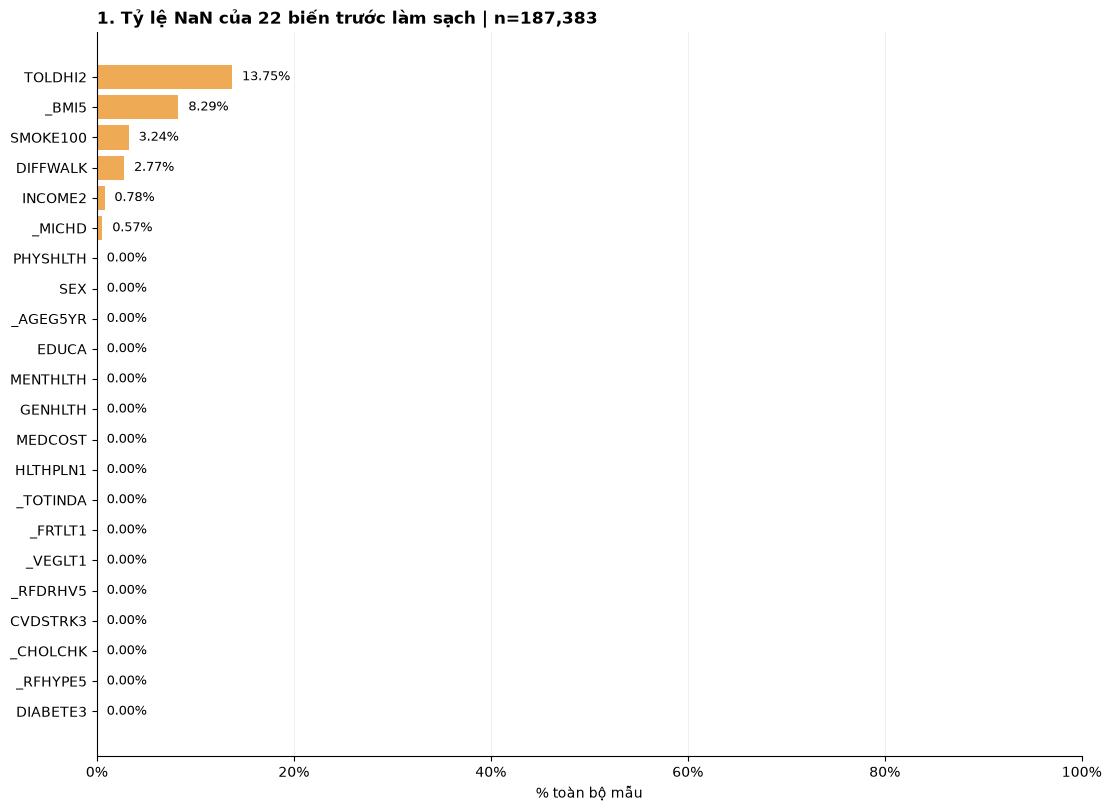

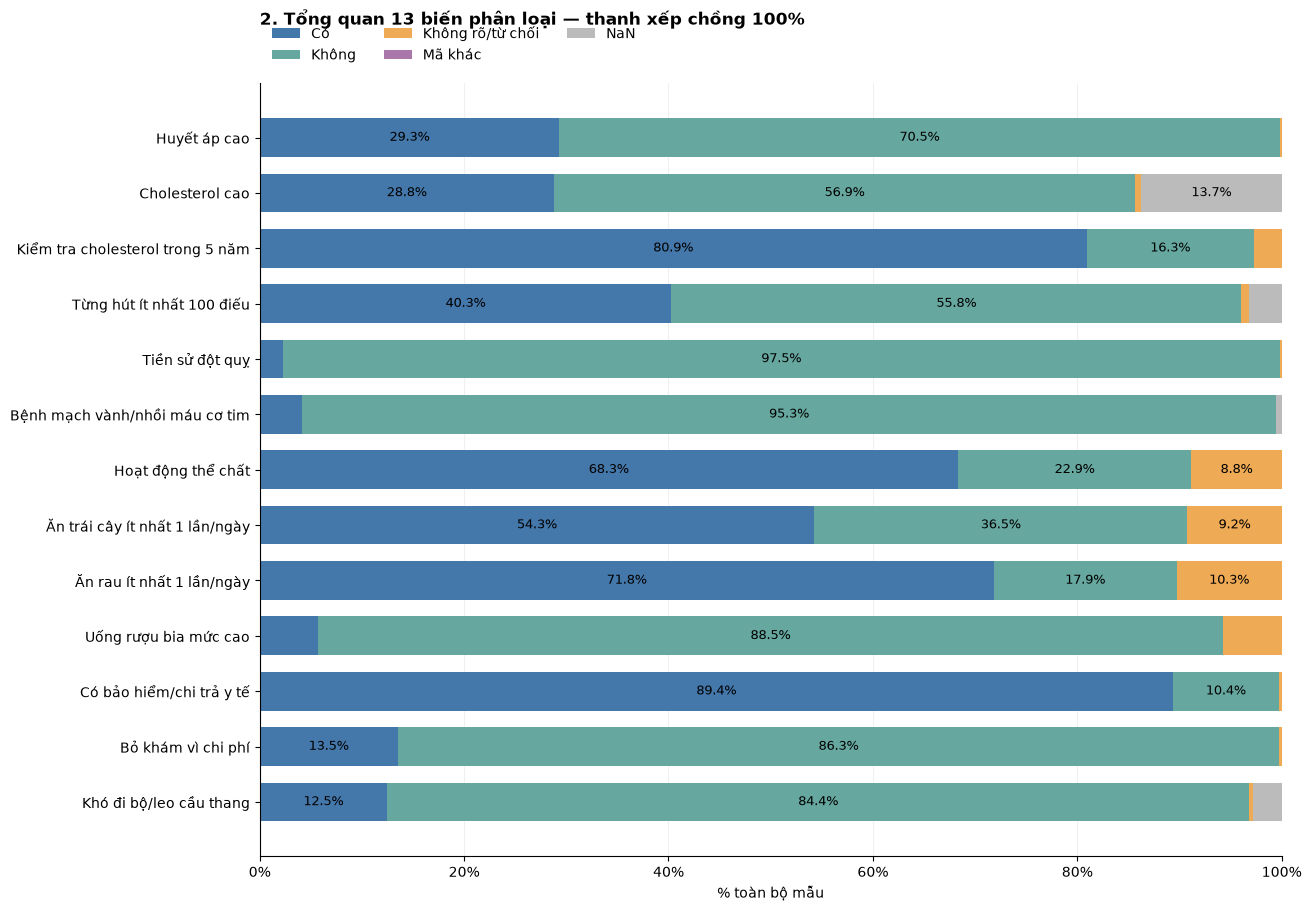

**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.

label,Có,Không,Không rõ/từ chối,Mã khác,NaN
Huyết áp cao,29.32,70.48,0.20,0.0,0.00
Cholesterol cao,28.78,56.89,0.58,0.0,13.75
Kiểm tra cholesterol trong 5 năm,80.93,16.35,2.72,0.0,0.00
Từng hút ít nhất 100 điếu,40.28,55.78,0.69,0.0,3.24
Tiền sử đột quỵ,2.28,97.50,0.21,0.0,0.00
Bệnh mạch vành/nhồi máu cơ tim,4.16,95.27,0.00,0.0,0.57
Hoạt động thể chất,68.31,22.86,8.83,0.0,0.00
Ăn trái cây ít nhất 1 lần/ngày,54.25,36.52,9.22,0.0,0.00
Ăn rau ít nhất 1 lần/ngày,71.83,17.90,10.27,0.0,0.00
Uống rượu bia mức cao,5.71,88.53,5.76,0.0,0.00


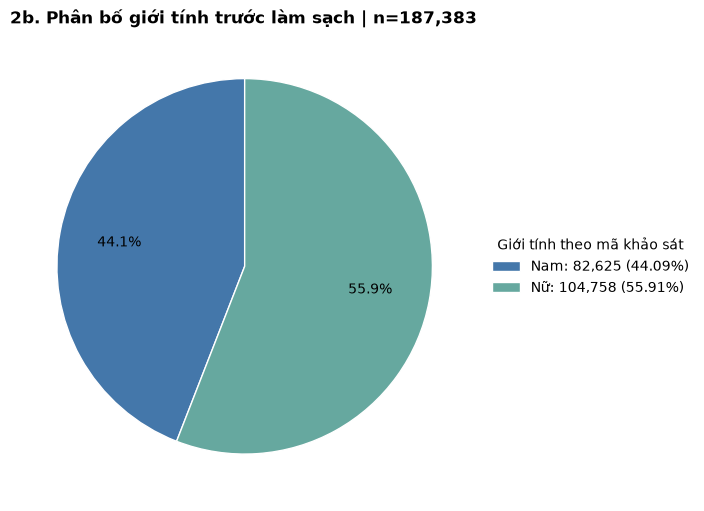

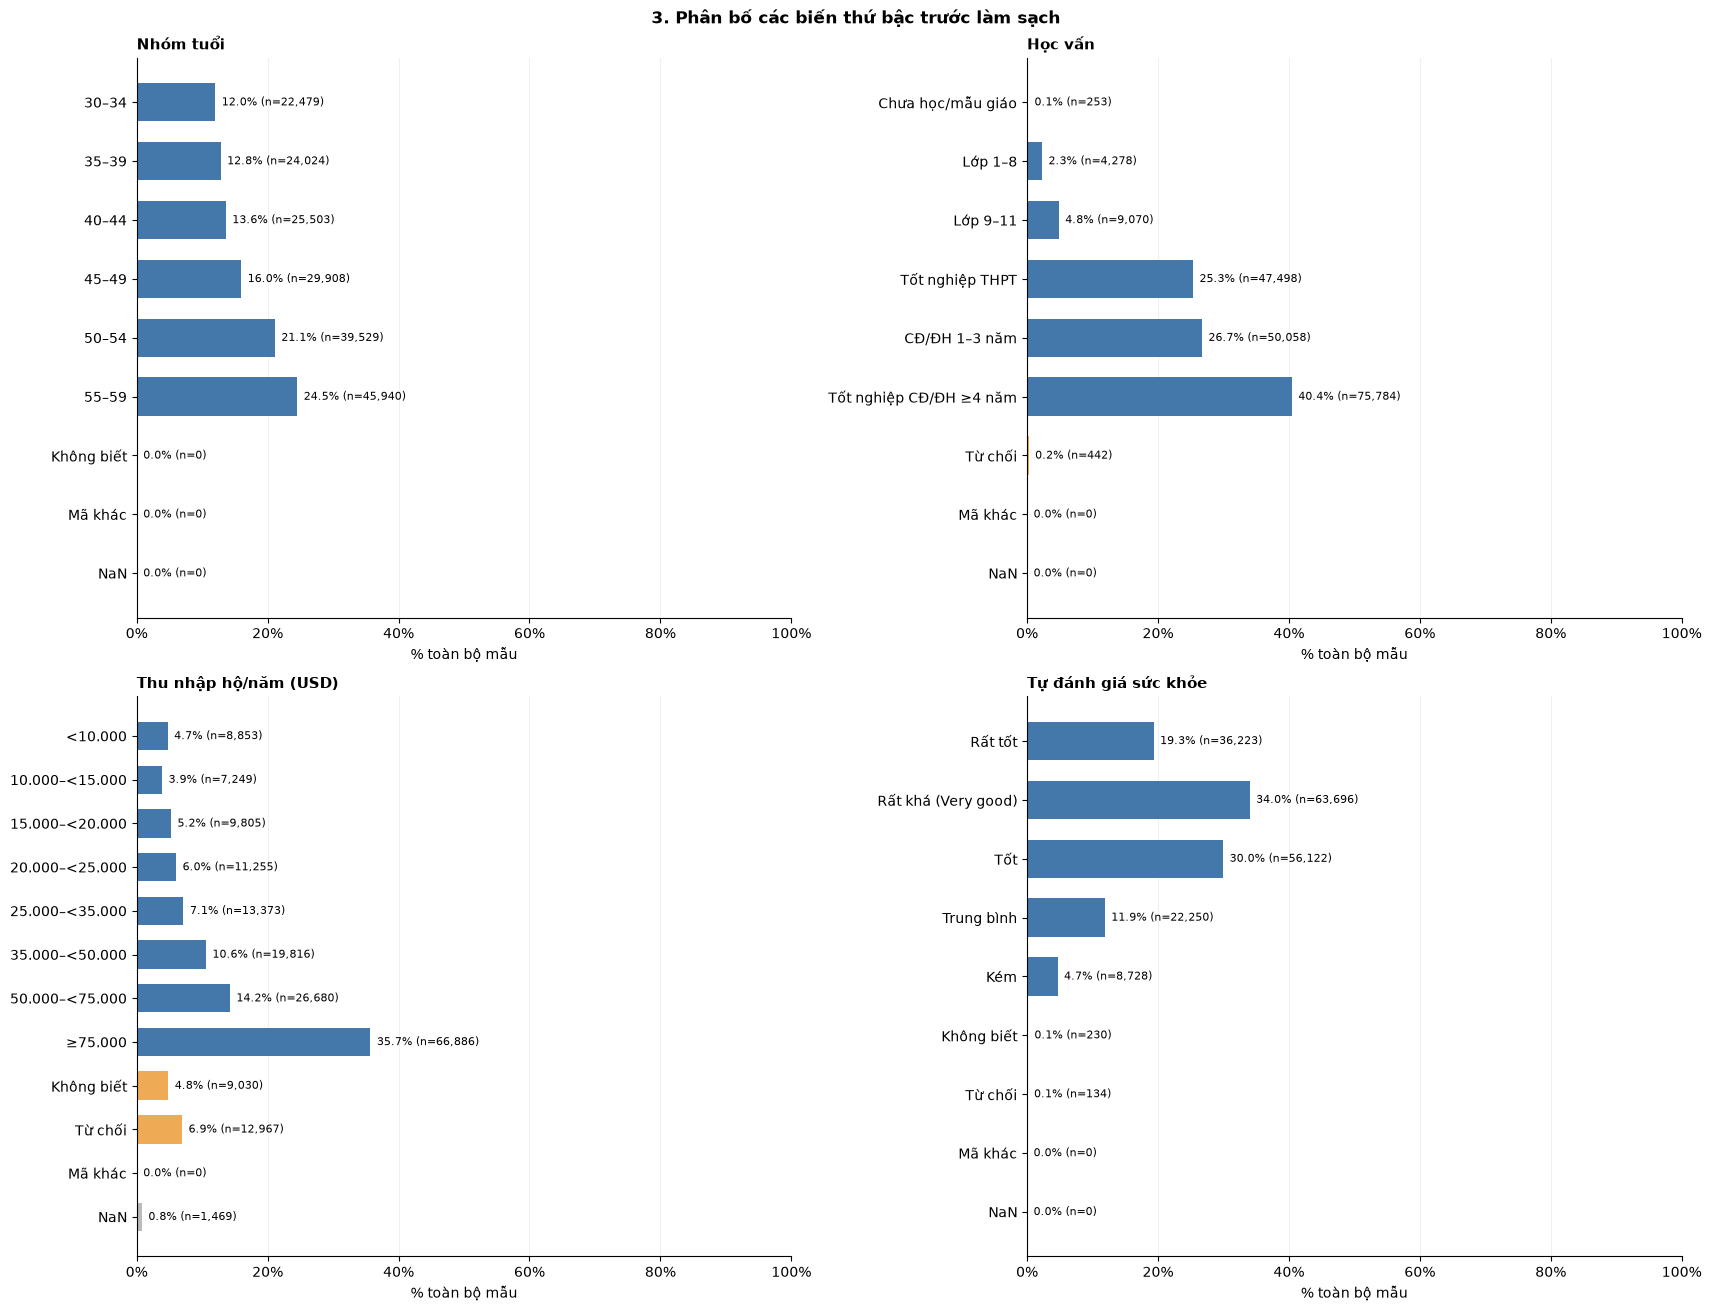

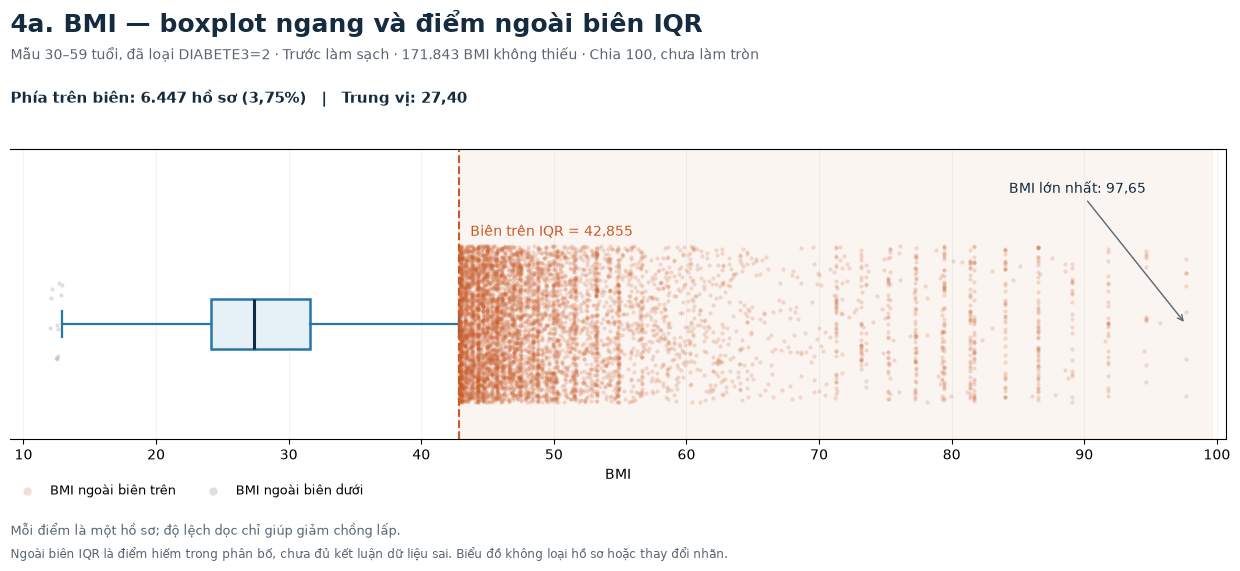

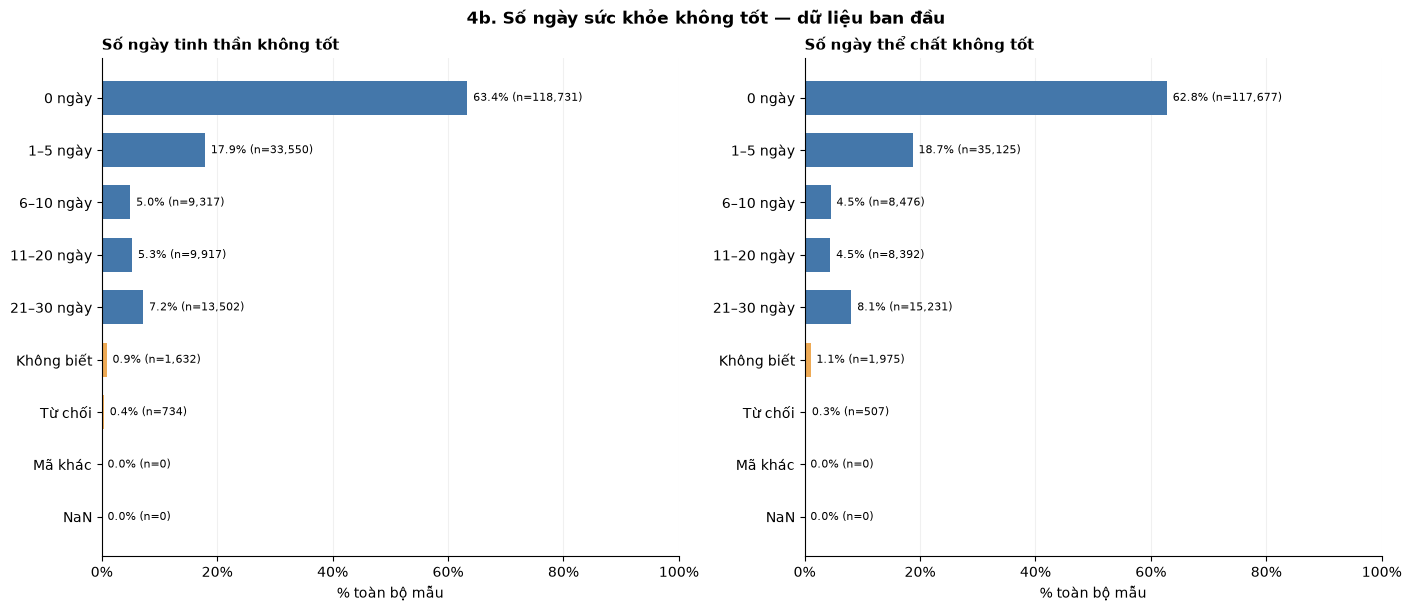

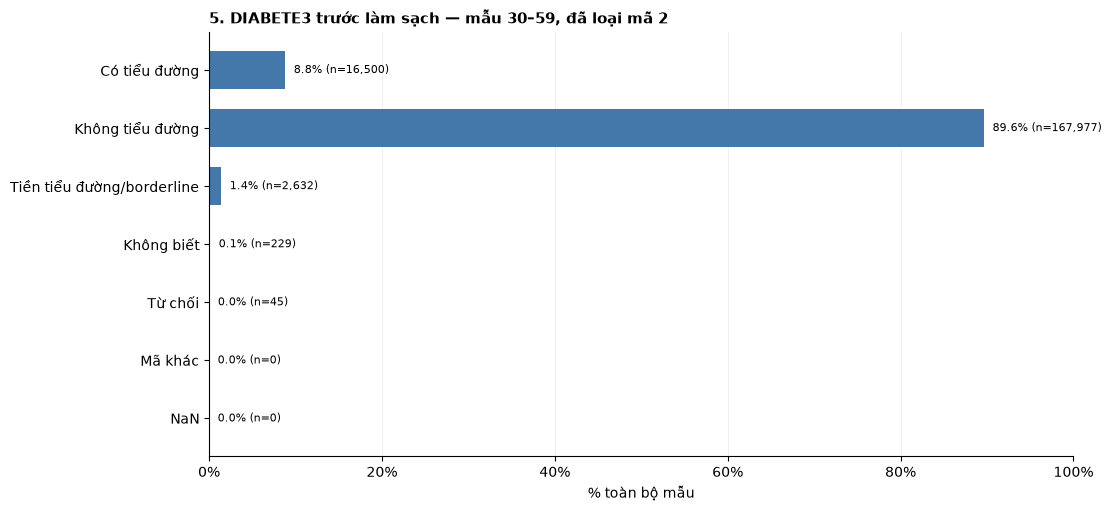

**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. NaN và mã không biết/từ chối là hai loại khác nhau. BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. **Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**

In [1]:
# TỔNG QUAN DỮ LIỆU BAN ĐẦU — MỤC 2.2
# Chỉ đổi nhãn/đơn vị để hiển thị; không sửa df_selected_raw.
def plot_initial_bmi_boxplot(raw):
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mticker

    bmi = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
    bmi_stats=prep_bmi_stats('raw_scope','_BMI5/100.0')
    if bmi_stats['n']==0:
        raise ValueError('BMI không có giá trị quan sát trong mẫu nghiên cứu.')
    q1, q3 = prep_quantile('raw_scope','_BMI5/100.0',.25), prep_quantile('raw_scope','_BMI5/100.0',.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    right = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5/100.0>? ORDER BY _source_row',(hi,))['BMI'].to_numpy()
    left = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5/100.0<? ORDER BY _source_row',(lo,))['BMI'].to_numpy()
    fmt = lambda n: f'{int(n):,}'.replace(',', '.')
    decimal = lambda v, d=2: f'{v:.{d}f}'.replace('.', ',')
    blue, orange, gray, pale = '#2676A8', '#C85A27', '#586573', '#E5F0F7'
    subtitle = (f'Mẫu 30–59 tuổi, đã loại DIABETE3=2 · Trước làm sạch · '
                f'{fmt(len(bmi))} BMI không thiếu · Chia 100, chưa làm tròn')
    footer = ('Ngoài biên IQR là điểm hiếm trong phân bố, chưa đủ kết luận dữ liệu sai. '
              'Biểu đồ không loại hồ sơ hoặc thay đổi nhãn.')
    fig,ax=plt.subplots(figsize=(13.5,5.8))
    fig.subplots_adjust(left=.07,right=.97,bottom=.23,top=.73)
    fig.suptitle('4a. BMI — boxplot ngang và điểm ngoài biên IQR',x=.07,ha='left',y=.97,
        fontsize=18,fontweight='bold',color='#152C40')
    fig.text(.07,.885,subtitle,fontsize=10,color=gray)
    ax.axvspan(hi,bmi_stats['maximum']+2,color=orange,alpha=.06,zorder=0)
    ax.boxplot(bmi.to_numpy(),orientation='horizontal',positions=[0],widths=.22,
        patch_artist=True,showfliers=False,
        boxprops={'facecolor':pale,'edgecolor':blue,'linewidth':1.8},
        whiskerprops={'color':blue,'linewidth':1.6},capprops={'color':blue,'linewidth':1.6},
        medianprops={'color':'#102C42','linewidth':2.2},manage_ticks=False)
    rng=np.random.default_rng(42)
    for values,color,label in [(right,orange,'BMI ngoài biên trên'),(left,gray,'BMI ngoài biên dưới')]:
        ax.scatter(values,rng.uniform(-.34,.34,len(values)),s=9,alpha=.20,color=color,
            linewidths=0,rasterized=True,label=label,zorder=3)
    ax.axvline(hi,color=orange,linestyle='--',linewidth=1.5)
    ax.annotate(f'Biên trên IQR = {decimal(hi,3)}',xy=(hi,.40),xytext=(8,0),
        textcoords='offset points',color=orange,fontsize=10,va='center')
    ax.annotate(f'BMI lớn nhất: {decimal(bmi_stats['maximum'])}',xy=(bmi_stats['maximum'],0),
        xytext=(bmi_stats['maximum']-3,.57),ha='right',fontsize=10,color='#152C40',
        arrowprops={'arrowstyle':'->','color':gray,'linewidth':1})
    ax.set(xlabel='BMI',yticks=[],ylim=(-.5,.76),xlim=(max(0,bmi_stats['minimum']-3),bmi_stats['maximum']+3))
    ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
    ax.grid(axis='x',alpha=.15);ax.spines['left'].set_visible(False)
    handles,labels=ax.get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower left',bbox_to_anchor=(.065,.11),ncol=2,
        frameon=False,fontsize=9,markerscale=2)
    fig.text(.07,.81,
        f'Phía trên biên: {fmt(len(right))} hồ sơ ({decimal(len(right)/len(bmi)*100)}%)'
        f'   |   Trung vị: {decimal(prep_quantile('raw_scope','_BMI5/100.0',.5))}',fontsize=11,fontweight='bold',color='#152C40')
    fig.text(.07,.065,'Mỗi điểm là một hồ sơ; độ lệch dọc chỉ giúp giảm chồng lấp.',fontsize=9,color=gray)
    fig.text(.07,.025,footer,fontsize=8.6,color=gray)
    plt.show()
    plt.close(fig)


def plot_initial_overview(raw):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    n = len(raw)
    if n == 0:
        raise ValueError('Dữ liệu ban đầu chưa có dòng nào.')
    blue, teal, orange, gray = '#4477AA', '#66A89F', '#EEAA55', '#BBBBBB'
    display(Markdown(
        '### Biểu đồ tổng quan dữ liệu ban đầu (mục 2.2)\n'
        f'**Mẫu 30–59, đã loại DIABETE3=2: {n:,} dòng × {raw.shape[1]} cột.** '
        'Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. '
        'Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, '
        'không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        axis = 'x' if horizontal else 'y'
        ax.grid(axis=axis, alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def distribution(series, mapping):
        return prep_distribution(series,mapping)

    def barh(ax, counts, title):
        pct = counts / n * 100
        colors = [gray if k == 'NaN' else orange if k in
                  ['Không biết', 'Từ chối', 'Mã khác'] else blue for k in counts.index]
        bars = ax.barh(counts.index, pct, color=colors, height=.65)
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
        ax.set_xlabel('% toàn bộ mẫu')
        for b, p, count in zip(bars, pct, counts):
            ax.text(min(p + 1, 97), b.get_y()+b.get_height()/2,
                    f'{p:.1f}% (n={count:,})', va='center', fontsize=8,
                    ha='right' if p > 94 else 'left')
        style(ax, True)

    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
        # 1. NaN của toàn bộ 22 cột.
        missing = missing_table('raw_scope',SOURCE_COLS).set_index('Feature')['missing_percent'].sort_values()
        fig, ax = plt.subplots(figsize=(11, 8), layout='constrained')
        bars = ax.barh(missing.index, missing.values, color=orange)
        ax.set_xlim(0, 100)
        ax.set_title(f'1. Tỷ lệ NaN của 22 biến trước làm sạch | n={n:,}',
                     loc='left', fontweight='bold')
        ax.set_xlabel('% toàn bộ mẫu')
        for b, p in zip(bars, missing.values):
            ax.text(min(p+1, 98), b.get_y()+b.get_height()/2,
                    f'{p:.2f}%', va='center', fontsize=9)
        style(ax, True)
        plt.show()

        # 2. Các biến phân loại. Mã nguồn được đọc theo từng biến.
        specs = [
            ('_RFHYPE5', 'Huyết áp cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('TOLDHI2', 'Cholesterol cao', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_CHOLCHK', 'Kiểm tra cholesterol trong 5 năm', {1:'Có', 2:'Không', 3:'Không', 9:'Không rõ/từ chối'}),
            ('SMOKE100', 'Từng hút ít nhất 100 điếu', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('CVDSTRK3', 'Tiền sử đột quỵ', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_MICHD', 'Bệnh mạch vành/nhồi máu cơ tim', {1:'Có', 2:'Không'}),
            ('_TOTINDA', 'Hoạt động thể chất', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_FRTLT1', 'Ăn trái cây ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_VEGLT1', 'Ăn rau ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_RFDRHV5', 'Uống rượu bia mức cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('HLTHPLN1', 'Có bảo hiểm/chi trả y tế', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('MEDCOST', 'Bỏ khám vì chi phí', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('DIFFWALK', 'Khó đi bộ/leo cầu thang', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'})]
        categories = ['Có', 'Không', 'Không rõ/từ chối', 'Mã khác', 'NaN']
        rows = []
        for col, title, mapping in specs:
            rows.append(prep_distribution(raw[col],mapping,categories)/n*100)
        table = pd.DataFrame(rows, index=[title for _, title, _ in specs])
        fig, ax = plt.subplots(figsize=(13, 9), layout='constrained')
        left = np.zeros(len(table))
        for category, color in zip(categories, [blue, teal, orange, '#AA77AA', gray]):
            widths = table[category].to_numpy()
            ax.barh(table.index, widths, left=left, color=color, label=category, height=.7)
            for y, (start, width) in enumerate(zip(left, widths)):
                if width >= 6:
                    ax.text(start+width/2, y, f'{width:.1f}%', ha='center', va='center', fontsize=9)
            left += widths
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel('% toàn bộ mẫu')
        ax.set_title('2. Tổng quan 13 biến phân loại — thanh xếp chồng 100%',
                     loc='left', fontweight='bold', pad=42)
        ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False)
        style(ax, True)
        plt.show()
        display(Markdown('**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. '
                         'Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.'))
        display(table.round(2))

        # 2b. Giới tính tách riêng thành biểu đồ tròn, giữ cả NaN/mã khác.
        sex_counts = distribution(raw['SEX'], {1:'Nam', 2:'Nữ', 9:'Không rõ/từ chối'})
        sex_counts = sex_counts[sex_counts > 0]
        sex_palette = {'Nam':blue, 'Nữ':teal, 'Không rõ/từ chối':orange,
                       'Mã khác':'#AA77AA', 'NaN':gray}
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        wedges, _, _ = ax.pie(sex_counts.values,
            colors=[sex_palette[k] for k in sex_counts.index], startangle=90,
            autopct=lambda p: f'{p:.1f}%' if p >= 1 else '',
            pctdistance=.68, wedgeprops={'edgecolor':'white', 'linewidth':1})
        ax.legend(wedges, [f'{k}: {v:,} ({v/n*100:.2f}%)'
                          for k,v in sex_counts.items()],
                  title='Giới tính theo mã khảo sát', loc='center left',
                  bbox_to_anchor=(1, .5), frameon=False)
        ax.set_title(f'2b. Phân bố giới tính trước làm sạch | n={n:,}',
                     loc='left', fontweight='bold')
        ax.set_aspect('equal')
        plt.show()

        # 3. Biến thứ bậc, giữ đúng thứ tự và tách mã phản hồi.
        age = ['30–34','35–39','40–44','45–49','50–54','55–59']
        ordinal = [
            ('_AGEG5YR', 'Nhóm tuổi', {**dict(enumerate(age, 3)), 14:'Không biết'}),
            ('EDUCA', 'Học vấn', {1:'Chưa học/mẫu giáo', 2:'Lớp 1–8', 3:'Lớp 9–11',
                4:'Tốt nghiệp THPT', 5:'CĐ/ĐH 1–3 năm', 6:'Tốt nghiệp CĐ/ĐH ≥4 năm', 9:'Từ chối'}),
            ('INCOME2', 'Thu nhập hộ/năm (USD)', {1:'<10.000', 2:'10.000–<15.000',
                3:'15.000–<20.000', 4:'20.000–<25.000', 5:'25.000–<35.000',
                6:'35.000–<50.000', 7:'50.000–<75.000', 8:'≥75.000', 77:'Không biết', 99:'Từ chối'}),
            ('GENHLTH', 'Tự đánh giá sức khỏe', {1:'Rất tốt', 2:'Rất khá (Very good)',
                3:'Tốt', 4:'Trung bình', 5:'Kém', 7:'Không biết', 9:'Từ chối'})]
        fig, axes = plt.subplots(2, 2, figsize=(17, 13), layout='constrained')
        fig.suptitle('3. Phân bố các biến thứ bậc trước làm sạch', fontweight='bold')
        for ax, (col, title, mapping) in zip(axes.flat, ordinal):
            barh(ax, distribution(raw[col], mapping), title)
        plt.show()

        # 4a. Boxplot BMI: giữ toàn bộ miền và vẽ các điểm ngoài biên.
        plot_initial_bmi_boxplot(raw)

        # 4b. Hai biểu đồ số ngày giữ cách đếm và giải mã hiện tại.
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
        days_mapping = {0:'0 ngày', 88:'0 ngày',
                        **{i:'1–5 ngày' for i in range(1, 6)},
                        **{i:'6–10 ngày' for i in range(6, 11)},
                        **{i:'11–20 ngày' for i in range(11, 21)},
                        **{i:'21–30 ngày' for i in range(21, 31)},
                        77:'Không biết', 99:'Từ chối'}
        for ax, col, title in zip(axes, ['MENTHLTH', 'PHYSHLTH'],
                                  ['Số ngày tinh thần không tốt', 'Số ngày thể chất không tốt']):
            barh(ax, distribution(raw[col], days_mapping), title)
        fig.suptitle('4b. Số ngày sức khỏe không tốt — dữ liệu ban đầu', fontweight='bold')
        plt.show()

        # 5. Nhãn gốc: chưa gộp Diabetes_binary.
        target_map = {1:'Có tiểu đường', 3:'Không tiểu đường',
                      4:'Tiền tiểu đường/borderline', 7:'Không biết', 9:'Từ chối'}
        fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
        barh(ax, distribution(raw['DIABETE3'], target_map),
             '5. DIABETE3 trước làm sạch — mẫu 30–59, đã loại mã 2')
        plt.show()
        display(Markdown('**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; '
            'các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. '
            'NaN và mã không biết/từ chối là hai loại khác nhau. '
            'BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. '
            '**Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**'))

plot_initial_overview(df_selected_raw)


### NHẬN XÉT VÀ QUAN SÁT (Mục 2.2)

- Nguồn toàn bộ được kiểm tra riêng; nhật ký chọn phạm vi ghi số hồ sơ còn lại sau chọn tuổi 30–59 và loại tiểu đường chỉ khi mang thai.
- Các biểu đồ ban đầu dùng `df_selected_raw`: mẫu đã chọn, trước xử lý thiếu và mã khảo sát. Tỷ lệ mô tả mẫu này, chưa có trọng số khảo sát.
- Age là sáu nhóm tuổi mã 3–8. Thu nhập, học vấn và sức khỏe chung vẫn là mã thứ bậc.
- Phân biệt NaN với mã không biết/từ chối; không gộp các trường hợp đó thành câu trả lời “không”. BMI chỉ đổi đơn vị phục vụ hiển thị ở bước này.
- Nhãn gốc còn mã 1, 3, 4, có thể có 7/9/NaN; mã 2 đã loại ở bước chọn mẫu. Sau làm sạch, gộp 1 và 4 thành lớp 1; mã 3 thành lớp 0.
- Không diễn giải phân bố như nguy cơ phát bệnh tương lai hoặc kết luận nhân quả.


# III. Làm sạch và tiền xử lý dữ liệu

SQLite thực hiện lọc, đổi mã, kiểm tra missing/duplicate, kiểm tra miền giá trị và tổng hợp trước/sau. Python đọc XPT/CSV, chuyển kết quả SQL thành dữ liệu vẽ, ép kiểu int16 khi chuyển kết quả thành DataFrame và kiểm tra đối chiếu. Sau phần này kết nối được đóng; toàn bộ EDA, chia tập, feature engineering, huấn luyện và đánh giá dùng pandas/NumPy cùng các thư viện mô hình.


#### CHECK & HANDLE DUPLICATE DATA

Kiểm tra duplicate trên toàn bộ 330 cột nguồn, 22 cột toàn nguồn và 22 cột của mẫu 30–59 đã loại DIABETE3=2. Sau chuyển mã, làm tròn BMI và gộp nhãn, kiểm tra lại trên đầu ra. Bản chính giữ hồ sơ trùng đặc điểm; bản xóa duplicate ở mục 3.4 phục vụ đối chiếu.

Nhóm thực hiện cả phát hiện và loại duplicate trong phần tiền xử lý. Bản chính giữ các hồ sơ trùng đặc điểm vì chưa đủ căn cứ xác định chúng thuộc cùng một người; bản đối chiếu dùng `GROUP BY` 22 cột và `MIN(_source_row)` trong SQL để giữ lần xuất hiện đầu tiên. Hai bản được giữ riêng trong bộ nhớ để đối chiếu ở phần phân tích và mô hình.


In [7]:
for name,cols in [('source_data',source_columns),('selected_all',SOURCE_COLS),('raw_scope',SOURCE_COLS)]:
    print(name, 'duplicate ngoài lần đầu:', duplicate_count(name,cols))
scope_query="""SELECT _AGEG5YR AS Age,COUNT(*) AS n,
SUM(DIABETE3 IN (1,4)) AS positive_count
FROM raw_scope GROUP BY _AGEG5YR ORDER BY _AGEG5YR"""
print(scope_query);display(prep_table(scope_query))


source_data duplicate ngoài lần đầu: 0
selected_all duplicate ngoài lần đầu: 7098
raw_scope duplicate ngoài lần đầu: 4385
SELECT _AGEG5YR AS Age,COUNT(*) AS n,
SUM(DIABETE3 IN (1,4)) AS positive_count
FROM raw_scope GROUP BY _AGEG5YR ORDER BY _AGEG5YR


,Age,n,positive_count
0,3.0,22479,670
1,4.0,24024,1208
2,5.0,25503,1851
3,6.0,29908,3040
4,7.0,39529,5173
5,8.0,45940,7190


**NHẬN XÉT (Mục 3.1):**

**Kết quả mẫu mới:** Trước clean có 4.385 dòng trùng trên 22 cột. Sau clean, bản chính có 116.662 dòng, trong đó 13.836 dòng trùng ngoài lần đầu; bản đối chiếu còn 102.826 dòng. Trong bản chính, lớp 0 có 103.921 và lớp 1 có 12.741 dòng.

Các số duplicate trước làm sạch được in ở trên. Bản chính giữ duplicate vì hai người có thể trùng đặc điểm trong 22 cột; việc trùng chưa chứng minh cùng một người. Mục 3.4 trình bày số dòng và tỷ lệ nhãn của hai bản sau làm sạch, tính lại cho mẫu mới. Chuyển mã, làm tròn BMI và gộp nhãn có thể tạo thêm các tổ hợp trùng.


#### CHECK & HANDLE MISSING VALUES

Nhóm thống kê số ô NaN và tỷ lệ NaN của từng cột trong 22 biến được chọn. Sau đó, nhóm xóa dòng chứa NaN, xử lý mã không biết/từ chối trả lời và ghi lại số dòng bị loại ở từng bước. Mã 88 trong `MENTHLTH` và `PHYSHLTH` được đổi thành 0 ngày.


**Ghi chú về lý do loại dòng và quy trình kế thừa:** Nhóm kế thừa hoàn toàn cách xử lý NaN/NULL bằng loại dòng (complete-case deletion) của notebook tham khảo Alex Teboul trên bộ 22 biến được chọn. Các dòng thiếu nhãn phân loại tiểu đường ở cột nguồn `DIABETE3` được loại vì không có nhãn để huấn luyện và đánh giá bài toán phân loại có giám sát; nhóm không tự suy đoán hoặc điền nhãn cho các dòng này. Trong code SQL, điều kiện `IS NOT NULL` áp dụng cho cả 22 cột, tương đương quy tắc complete-case trước đây: loại cả dòng thiếu biến đầu vào, không chỉ dòng thiếu nhãn.

**Phạm vi đếm:** Chỉ `df_selected_raw` (30–59, không có DIABETE3=2). Số bị loại do chọn phạm vi nằm ở nhật ký riêng, không tính thành mất mẫu do missing. Giữ nguyên `dropna()` trên cả 22 cột và các quy tắc mã phản hồi của bản trước.


In [8]:
nan_drop_columns=['TOLDHI2','_BMI5','SMOKE100','_MICHD']
PREP_DB.execute('CREATE TABLE drop4 AS SELECT * FROM raw_scope WHERE '+' AND '.join(qi(c)+' IS NOT NULL' for c in nan_drop_columns))
remaining_nan_columns=[c for c in SOURCE_COLS if c not in nan_drop_columns]
remaining_nan_summary=missing_table('drop4',remaining_nan_columns)
display(remaining_nan_summary)
print('Trước/sau lọc bốn biến:',prep_scalar('SELECT COUNT(*) FROM raw_scope'),prep_scalar('SELECT COUNT(*) FROM drop4'))
print('Dòng còn NaN:',prep_scalar('SELECT COUNT(*) FROM drop4 WHERE '+' OR '.join(qi(c)+' IS NULL' for c in remaining_nan_columns)))


Trước/sau lọc bốn biến: 187383 145580
Dòng còn NaN: 2


,Feature,missing_count,missing_percent
0,DIABETE3,0,0.000000
1,_RFHYPE5,0,0.000000
2,_CHOLCHK,0,0.000000
3,CVDSTRK3,0,0.000000
4,_TOTINDA,0,0.000000
5,_FRTLT1,0,0.000000
6,_VEGLT1,0,0.000000
7,_RFDRHV5,0,0.000000
8,HLTHPLN1,0,0.000000
9,MEDCOST,0,0.000000


In [9]:
missing_summary=missing_table('raw_scope',SOURCE_COLS).set_index('Feature').rename(columns={'missing_count':'Số ô NaN','missing_percent':'Tỷ lệ NaN (%)'}).sort_values('Số ô NaN',ascending=False)
display(missing_summary)
PREP_DB.execute('CREATE TABLE clean_work AS SELECT * FROM raw_scope')
audit_rows=[]
def sql_clean_step(label,condition='1=1',column=None,expression=None):
    before=prep_scalar('SELECT COUNT(*) FROM clean_work')
    if column is not None and expression is not None: PREP_DB.execute(f'UPDATE clean_work SET {qi(column)}={expression}')
    PREP_DB.execute(f'DELETE FROM clean_work WHERE NOT ({condition})')
    after=prep_scalar('SELECT COUNT(*) FROM clean_work')
    audit_rows.append([label,before,before-after,after])
sql_clean_step('NaN',' AND '.join(qi(c)+' IS NOT NULL' for c in SOURCE_COLS))
sql_clean_step('DIABETE3','"DIABETE3" NOT IN (7,9)','DIABETE3','CASE "DIABETE3" WHEN 3 THEN 0 WHEN 1 THEN 1 WHEN 4 THEN 1 ELSE "DIABETE3" END')
sql_clean_step('_RFHYPE5','"_RFHYPE5" NOT IN (9)','_RFHYPE5','CASE "_RFHYPE5" WHEN 1 THEN 0 WHEN 2 THEN 1 ELSE "_RFHYPE5" END')
sql_clean_step('TOLDHI2','"TOLDHI2" NOT IN (7,9)','TOLDHI2','CASE "TOLDHI2" WHEN 2 THEN 0 ELSE "TOLDHI2" END')
sql_clean_step('_CHOLCHK','"_CHOLCHK" NOT IN (9)','_CHOLCHK','CASE "_CHOLCHK" WHEN 3 THEN 0 WHEN 2 THEN 0 ELSE "_CHOLCHK" END')
sql_clean_step('_BMI5','1=1','_BMI5','CASE WHEN CAST(_BMI5 AS INTEGER)%100=50 THEN CAST(_BMI5/100 AS INTEGER)+(CAST(_BMI5/100 AS INTEGER)%2) ELSE ROUND(_BMI5/100.0,0) END')
sql_clean_step('SMOKE100','"SMOKE100" NOT IN (7,9)','SMOKE100','CASE "SMOKE100" WHEN 2 THEN 0 ELSE "SMOKE100" END')
sql_clean_step('CVDSTRK3','"CVDSTRK3" NOT IN (7,9)','CVDSTRK3','CASE "CVDSTRK3" WHEN 2 THEN 0 ELSE "CVDSTRK3" END')
sql_clean_step('_MICHD','1=1','_MICHD','CASE "_MICHD" WHEN 2 THEN 0 ELSE "_MICHD" END')
sql_clean_step('_TOTINDA','"_TOTINDA" NOT IN (9)','_TOTINDA','CASE "_TOTINDA" WHEN 2 THEN 0 ELSE "_TOTINDA" END')
sql_clean_step('_FRTLT1','"_FRTLT1" NOT IN (9)','_FRTLT1','CASE "_FRTLT1" WHEN 2 THEN 0 ELSE "_FRTLT1" END')
sql_clean_step('_VEGLT1','"_VEGLT1" NOT IN (9)','_VEGLT1','CASE "_VEGLT1" WHEN 2 THEN 0 ELSE "_VEGLT1" END')
sql_clean_step('_RFDRHV5','"_RFDRHV5" NOT IN (9)','_RFDRHV5','CASE "_RFDRHV5" WHEN 1 THEN 0 WHEN 2 THEN 1 ELSE "_RFDRHV5" END')
sql_clean_step('HLTHPLN1','"HLTHPLN1" NOT IN (7,9)','HLTHPLN1','CASE "HLTHPLN1" WHEN 2 THEN 0 ELSE "HLTHPLN1" END')
sql_clean_step('MEDCOST','"MEDCOST" NOT IN (7,9)','MEDCOST','CASE "MEDCOST" WHEN 2 THEN 0 ELSE "MEDCOST" END')
sql_clean_step('GENHLTH','"GENHLTH" NOT IN (7,9)','GENHLTH',None)
sql_clean_step('MENTHLTH','"MENTHLTH" NOT IN (77,99)','MENTHLTH','CASE "MENTHLTH" WHEN 88 THEN 0 ELSE "MENTHLTH" END')
sql_clean_step('PHYSHLTH','"PHYSHLTH" NOT IN (77,99)','PHYSHLTH','CASE "PHYSHLTH" WHEN 88 THEN 0 ELSE "PHYSHLTH" END')
sql_clean_step('DIFFWALK','"DIFFWALK" NOT IN (7,9)','DIFFWALK','CASE "DIFFWALK" WHEN 2 THEN 0 ELSE "DIFFWALK" END')
sql_clean_step('SEX','1=1','SEX','CASE "SEX" WHEN 2 THEN 0 ELSE "SEX" END')
sql_clean_step('_AGEG5YR','"_AGEG5YR" NOT IN (14)','_AGEG5YR',None)
sql_clean_step('EDUCA','"EDUCA" NOT IN (9)','EDUCA',None)
sql_clean_step('INCOME2','"INCOME2" NOT IN (77,99)','INCOME2',None)
PREP_DB.commit()
brfss_df_selected=prep_frame('clean_work')
display(pd.DataFrame(audit_rows,columns=['step','before','removed','after']))


,Số ô NaN,Tỷ lệ NaN (%)
Feature,,
TOLDHI2,25760,13.747245
_BMI5,15540,8.293175
SMOKE100,6080,3.244691
DIFFWALK,5199,2.774531
INCOME2,1469,0.783956
_MICHD,1065,0.568355
_CHOLCHK,0,0.000000
_RFHYPE5,0,0.000000
DIABETE3,0,0.000000


,step,before,removed,after
0,NaN,187383,41805,145578
1,DIABETE3,145578,127,145451
2,_RFHYPE5,145451,179,145272
3,TOLDHI2,145272,841,144431
4,_CHOLCHK,144431,1316,143115
5,_BMI5,143115,0,143115
6,SMOKE100,143115,749,142366
7,CVDSTRK3,142366,210,142156
8,_MICHD,142156,0,142156
9,_TOTINDA,142156,6987,135169


**NHẬN XÉT VÀ LÝ DO LỰA CHỌN (Mục 3.2):**

**Kết quả mẫu mới:** 187.383 dòng trước clean có 55.113 ô NaN trên 41.805 dòng. Sau dropna còn 145.578 dòng; các bước mã khảo sát loại tiếp 28.916 dòng, còn 116.662 dòng. Tổng giảm do làm sạch là 37,74% của mẫu đã chọn; không bao gồm hồ sơ ngoài tuổi hoặc DIABETE3=2.

- Bảng missing và nhật ký ở trên tính trực tiếp trên mẫu nghiên cứu, ghi riêng số dòng loại do NaN và từng mã khảo sát. Một dòng nhiều lỗi chỉ được đếm ở bước đầu tiên loại dòng đó.
- Giữ complete-case deletion trên 22 cột theo quy trình hiện tại; không điền mean/median/mode, không suy đoán nhãn.
- Mã 88 của MENTHLTH/PHYSHLTH đổi thành 0 ngày; mã 77/99 bị loại. Đổi mã 88 không phải điền missing.
- Số dòng mất do tuổi hoặc loại DIABETE3=2 đã được ghi trước bước này và không nằm trong số dòng mất do làm sạch.

**Giới hạn:** Complete-case giữ câu trả lời quan sát được, nhưng chưa chứng minh tối ưu hoặc đại diện. Theo [CDC codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), TOLDHI2 có missing do nhánh câu hỏi; vì vậy chọn HighChol và loại dòng thiếu có thể loại người chưa kiểm tra cholesterol. Không gán HighChol=0 cho người chưa xét nghiệm. Chưa khẳng định kết quả áp dụng cho nhóm bị loại hoặc toàn bộ người tham gia.

Báo cáo giữ quy tắc loại dòng thiếu đã thống nhất và ghi rõ giới hạn do mất mẫu.


#### DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm đổi tên 22 cột nguồn sang tên dùng trong phân tích và gộp nhãn mục tiêu thành hai lớp. Trước khi chuyển sang `int16`, nhóm kiểm tra giá trị thiếu, giá trị không hữu hạn, phần thập phân, miền giá trị của từng biến và giới hạn lưu trữ int16 (−32.768 đến 32.767). Sau chuyển kiểu, nhóm đối chiếu để xác nhận các giá trị không thay đổi.


In [10]:
valid_ranges={'GenHlth':(1,5),'MentHlth':(0,30),'PhysHlth':(0,30),'Age':(3,8),'Education':(1,6),'Income':(1,8)}
select=', '.join(qi(old)+' AS '+qi(new) for old,new in rename_dict.items())
PREP_DB.execute('CREATE TABLE clean_sql AS SELECT _source_row,'+select+' FROM clean_work')
check_rows=[]
for col in rename_dict.values():
    field=qi(col)
    domain=f'{field} BETWEEN {valid_ranges[col][0]} AND {valid_ranges[col][1]}' if col in valid_ranges else (f'{field}>0' if col=='BMI' else f'{field} IN (0,1)')
    check_rows.append(prep_table(f"SELECT ? AS 'Biến',SUM({field} IS NULL) AS Missing,SUM({field} IS NOT NULL AND ABS({field})>1.7976931348623157e308) AS 'Non-finite',SUM({field}!=CAST({field} AS INTEGER)) AS 'Thập phân ảo',SUM(NOT ({domain})) AS 'Vi phạm logic/Khoảng' FROM clean_sql",(col,)))
validity_summary=pd.concat(check_rows,ignore_index=True)
display(validity_summary)
total_errors=int(validity_summary.iloc[:,1:].to_numpy().sum());assert total_errors==0
assert prep_scalar('SELECT COUNT(*) FROM clean_sql WHERE '+' OR '.join(f'{qi(c)} NOT BETWEEN -32768 AND 32767' for c in rename_dict.values()))==0
# SQLite INTEGER is not int16; enforce int16 only when materializing/exporting the validated SQL values.
df_before_cast=prep_frame('clean_sql')
df_clean=df_before_cast.astype('int16')
assert np.array_equal(df_before_cast.to_numpy(),df_clean.to_numpy())
assert prep_scalar('SELECT COUNT(*) FROM clean_sql c JOIN raw_scope r USING(_source_row) WHERE r.DIABETE3 NOT IN (1,3,4) OR c.Diabetes_binary != CASE r.DIABETE3 WHEN 3 THEN 0 ELSE 1 END')==0
print('22 cột hợp lệ; giữ duplicate:',duplicate_count('clean_sql',list(rename_dict.values())))


22 cột hợp lệ; giữ duplicate: 13836


,Biến,Missing,Non-finite,Thập phân ảo,Vi phạm logic/Khoảng
0,Diabetes_binary,0,0,0,0
1,HighBP,0,0,0,0
2,HighChol,0,0,0,0
3,CholCheck,0,0,0,0
4,BMI,0,0,0,0
5,Smoker,0,0,0,0
6,Stroke,0,0,0,0
7,HeartDiseaseorAttack,0,0,0,0
8,PhysActivity,0,0,0,0
9,Fruits,0,0,0,0


**NHẬN XÉT (Mục 3.3):**

**Kết quả thực thi:** 22 cột int16, 0 ô thiếu và 0 lỗi trong bảng kiểm tra; 116.662 dòng. Age chỉ có mã 3–8, nhãn khớp DIABETE3 nguồn của từng dòng.

Chỉ ép 22 cột sang int16 khi bảng kiểm tra có tổng lỗi bằng 0 và đối chiếu trước/sau chuyển kiểu khớp hoàn toàn. Age chỉ nhận mã 3–8; các miền khác giữ như bản trước. Đối chiếu lại nhãn với DIABETE3 của từng dòng nguồn xác nhận không còn mã 2 và gộp 1/4 đúng quy tắc.

BMI chia 100/làm tròn ở mục 3.2; ép kiểu không làm tròn thêm. BMI >0 là điều kiện kiểm tra hiện tại, không phải xác minh giá trị sinh học. Biến thứ bậc lưu số nguyên vẫn không phải đại lượng liên tục.

**Lưu trữ:** int16 giảm bộ nhớ phần dữ liệu số so với int32. CSV lưu văn bản nên không giữ dtype và không giảm dung lượng chỉ nhờ ép kiểu; khi đọc lại cần chỉ định `dtype='int16'`.


## 3.4. Đối chiếu phương án giữ và xóa duplicate

**Kết quả mẫu mới:** Xóa duplicate làm lớp 0 giảm 13.788 dòng và lớp 1 giảm 48 dòng. Tỷ lệ lớp 1 đổi từ 10,92% sang 12,34%; hai bản có lần lượt 116.662 và 102.826 dòng.

`df_clean` giữ tất cả các dòng qua làm sạch. `df_no_duplicates` nhận kết quả SQL giữ dòng có `MIN(_source_row)` trong từng nhóm trùng trên đủ 22 cột. Bảng dưới tính lại số lượng/tỷ lệ từng lớp của hai bản; không tái cân bằng mẫu.

Hai hồ sơ giống nhau chưa chứng minh cùng một người. Bản giữ duplicate là dữ liệu chính, bản xóa dùng đối chiếu. Việc chia Train/Test ở phần mô hình dùng nhóm 21 đặc trưng để tránh profile gốc giao nhau.


In [11]:
fields=','.join(qi(c) for c in rename_dict.values())
PREP_DB.execute('CREATE TABLE dedup_sql AS SELECT * FROM clean_sql WHERE _source_row IN (SELECT MIN(_source_row) FROM clean_sql GROUP BY '+fields+')')
df_no_duplicates=prep_frame('dedup_sql').astype('int16')
display(prep_table("SELECT 'Giữ duplicate' AS Dataset,Diabetes_binary,COUNT(*) AS n,100.0*COUNT(*)/(SELECT COUNT(*) FROM clean_sql) AS percent FROM clean_sql GROUP BY Diabetes_binary UNION ALL SELECT 'Bỏ duplicate',Diabetes_binary,COUNT(*),100.0*COUNT(*)/(SELECT COUNT(*) FROM dedup_sql) FROM dedup_sql GROUP BY Diabetes_binary"))


,Dataset,Diabetes_binary,n,percent
0,Giữ duplicate,0.0,103921,89.078706
1,Giữ duplicate,1.0,12741,10.921294
2,Bỏ duplicate,0.0,90133,87.655846
3,Bỏ duplicate,1.0,12693,12.344154


In [12]:
for name in ['source_data','selected_all','age_scope','raw_scope','clean_sql','dedup_sql']:
    print(name,prep_scalar(f'SELECT COUNT(*) FROM {name}'))


source_data 441456
selected_all 441456
age_scope 189770
raw_scope 187383
clean_sql 116662
dedup_sql 102826


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

**Kết quả mẫu mới:** BMI có 3.379 điểm ngoài biên IQR [12,00; 44,00], chiếm 2,90% bản chính. Các điểm này được giữ theo quy tắc hiện tại sau kiểm tra phép biến đổi.

Giữ cách xử lý hiện tại: không dùng IQR để loại các mức thứ bậc hoặc ngày sức khỏe hợp lệ. Tính lại biên IQR và số BMI ngoài biên từ mẫu đã làm sạch; bảng và boxplot bên dưới hiển thị kết quả thực tế.

Đối chiếu BMI với `_BMI5` trên cùng index dòng nguồn, kiểm tra phép chia 100/làm tròn và hiển thị các điểm cực đoan. Giữ các giá trị qua kiểm tra; không tự động xóa/chặn theo IQR. Đối chiếu chỉ xác nhận phép biến đổi, không xác minh câu trả lời tự khai báo hoặc tính hợp lý sinh học.


,Q1,Q3,IQR,Biên dưới,Biên trên,Ngoài biên,Ngoài biên (%)
BMI,24.0,32.0,8.0,12.0,44.0,3379.0,2.896402


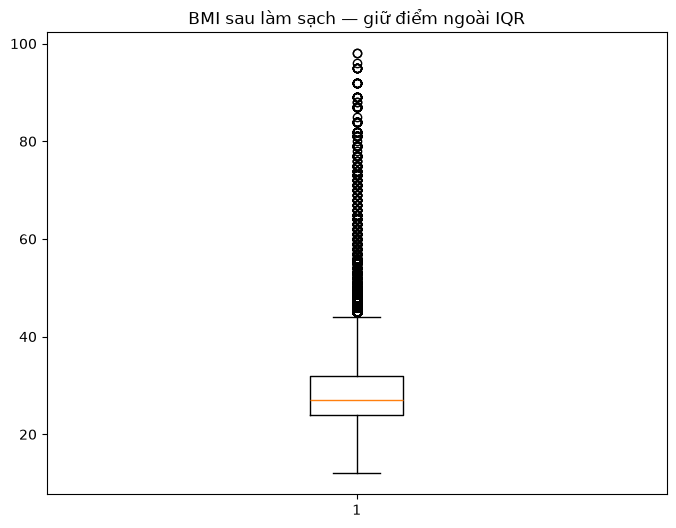

,_source_row,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,545,0.0,1.0,1.0,1.0,45.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,5.0,5.0,10.0,1.0,0.0,7.0,2.0,2.0
1,597,1.0,1.0,1.0,1.0,45.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,4.0,10.0,15.0,1.0,0.0,8.0,3.0,3.0
2,1136,0.0,0.0,0.0,1.0,45.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,3.0,6.0,6.0
3,1424,0.0,1.0,0.0,1.0,45.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,1.0,0.0,0.0,0.0,7.0,4.0,7.0
4,2601,0.0,1.0,0.0,1.0,45.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,5.0,8.0
5,3198,1.0,1.0,0.0,1.0,45.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,4.0,8.0,2.0,0.0,0.0,7.0,5.0,5.0
6,3424,1.0,1.0,1.0,1.0,45.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,3.0,3.0,0.0,0.0,1.0,7.0,6.0,7.0
7,3771,0.0,1.0,0.0,1.0,45.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,1.0,1.0,6.0,4.0,7.0
8,4554,0.0,0.0,0.0,1.0,45.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,3.0,0.0,0.0,1.0,1.0,7.0,5.0,8.0
9,5183,1.0,1.0,1.0,1.0,45.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,3.0,2.0,0.0,1.0,1.0,8.0,5.0,3.0


,_source_row,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,132180,0.0,0.0,1.0,0.0,95.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,6.0,5.0,8.0
1,132194,0.0,0.0,1.0,1.0,95.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,4.0,0.0,0.0,3.0,6.0,8.0
2,138055,0.0,0.0,0.0,1.0,95.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,3.0,6.0,6.0
3,138193,0.0,0.0,1.0,1.0,95.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,30.0,0.0,0.0,7.0,6.0,8.0
4,138346,1.0,1.0,1.0,1.0,95.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0,15.0,30.0,1.0,0.0,8.0,3.0,7.0
5,138402,0.0,1.0,0.0,1.0,95.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,5.0,30.0,30.0,1.0,0.0,7.0,3.0,1.0
6,138437,0.0,0.0,1.0,1.0,95.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,4.0,2.0,30.0,0.0,0.0,7.0,6.0,7.0
7,65186,1.0,1.0,0.0,1.0,96.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,6.0,4.0,8.0
8,132190,0.0,0.0,1.0,0.0,98.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,10.0,0.0,0.0,0.0,3.0,4.0,6.0
9,132247,1.0,1.0,1.0,1.0,98.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,5.0,30.0,30.0,1.0,0.0,8.0,6.0,5.0


In [2]:
NON_BINARY=['BMI']
s=prep_bmi_stats('clean_sql','BMI');lo,hi=s['lo'],s['hi']
display(iqr_summary(df_clean[['BMI']]))
extreme_bmi=prep_table('SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI,_source_row',(lo,hi),index_col='_source_row').astype('int16')
plt.figure(figsize=(8,6));plt.boxplot(df_clean['BMI']);plt.title('BMI sau làm sạch — giữ điểm ngoài IQR');plt.show()
display(prep_table('SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI,_source_row LIMIT 10',(lo,hi)))
display(prep_table('SELECT * FROM (SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI DESC,_source_row DESC LIMIT 10) ORDER BY BMI,_source_row',(lo,hi)))
assert prep_scalar('SELECT COUNT(*) FROM clean_sql c JOIN raw_scope r USING(_source_row) WHERE c.BMI != CASE WHEN CAST(r._BMI5 AS INTEGER)%100=50 THEN CAST(r._BMI5/100 AS INTEGER)+(CAST(r._BMI5/100 AS INTEGER)%2) ELSE ROUND(r._BMI5/100.0,0) END')==0


### 3.5.2. So sánh phân bố trước/sau làm sạch
**Trước: 187,383 dòng | Sau: 116,662 dòng | Giảm: 37.74%.** So sánh cùng phạm vi 30–59, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.

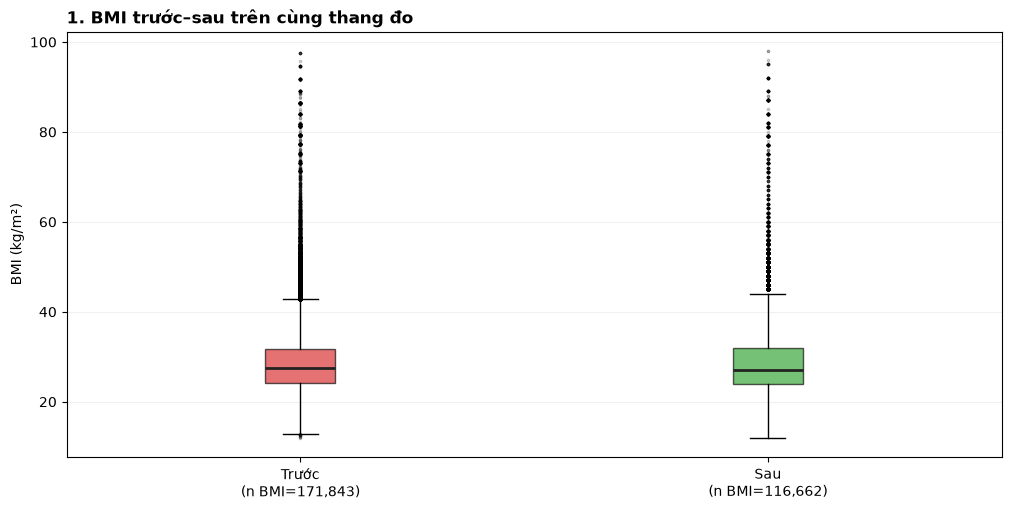

,Trước,Sau
Số BMI không thiếu,171843.00,116662.0
Số NaN,15540.00,0.0
Trung vị,27.40,27.0
Q1,24.13,24.0
Q3,31.62,32.0


BMI trước = _BMI5/100, giữ phần thập phân; BMI sau đã được làm tròn theo quy trình hiện tại. Thay đổi có thể do cả loại dòng và làm tròn.

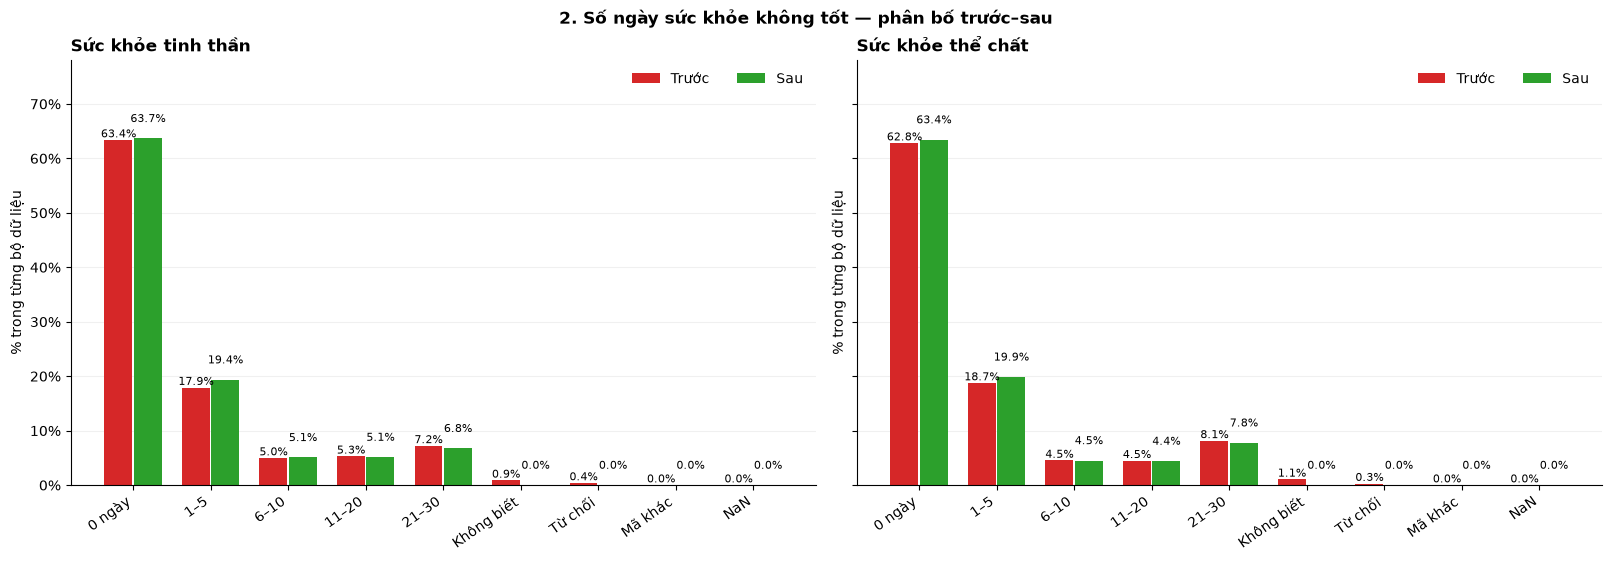

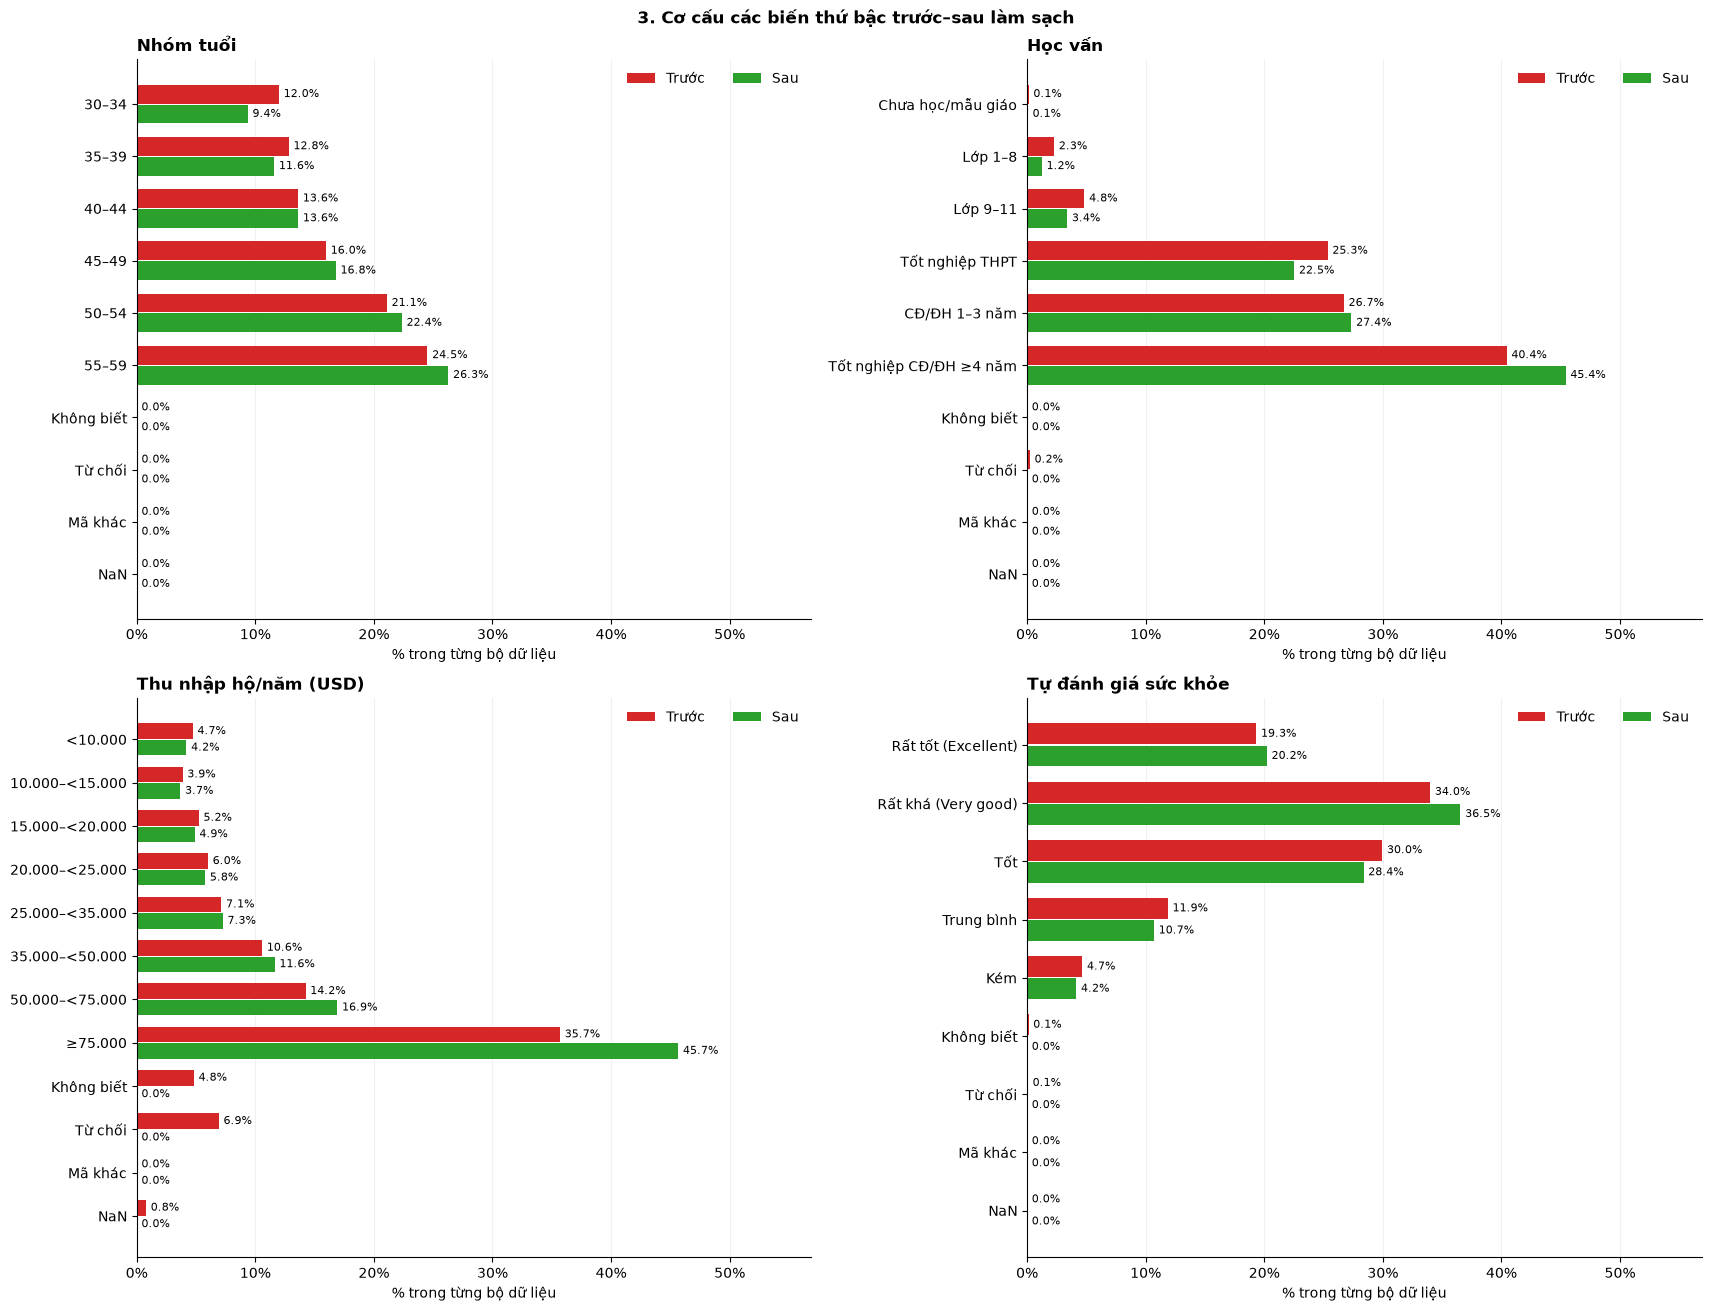

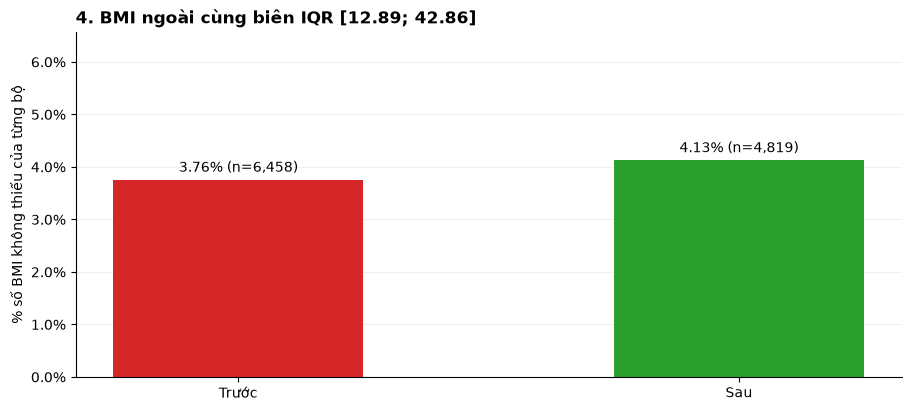

**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. **Không sửa df_selected_raw hoặc df_clean.**

In [14]:
# SO SÁNH PHÂN BỐ TRƯỚC/SAU LÀM SẠCH — MỤC 3.5.2
# Chỉ đọc dữ liệu; đổi đơn vị/nhãn trên bản phục vụ vẽ.
def plot_cleaning_comparison(raw, clean):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    nb, na = len(raw), len(clean)
    if nb == 0 or na == 0:
        raise ValueError('Cần dữ liệu trước và sau làm sạch có ít nhất một dòng.')
    before_color, after_color = '#D62728', '#2CA02C'
    display(Markdown(
        '### 3.5.2. So sánh phân bố trước/sau làm sạch\n'
        f'**Trước: {nb:,} dòng | Sau: {na:,} dòng | Giảm: {(1-na/nb)*100:.2f}%.** '
        'So sánh cùng phạm vi 30–59, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). '
        'Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; '
        'đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. '
        'Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        ax.grid(axis='x' if horizontal else 'y', alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def counts(series, mapping, order):
        return prep_distribution(series,mapping,order)

    def paired(ax, before, after, title, horizontal=False, limit=None):
        x = np.arange(len(before))
        bp, ap = before/nb*100, after/na*100
        if horizontal:
            b = ax.barh(x-.19, bp, height=.36, color=before_color, label='Trước')
            a = ax.barh(x+.19, ap, height=.36, color=after_color, label='Sau')
            ax.set_yticks(x, before.index)
            ax.invert_yaxis()
            ax.set_xlim(0, limit)
            ax.set_xlabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(p+.4, bar.get_y()+bar.get_height()/2,
                            f'{p:.1f}%', va='center', fontsize=8)
        else:
            b = ax.bar(x-.19, bp, width=.36, color=before_color, label='Trước')
            a = ax.bar(x+.19, ap, width=.36, color=after_color, label='Sau')
            ax.set_xticks(x, before.index, rotation=35, ha='right')
            ax.set_ylim(0, limit)
            ax.set_ylabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(bar.get_x()+bar.get_width()/2, p+(.5 if bars is b else 3),
                            f'{p:.1f}%', ha='center', fontsize=8)
        ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
        ax.legend(frameon=False, ncol=2, loc='upper right')
        style(ax, horizontal)

    with plt.rc_context({'font.family':'DejaVu Sans', 'font.size':10}):
        # 1. BMI cùng đơn vị, toàn bộ giá trị không thiếu, không cắt outlier.
        bmi_before = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
        bmi_after = prep_table('SELECT BMI FROM clean_sql WHERE BMI IS NOT NULL ORDER BY _source_row')['BMI']
        if bmi_before.empty or bmi_after.empty:
            raise ValueError('BMI không có giá trị quan sát ở một trong hai bộ.')
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        boxes = ax.boxplot([bmi_before, bmi_after], patch_artist=True,
            tick_labels=[f'Trước\n(n BMI={len(bmi_before):,})', f'Sau\n(n BMI={len(bmi_after):,})'],
            flierprops={'marker':'.', 'markersize':3, 'alpha':.25},
            medianprops={'color':'#222222', 'linewidth':2})
        for box, color in zip(boxes['boxes'], [before_color, after_color]):
            box.set_facecolor(color)
            box.set_alpha(.65)
        ax.set_title('1. BMI trước–sau trên cùng thang đo', loc='left', fontweight='bold')
        ax.set_ylabel('BMI (kg/m²)')
        ax.grid(axis='y', alpha=.18)
        plt.show()
        display(pd.DataFrame({
            'Trước': [len(bmi_before), prep_scalar('SELECT COUNT(*)-COUNT(_BMI5) FROM raw_scope'), prep_quantile('raw_scope','_BMI5/100.0',.5),
                      prep_quantile('raw_scope','_BMI5/100.0',.25), prep_quantile('raw_scope','_BMI5/100.0',.75)],
            'Sau': [len(bmi_after), prep_scalar('SELECT COUNT(*)-COUNT(BMI) FROM clean_sql'), prep_quantile('clean_sql','BMI',.5),
                    prep_quantile('clean_sql','BMI',.25), prep_quantile('clean_sql','BMI',.75)]},
            index=['Số BMI không thiếu', 'Số NaN', 'Trung vị', 'Q1', 'Q3']).round(2))
        display(Markdown('BMI trước = _BMI5/100, giữ phần thập phân; BMI sau đã được '
                         'làm tròn theo quy trình hiện tại. Thay đổi có thể do cả loại dòng và làm tròn.'))

        # 2. Số ngày: 88 -> nhãn 0 ngày; 77/99 không phải ngày thực tế.
        day_map = {0:'0 ngày', 88:'0 ngày',
            **{i:'1–5' for i in range(1,6)}, **{i:'6–10' for i in range(6,11)},
            **{i:'11–20' for i in range(11,21)}, **{i:'21–30' for i in range(21,31)},
            77:'Không biết', 99:'Từ chối'}
        day_order = ['0 ngày','1–5','6–10','11–20','21–30','Không biết','Từ chối','Mã khác','NaN']
        day_data = [(counts(raw[r], day_map, day_order), counts(clean[c], day_map, day_order), t)
            for r, c, t in [('MENTHLTH','MentHlth','Sức khỏe tinh thần'),
                            ('PHYSHLTH','PhysHlth','Sức khỏe thể chất')]]
        day_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b, a, _ in day_data)*1.18+3)
        fig, axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True,layout='constrained')
        fig.suptitle('2. Số ngày sức khỏe không tốt — phân bố trước–sau', fontweight='bold')
        for ax, (b,a,t) in zip(axes, day_data):
            paired(ax,b,a,t,limit=day_limit)
        plt.show()

        # 3. Bốn biến thứ bậc: cùng thứ tự nhóm, cùng trục tỷ lệ giữa các ô.
        age = ['30–34','35–39','40–44','45–49','50–54','55–59']
        specs = [
            ('_AGEG5YR','Age','Nhóm tuổi', dict(enumerate(age,3)), {14:'Không biết'}),
            ('EDUCA','Education','Học vấn', {1:'Chưa học/mẫu giáo',2:'Lớp 1–8',3:'Lớp 9–11',
             4:'Tốt nghiệp THPT',5:'CĐ/ĐH 1–3 năm',6:'Tốt nghiệp CĐ/ĐH ≥4 năm'}, {9:'Từ chối'}),
            ('INCOME2','Income','Thu nhập hộ/năm (USD)', {1:'<10.000',2:'10.000–<15.000',
             3:'15.000–<20.000',4:'20.000–<25.000',5:'25.000–<35.000',
             6:'35.000–<50.000',7:'50.000–<75.000',8:'≥75.000'}, {77:'Không biết',99:'Từ chối'}),
            ('GENHLTH','GenHlth','Tự đánh giá sức khỏe', {1:'Rất tốt (Excellent)',
             2:'Rất khá (Very good)',3:'Tốt',4:'Trung bình',5:'Kém'}, {7:'Không biết',9:'Từ chối'})]
        ordinal_data = []
        for r,c,t,valid,special in specs:
            order = list(valid.values()) + ['Không biết','Từ chối','Mã khác','NaN']
            ordinal_data.append((counts(raw[r], {**valid,**special}, order),
                                 counts(clean[c], valid, order), t))
        ord_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b,a,_ in ordinal_data)*1.18+3)
        fig, axes = plt.subplots(2,2,figsize=(17,13),layout='constrained')
        fig.suptitle('3. Cơ cấu các biến thứ bậc trước–sau làm sạch', fontweight='bold')
        for ax,(b,a,t) in zip(axes.flat,ordinal_data):
            paired(ax,b,a,t,horizontal=True,limit=ord_limit)
        plt.show()

        # 4. BMI ngoài biên: một ngưỡng cố định từ dữ liệu trước đã đổi đơn vị.
        q1,q3 = prep_quantile('raw_scope','_BMI5/100.0',.25),prep_quantile('raw_scope','_BMI5/100.0',.75)
        lo,hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        out_b = prep_scalar('SELECT SUM(_BMI5/100.0<? OR _BMI5/100.0>?) FROM raw_scope',(lo,hi))
        out_a = prep_scalar('SELECT SUM(BMI<? OR BMI>?) FROM clean_sql',(lo,hi))
        percentages = [out_b/len(bmi_before)*100, out_a/len(bmi_after)*100]
        fig, ax = plt.subplots(figsize=(9,4),layout='constrained')
        bars = ax.bar(['Trước','Sau'],percentages,color=[before_color,after_color],width=.5)
        ax.set_ylim(0,max(percentages)*1.35+1)
        for b,p,num in zip(bars,percentages,[out_b,out_a]):
            ax.text(b.get_x()+b.get_width()/2,p+.15,f'{p:.2f}% (n={num:,})',ha='center')
        ax.set_title(f'4. BMI ngoài cùng biên IQR [{lo:.2f}; {hi:.2f}]',loc='left',fontweight='bold')
        ax.set_ylabel('% số BMI không thiếu của từng bộ')
        style(ax)
        plt.show()
        display(Markdown('**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, '
            'áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. '
            'Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. '
            'Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. '
            'Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. '
            '**Không sửa df_selected_raw hoặc df_clean.**'))

plot_cleaning_comparison(df_selected_raw, df_clean)


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Bảng bên dưới được tính trực tiếp trong lần chạy này. Cột “trước” là mẫu đã chọn tuổi 30–59 và loại DIABETE3=2, chưa xử lý NaN/mã phản hồi. Nhật ký phạm vi, nhật ký làm sạch và bảng này có mẫu số riêng; không gộp loại ngoài phạm vi thành lỗi dữ liệu.

**Biên IQR chung cho dòng so sánh BMI:** Tính một lần từ BMI trước làm sạch sau phép chia 100, chưa làm tròn, rồi áp dụng cho cả hai bộ. Tỷ lệ ngoài biên dùng số BMI không thiếu của từng bộ làm mẫu số.

**Diễn giải:** Thay đổi số lượng và tỷ lệ có thể do loại dòng và làm tròn BMI; không có bước tự động loại theo IQR. Dòng này dùng biên chung [12,895; 42,855], khác với mục 3.5.1 tính biên riêng trên dữ liệu sau làm sạch [12; 44]. Vì vậy, 4.819 điểm ngoài biên chung ở bảng này và 3.379 điểm ngoài biên riêng ở mục 3.5.1 không mâu thuẫn.


In [15]:
summary_comparison = pd.DataFrame({
    'Chỉ tiêu': ['Số dòng', 'Số cột', 'Số ô NaN', 'Dòng chứa NaN',
                'Duplicate ngoài lần đầu', 'Kiểu lưu trữ', 'Mã tuổi', 'Mã nhãn'],
    'Trước clean (đã chọn phạm vi)': [len(df_selected_raw), df_selected_raw.shape[1],
        int(missing_table('raw_scope',SOURCE_COLS).missing_count.sum()), prep_scalar('SELECT COUNT(*) FROM raw_scope WHERE '+' OR '.join(qi(c)+' IS NULL' for c in SOURCE_COLS)),
        duplicate_count('raw_scope',SOURCE_COLS), ', '.join(map(str, df_selected_raw.dtypes.unique())),
        '3–8 (30–59 tuổi)', 'DIABETE3: 1/3/4 và mã không rõ/NaN nếu có'],
    'Sau clean (giữ duplicate)': [len(df_clean), df_clean.shape[1],
        int(missing_table('clean_sql',list(rename_dict.values())).missing_count.sum()), prep_scalar('SELECT COUNT(*) FROM clean_sql WHERE '+' OR '.join(qi(c)+' IS NULL' for c in rename_dict.values())),
        duplicate_count('clean_sql',list(rename_dict.values())), ', '.join(map(str, df_clean.dtypes.unique())),
        '3–8 (giữ mã gốc)', '0: DIABETE3=3; 1: DIABETE3=1/4']
})
# So sánh BMI theo cùng biên IQR từ dữ liệu trước làm sạch.
# Chỉ đổi thang trên bản phục vụ thống kê; không sửa dữ liệu.
bmi_before_compare = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
bmi_after_compare = prep_table('SELECT BMI FROM clean_sql WHERE BMI IS NOT NULL ORDER BY _source_row')['BMI']
q1_compare,q3_compare=prep_quantile('raw_scope','_BMI5/100.0',.25),prep_quantile('raw_scope','_BMI5/100.0',.75)
lo_compare = q1_compare - 1.5 * (q3_compare - q1_compare)
hi_compare = q3_compare + 1.5 * (q3_compare - q1_compare)
outside_before_compare = prep_scalar('SELECT SUM(_BMI5/100.0<? OR _BMI5/100.0>?) FROM raw_scope',(lo_compare,hi_compare))
outside_after_compare = prep_scalar('SELECT SUM(BMI<? OR BMI>?) FROM clean_sql',(lo_compare,hi_compare))

def outlier_comparison_text(count, total):
    number = f'{count:,}'.replace(',', '.')
    percent = f'{count / total * 100:.2f}'.replace('.', ',')
    return f'{number} — {percent}%'

summary_comparison = pd.concat([
    summary_comparison,
    pd.DataFrame({
        'Chỉ tiêu': ['Biểu diễn BMI', 'Mã khảo sát đặc biệt', 'BMI ngoài cùng biên IQR'],
        'Trước clean (đã chọn phạm vi)': [
            'Giá trị nguồn nhân 100',
            'Còn mã không biết/từ chối và mã 88 ở biến số ngày',
            outlier_comparison_text(outside_before_compare, len(bmi_before_compare))],
        'Sau clean (giữ duplicate)': [
            'Chia 100 và làm tròn',
            'Loại mã cần loại; chuyển 88 thành 0 ngày',
            outlier_comparison_text(outside_after_compare, len(bmi_after_compare))]
    })
], ignore_index=True)

display(summary_comparison)
print(f'Mẫu trước clean: {len(df_selected_raw):,}; sau clean: {len(df_clean):,}; '
      f'loại do làm sạch: {len(df_selected_raw)-len(df_clean):,} '
      f'({(1-len(df_clean)/len(df_selected_raw))*100:.2f}%).')
print(f'Bản đối chiếu không duplicate: {len(df_no_duplicates):,} dòng.')
assert len(df_selected_raw) - sum(row[2] for row in audit_rows) == len(df_clean)


Mẫu trước clean: 187,383; sau clean: 116,662; loại do làm sạch: 70,721 (37.74%).
Bản đối chiếu không duplicate: 102,826 dòng.


,Chỉ tiêu,Trước clean (đã chọn phạm vi),Sau clean (giữ duplicate)
0,Số dòng,187383,116662
1,Số cột,22,22
2,Số ô NaN,55113,0
3,Dòng chứa NaN,41805,0
4,Duplicate ngoài lần đầu,4385,13836
5,Kiểu lưu trữ,float64,int16
6,Mã tuổi,3–8 (30–59 tuổi),3–8 (giữ mã gốc)
7,Mã nhãn,DIABETE3: 1/3/4 và mã không rõ/NaN nếu có,0: DIABETE3=3; 1: DIABETE3=1/4
8,Biểu diễn BMI,Giá trị nguồn nhân 100,Chia 100 và làm tròn
9,Mã khảo sát đặc biệt,Còn mã không biết/từ chối và mã 88 ở biến số ngày,Loại mã cần loại; chuyển 88 thành 0 ngày


## Nhật ký xử lý và dữ liệu trong bộ nhớ
Hai DataFrame `df_clean` và `df_no_duplicates` chứa dữ liệu sạch từ SQLite. Nhật ký chọn mẫu, làm sạch và metadata được giữ trong phiên chạy. Phần phân tích nhận trực tiếp các DataFrame này, không xuất rồi đọc lại CSV trung gian. ZIP/XPT nguồn được giữ nguyên.


In [1]:
import json
datasets={'keep_duplicates':df_clean,'no_duplicates':df_no_duplicates}
metadata = {
    'source': 'CDC BRFSS2015 LLCP2015XPT.zip',
    'target': 'Diabetes_binary',
    'target_mapping': {'1': 1, '3': 0, '4': 1},
    'excluded_target_codes': [2, 7, 9],
    'version': 'brfss2015_age30_59_gestational_excluded_v1',
    'note': 'Academic classification of self-reported survey labels; no future-onset prediction.',
    'population': {'age_years_inclusive': [30, 59], 'source_age_column': '_AGEG5YR',
                   'allowed_age_codes': list(range(3, 9)), 'employment_filter': None,
                   'gestational_only_diabetes': 'exclude rows DIABETE3=2 before target recoding'},
    'feature_names': df_clean.columns.drop('Diabetes_binary').tolist(),
    'feature_count': 21,
    'processing': {'missing': 'dropna on all 22 selected columns',
                   'survey_codes': 'same removal/recoding rules as input notebook, except DIABETE3=2 excluded',
                   'bmi': 'divide by 100 and round to integer',
                   'outliers': 'retain values passing existing checks; no IQR deletion/capping',
                   'dtypes': 'int16', 'duplicate_main': 'keep',
                   'duplicate_comparison': 'drop_duplicates on all 22 columns',
                   'survey_weighted': False, 'modeling_performed': False},
    'cohort_flow': cohort_audit.to_dict(orient='records'),
    'cleaning_flow': pd.DataFrame(audit_rows, columns=['step','before','removed','after']).to_dict(orient='records'),
    'validation': {'source_label_mapping_verified': True, 'sql_output_validated': True,
                   'missing_cells_after': int(missing_table('clean_sql',list(rename_dict.values())).missing_count.sum()),
                   'domain_errors': int(total_errors)},
    'bmi_iqr': {'lower': float(lo), 'upper': float(hi),
                 'outside_count': len(extreme_bmi),
                 'outside_percent': len(extreme_bmi)/len(df_clean)*100},
    'datasets': {name: {'rows': len(frame), 'columns': len(frame.columns),
                        'duplicate_rows': duplicate_count('clean_sql' if frame is df_clean else 'dedup_sql',list(rename_dict.values())),
                        'class_counts': {str(k): int(v) for k, v in prep_table('SELECT Diabetes_binary,COUNT(*) AS n FROM '+('clean_sql' if frame is df_clean else 'dedup_sql')+' GROUP BY Diabetes_binary').set_index('Diabetes_binary')['n'].items()},
                        'class_percent': {str(k): float(v*100) for k, v in prep_table('SELECT Diabetes_binary,1.0*COUNT(*)/(SELECT COUNT(*) FROM '+('clean_sql' if frame is df_clean else 'dedup_sql')+') AS n FROM '+('clean_sql' if frame is df_clean else 'dedup_sql')+' GROUP BY Diabetes_binary').set_index('Diabetes_binary')['n'].items()}}
                 for name, frame in datasets.items()}
}
assert duplicate_count('dedup_sql',list(rename_dict.values()))==0
assert prep_scalar('SELECT COUNT(*) FROM dedup_sql')==len(df_no_duplicates)
PREP_DB.commit()
display(pd.DataFrame(metadata['cleaning_flow']))


,step,before,removed,after
0,NaN,187383,41805,145578
1,DIABETE3,145578,127,145451
2,_RFHYPE5,145451,179,145272
3,TOLDHI2,145272,841,144431
4,_CHOLCHK,144431,1316,143115
5,_BMI5,143115,0,143115
6,SMOKE100,143115,749,142366
7,CVDSTRK3,142366,210,142156
8,_MICHD,142156,0,142156
9,_TOTINDA,142156,6987,135169


## Chuyển trực tiếp dữ liệu sạch sang phân tích
Dùng bản sao DataFrame để phần phân tích không thay đổi dữ liệu sạch đã kiểm tra. Thứ tự hồ sơ được giữ nguyên để đối chiếu manifest Train/Test cố định. Bản chính có 116.662 hồ sơ; bản đối chiếu có 102.826 hồ sơ.


In [2]:
analysis_input=df_clean.reset_index(drop=True).copy(deep=True)
analysis_reference=df_no_duplicates.reset_index(drop=True).copy(deep=True)
pd.testing.assert_frame_equal(analysis_input,df_clean.reset_index(drop=True))
pd.testing.assert_frame_equal(analysis_reference,analysis_input.drop_duplicates().reset_index(drop=True))
assert analysis_input is not df_clean and analysis_reference is not df_no_duplicates
print("Đã chuyển trực tiếp dữ liệu sạch trong bộ nhớ; giữ nguyên thứ tự hồ sơ.")
import gc
for name in ["df_brfss_raw","df_selected_all","df_age_raw"]:globals().pop(name,None)
gc.collect()


Đã chuyển trực tiếp dữ liệu sạch trong bộ nhớ; giữ nguyên thứ tự hồ sơ.


In [3]:
from pathlib import Path
import json,hashlib,math,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display,Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
# All database work ends at the preprocessing boundary.
if "PREP_DB" in globals(): PREP_DB.close()
PROJECT_ROOT=FINAL_ROOT
INPUT_BASE=PROJECT_ROOT/"on_going2"/"Ongoing2_5_file_dau_vao"
BASE=PROJECT_ROOT/"báo cáo"/".runtime_final"/"sql_pandas_v2"
BASE.mkdir(parents=True,exist_ok=True)
TABLES,FIGS,MODELS=BASE/"tables",BASE/"figures",BASE/"models"
for folder in [TABLES,FIGS,MODELS]:folder.mkdir(exist_ok=True)
SEED = 42
TARGET = "Diabetes_binary"
FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income",
]
NUMERIC_FEATURES = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL_DOMAINS = {
    "Age": list(range(3, 9)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "GenHlth": list(range(1, 6)),
}
BINARY = [c for c in FEATURES if c not in NUMERIC_FEATURES and c not in ORDINAL_DOMAINS]
DROP_FEATURES_16 = ["Fruits", "Veggies", "Sex", "CholCheck", "AnyHealthcare"]
DROP_FEATURES_18 = ["Stroke", "Sex", "PhysHlth"]
FEATURE_SETS = {
    "full_21": FEATURES.copy(),
    "reduced_16": [feature for feature in FEATURES if feature not in DROP_FEATURES_16],
    "reduced_18": [feature for feature in FEATURES if feature not in DROP_FEATURES_18],
}
FEATURE_SET_ORDER = ["reduced_18", "reduced_16", "full_21"]
meta=metadata
assert meta["target_mapping"]=={"1":1,"3":0,"4":1}
assert meta["population"]["allowed_age_codes"]==list(range(3,9))
clean_data=analysis_input.copy(deep=True)
reference_dedup=analysis_reference.copy(deep=True)
actual_sha256=hashlib.sha256(clean_data.to_csv(index=False).encode("utf-8")).hexdigest()
if "clean_sha256" in meta:assert meta["clean_sha256"]==actual_sha256
assert list(clean_data)==[TARGET]+FEATURES
assert len(clean_data)==116662 and not clean_data.isna().any().any()
assert clean_data[TARGET].value_counts().to_dict()=={0:103921,1:12741}
dedup_mask=~clean_data.duplicated(subset=[TARGET]+FEATURES,keep="first")
clean_dedup=clean_data.loc[dedup_mask].copy()
pd.testing.assert_frame_equal(clean_dedup.reset_index(drop=True),reference_dedup)
assert len(clean_dedup)==102826
for col in [TARGET]+BINARY:assert clean_data[col].isin([0,1]).all()
for col,domain in ORDINAL_DOMAINS.items():assert clean_data[col].isin(domain).all()
assert clean_data[["MentHlth","PhysHlth"]].ge(0).all().all() and clean_data[["MentHlth","PhysHlth"]].le(30).all().all()
assert clean_data.BMI.gt(0).all()
clean_data.insert(0,"row_id",np.arange(len(clean_data),dtype=np.int64))
dedup_ids=clean_data.loc[dedup_mask,"row_id"].to_numpy()
clean_dedup=clean_data.loc[dedup_mask].copy()
def save_frame(frame,name):frame.to_csv(TABLES/(name+".csv"),index=False)
display(clean_data.groupby(TARGET).size().rename("Số dòng").to_frame().assign(**{"Tỷ lệ (%)":lambda x:100*x["Số dòng"]/len(clean_data)}))
ORANGE, PURPLE, BLUE = "#E67E22", "#7E3FB2", "#1674B8"
PALETTE = {0: ORANGE, 1: PURPLE}
DISCRETE_COLOR = CONTINUOUS_COLOR = BLUE
CORRELATION_CMAP = LinearSegmentedColormap.from_list(
    "orange_white_red", [ORANGE, "#FFFFFF", "#C62828"]
)
sns.set_theme(style="whitegrid", font="DejaVu Sans", palette=[ORANGE, PURPLE])
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)


def save_and_show_figure(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIGS / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def note(text):
    display(Markdown(text))


,Số dòng,Tỷ lệ (%)
Diabetes_binary,,
0,103921,89.078706
1,12741,10.921294


In [4]:
group_ids=pd.factorize(pd.MultiIndex.from_frame(clean_data[FEATURES]),sort=False)[0]
manifest_path=INPUT_BASE/"split_manifest.csv"
if manifest_path.is_file():
    split_meta=json.loads((INPUT_BASE/"split_metadata.json").read_text(encoding="utf-8"))
    assert split_meta["data_sha256"]==actual_sha256
    manifest=pd.read_csv(manifest_path).sort_values("row_id").reset_index(drop=True)
else:
    manifest=pd.DataFrame({"row_id":clean_data.row_id,"group_id":group_ids,"split":"test","cv_fold":-1})
    outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
    train_index,_=next(outer.split(clean_data[FEATURES],clean_data[TARGET],group_ids))
    manifest.loc[train_index,"split"]="train"
    inner=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+1)
    for fold,(_,val) in enumerate(inner.split(clean_data.loc[train_index,FEATURES].to_numpy(),clean_data.loc[train_index,TARGET].to_numpy(),group_ids[train_index])):
        manifest.loc[train_index[val],"cv_fold"]=fold
assert np.array_equal(manifest.row_id.to_numpy(),clean_data.row_id.to_numpy())
assert np.array_equal(manifest.group_id.to_numpy(),group_ids)
assert manifest.split.isin(["train","test"]).all()
assert manifest.groupby("group_id").split.nunique().max()==1
train_manifest=manifest[manifest.split.eq("train")]
assert train_manifest.groupby("group_id").cv_fold.nunique().max()==1
assert set(train_manifest.cv_fold)==set(range(5))
assert manifest.loc[manifest.split.eq("test"),"cv_fold"].eq(-1).all()
joined=clean_data.merge(manifest,on="row_id",validate="one_to_one",sort=False)
train_data=joined.loc[joined.split.eq("train"),["row_id",TARGET]+FEATURES].sort_values("row_id").reset_index(drop=True)
assert len(train_data)==93329
split_summary=joined.groupby("split",sort=False)[TARGET].agg(**{"Số dòng":"size","Lớp 1":"sum"}).reset_index()
split_summary["Lớp 0"]=split_summary["Số dòng"]-split_summary["Lớp 1"]
split_summary["Lớp 1 (%)"]=100.0*split_summary["Lớp 1"]/split_summary["Số dòng"]
split_summary["Tập"]=split_summary["split"].map({"train":"Train","test":"Test"})
split_summary=split_summary[["Tập","Số dòng","Lớp 0","Lớp 1","Lớp 1 (%)"]].sort_values("Tập",ascending=False).reset_index(drop=True)
display(split_summary);save_frame(split_summary,"split_summary")
df_eda=train_data[[TARGET]+FEATURES].astype("int16");df_eda[[TARGET]+BINARY]=df_eda[[TARGET]+BINARY].astype(bool)
X_train=df_eda[FEATURES].copy();y_train=df_eda[TARGET].to_numpy(dtype=bool)
pandas_context={"clean_data":clean_data,"manifest":manifest,"dedup_ids":dedup_ids}
print("pandas kiểm tra manifest: không giao nhóm Train/Test; giữ nguyên toàn bộ thành viên.")


pandas kiểm tra manifest: không giao nhóm Train/Test; giữ nguyên toàn bộ thành viên.


,Tập,Số dòng,Lớp 0,Lớp 1,Lớp 1 (%)
0,Train,93329,83137,10192,10.920507
1,Test,23333,20784,2549,10.924442


# IV. Phân tích pandas/NumPy và trực quan Python

Nhóm chỉ dùng **Train**, giữ phân bố và hồ sơ trùng hiện tại. Nhãn 0 = DIABETE3=3;
nhãn 1 = DIABETE3=1/4; mẫu gồm người 30–59 tuổi, đã loại DIABETE3=2 ở phần tiền xử lý.
Các tỷ lệ mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát và không chứng minh nhân quả.

**Cách đọc:** biểu đồ phân bố mô tả số hồ sơ; biểu đồ tỷ lệ nhóm mô tả % lớp 1 trong
từng mức đặc trưng. Histogram BMI theo lớp chuẩn hóa riêng từng lớp. Đọc tỷ lệ cùng số mẫu hiển thị trong các bảng và hình; nhóm ít hồ sơ có thể cho tỷ lệ kém ổn định.

Tham khảo cách dùng pandas/Seaborn trong
[Diabetes Prediction | EDA + Preprocessing + Models](https://www.kaggle.com/code/abdallahsaadelgendy/diabetes-prediction-eda-preprocessing-models)
(bản hiển thị Version 2 of 3). Nhóm giữ quy trình chia dữ liệu và preprocessing của dự án.


In [5]:
AGE_LABELS = ["30–34", "35–39", "40–44", "45–49", "50–54", "55–59"]
EDU_LABELS = [
    "Chưa học/\nmẫu giáo",
    "Lớp 1–8",
    "Lớp 9–11",
    "THPT",
    "CĐ/ĐH\n1–3 năm",
    "CĐ/ĐH\n≥4 năm",
]
INCOME_LABELS = [
    "<10k",
    "10–<15k",
    "15–<20k",
    "20–<25k",
    "25–<35k",
    "35–<50k",
    "50–<75k",
    "≥75k",
]
GEN_LABELS = ["Excellent", "Very good", "Good", "Fair", "Poor"]
LABEL_MAPS = {
    "Age": dict(enumerate(AGE_LABELS, 3)),
    "Education": dict(enumerate(EDU_LABELS, 1)),
    "Income": dict(enumerate(INCOME_LABELS, 1)),
    "GenHlth": dict(enumerate(GEN_LABELS, 1)),
}
EDA_LEVELS = {
    **{feature: [0, 1] for feature in BINARY},
    **ORDINAL_DOMAINS,
    "MentHlth": list(range(31)),
    "PhysHlth": list(range(31)),
}


parts=[]
for feature,levels in EDA_LEVELS.items():
    grouped=train_data.groupby(feature)[TARGET].agg(sample_count="size",positive_count="sum").reindex(levels)
    grouped[["sample_count","positive_count"]]=grouped[["sample_count","positive_count"]].fillna(0).astype(int)
    grouped["positive_rate"]=100*grouped.positive_count/grouped.sample_count.replace(0,np.nan)
    grouped=grouped.rename_axis("level").reset_index();grouped.insert(0,"Feature",feature);grouped["position"]=np.arange(len(grouped));parts.append(grouped)
feature_summary=pd.concat(parts,ignore_index=True)
def plot_rate_grid(features,label_maps,min_count=1):
    selected=feature_summary[feature_summary.Feature.isin(features)&feature_summary.sample_count.ge(min_count)]
    maximum=selected.positive_rate.max();limit=min(100,max(10,np.ceil(maximum/10)*10+10))
    fig,axes=plt.subplots((len(features)+1)//2,2,figsize=(14,4*((len(features)+1)//2)),squeeze=False,sharey=True)
    for ax,feature in zip(axes.flat,features):
        values=feature_summary[feature_summary.Feature.eq(feature)].sort_values("position")
        rates=values.positive_rate.where(values.sample_count.ge(min_count))
        pos=np.arange(len(values));labels=[label_maps.get(feature,{}).get(level,str(level)) for level in values.level]
        step=5 if len(labels)>15 else 1
        ax.bar(pos,rates,color=BLUE);ax.set(xticks=pos[::step],xticklabels=labels[::step],title=feature,ylabel="Lớp 1 trong nhóm (%)",ylim=(0,limit))
        ax.tick_params(axis="x",labelrotation=20 if feature=="Income" else 0)
    for ax in list(axes.flat)[len(features):]:ax.set_visible(False)
    fig.tight_layout();return fig


## Tổng hợp bằng pandas: tỷ lệ nhãn 1 theo nhóm tuổi trên Train
Dùng groupby, agg và phép chia vector hóa để tính số hồ sơ, số nhãn 1 và tỷ lệ. Mẫu số là số hồ sơ Train của từng nhóm tuổi, khác bảng SQL trước làm sạch ở phần dữ liệu.


In [6]:
age_summary=train_data.groupby("Age",sort=True)[TARGET].agg(n="size",positive_count="sum")
age_summary["positive_percent"]=(100.0*age_summary.positive_count/age_summary.n).round(2)
display(age_summary.reset_index())


,Age,n,positive_count,positive_percent
0,3,8744,305,3.49
1,4,10681,600,5.62
2,5,12725,946,7.43
3,6,15699,1654,10.54
4,7,20919,2813,13.45
5,8,24561,3874,15.77


## 1.1. Tổng quan và phân bố

### a. Chất lượng dữ liệu và phân bố nhãn

Bảng đầu kiểm tra đầu vào **sau tiền xử lý**, không thay thế báo cáo quá trình làm sạch dữ liệu nguồn.
Nhóm dùng pandas/NumPy để đếm dòng, kiểm tra duplicate/missing, tính số giá trị khác nhau, MIN/MAX và thống kê mô tả trên Train. Tứ phân vị dùng nội suy tuyến tính, độ lệch chuẩn mẫu dùng ddof=1. Nhãn được tổng hợp bằng groupby rồi vẽ số lượng và tỷ lệ.


**Cách đọc bảng:** “Kiểu đầu vào mô hình” được lấy từ dtype thực tế của DataFrame sạch trước preprocessing, sau khi nạp CSV bằng pandas. Các phép chuẩn hóa và nội bộ mô hình có thể chuyển sang số thực. Số thiếu được kiểm tra trên Train đã làm sạch sau tiền xử lý; pandas kiểm tra missing ngay khi nạp và khi tổng hợp trên Train. Đây không phải quy trình kiểm tra missing của dữ liệu CDC gốc.


Train: 93,329 dòng; trùng toàn bộ 22 cột: 11,071.


,Feature,Kiểu đầu vào mô hình,Số thiếu,Số giá trị khác nhau,Nhỏ nhất,Lớn nhất
0,Diabetes_binary,bool,0,2,0.0,1.0
1,HighBP,bool,0,2,0.0,1.0
2,HighChol,bool,0,2,0.0,1.0
3,CholCheck,bool,0,2,0.0,1.0
4,BMI,int16,0,79,12.0,98.0
5,Smoker,bool,0,2,0.0,1.0
6,Stroke,bool,0,2,0.0,1.0
7,HeartDiseaseorAttack,bool,0,2,0.0,1.0
8,PhysActivity,bool,0,2,0.0,1.0
9,Fruits,bool,0,2,0.0,1.0


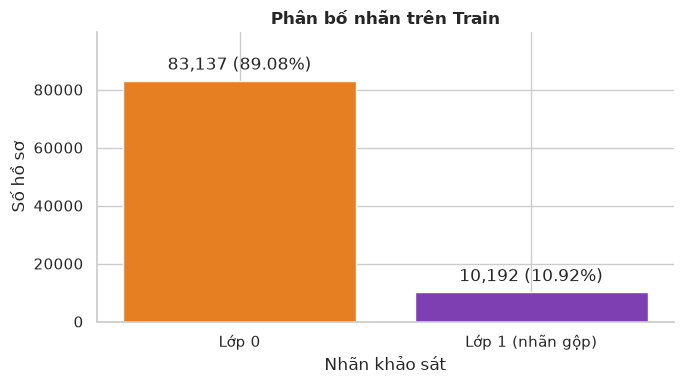

Lớp 1 chiếm **10.92%** Train. Chỉ đoán 0 có Accuracy cao nhưng Recall lớp 1 bằng 0.

In [7]:
data_summary=pd.DataFrame({"Feature":[TARGET]+FEATURES,"Kiểu đầu vào mô hình":[str(df_eda[c].dtype) for c in [TARGET]+FEATURES],"Số thiếu":df_eda.isna().sum().to_numpy(),"Số giá trị khác nhau":df_eda.nunique().to_numpy(),"Nhỏ nhất":df_eda.min().astype(float).to_numpy(),"Lớn nhất":df_eda.max().astype(float).to_numpy()})
display(data_summary);save_frame(data_summary,"ref_data_summary")
numeric_summary=train_data[NUMERIC_FEATURES].describe().T.rename_axis("Feature").reset_index()
row_count=len(train_data);duplicate_rows=int(train_data.duplicated(subset=[TARGET]+FEATURES).sum())
print(f"Train: {row_count:,} dòng; trùng toàn bộ 22 cột: {duplicate_rows:,}.")
assert df_eda.isna().sum().sum()==0
label_summary=train_data.groupby(TARGET).size().rename("sample_count").reset_index()
label_summary["percent"]=100*label_summary.sample_count/row_count
save_frame(label_summary,"eda_target_counts")
fig,ax=plt.subplots(figsize=(7,4));ax.bar(label_summary[TARGET],label_summary.sample_count,color=[PALETTE[v] for v in label_summary[TARGET]])
ax.set(title="Phân bố nhãn trên Train",xlabel="Nhãn khảo sát",ylabel="Số hồ sơ",xticks=[0,1],xticklabels=["Lớp 0","Lớp 1 (nhãn gộp)"],ylim=(0,1.2*label_summary.sample_count.max()))
ax.bar_label(ax.containers[0],labels=[f"{r.sample_count:,} ({r.percent:.2f}%)" for r in label_summary.itertuples()],padding=5)
fig.tight_layout();save_and_show_figure("eda_01_target",fig)
positive_percent=float(label_summary.loc[label_summary[TARGET].eq(1),"percent"].iloc[0])
note(f"Lớp 1 chiếm **{positive_percent:.2f}%** Train. Chỉ đoán 0 có Accuracy cao nhưng Recall lớp 1 bằng 0.")


### b. Phân bố biến số và kiểm tra BMI

Nhóm dùng histogram cho BMI và hai biến số ngày. BMI được trình bày bằng biểu đồ kết hợp: boxplot cho vị trí phần đuôi và biểu đồ cột cho số hồ sơ tại từng giá trị ngoại lệ theo quy tắc IQR.
Các điểm ngoài râu chỉ được gắn cờ để mô tả; nhóm không tự xóa hồ sơ hay đổi nhãn. Phân bố chung của biến nhị phân được trình bày tại mục 1.1.c; quan hệ của biến thứ bậc với nhãn được phân tích ở mục 1.2.b.


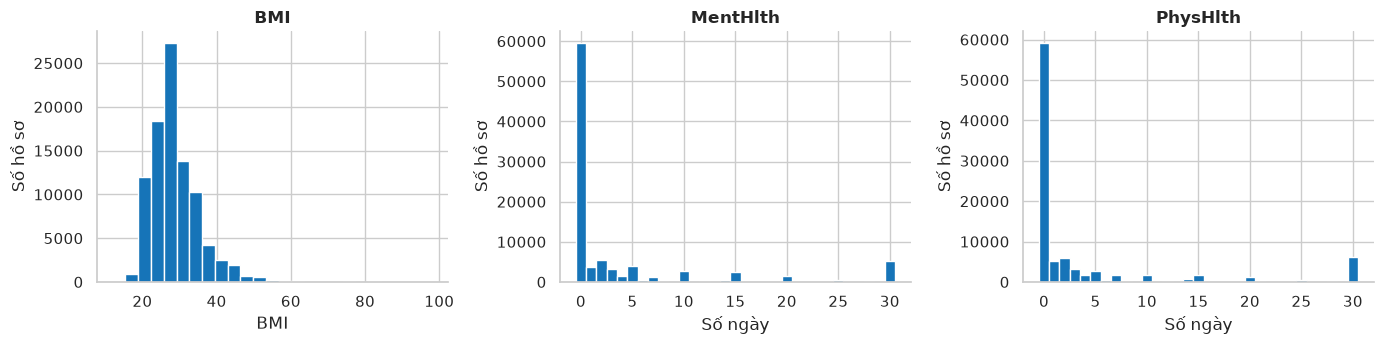

,Feature,count,mean,std,min,25%,50%,75%,max
0,BMI,93329.0,28.86,7.08,12.0,24.0,27.0,32.0,98.0
1,MentHlth,93329.0,3.80,7.98,0.0,0.0,0.0,3.0,30.0
2,PhysHlth,93329.0,3.86,8.28,0.0,0.0,0.0,2.0,30.0


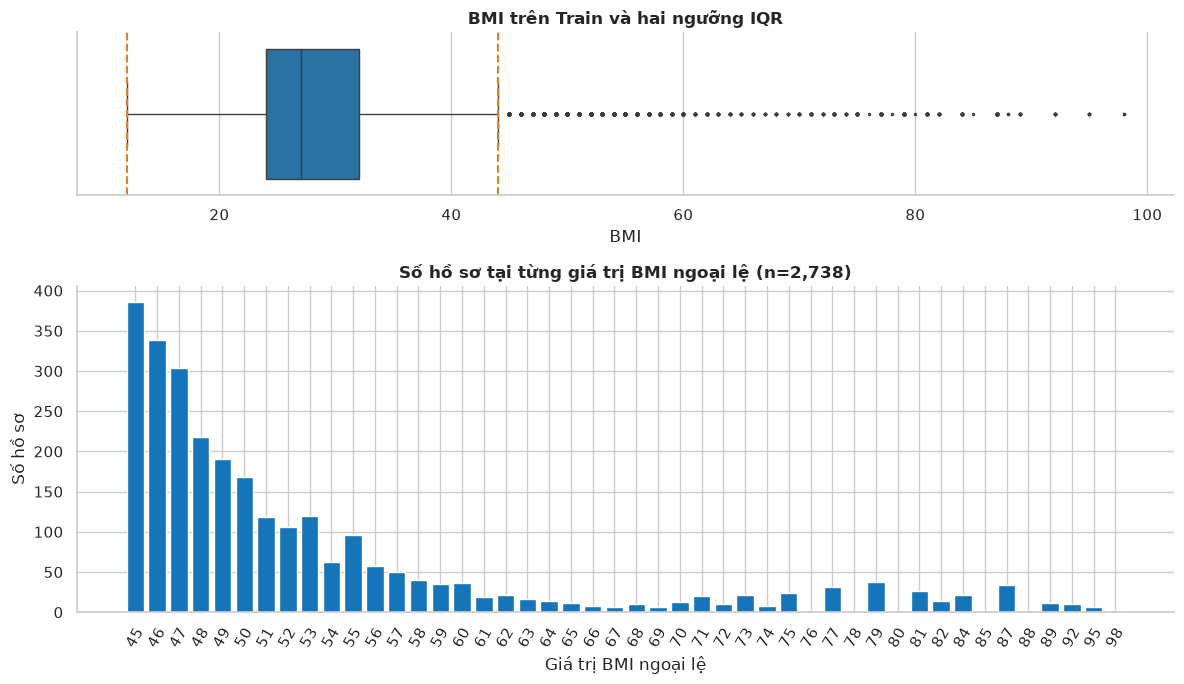

**Quan sát:** BMI tập trung chủ yếu trong khoảng Q1–Q3 **24–32**, có trung vị **27** và đuôi phải dài. Quy tắc IQR gắn cờ **2,738** hồ sơ (**2.93%** Train) có BMI < **12** hoặc > **44**; do BMI nhỏ nhất bằng 12, các điểm bị gắn cờ đều nằm ở đuôi trên và không bị tự động xóa. `MentHlth` và `PhysHlth` có **63.73%/63.32%** giá trị 0 ngày; 75% hồ sơ không vượt quá **3/2** ngày, nhưng cả hai vẫn có một nhóm nhỏ ở mức 30 ngày. Cả ba biến đều lệch phải, vì vậy cần đọc cùng trung vị, tứ phân vị và hình dạng phân bố thay vì chỉ dựa vào trung bình.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    bins = 25 if feature == "BMI" else np.arange(-0.5, 31.5)
    ax.hist(df_eda[feature], bins=bins, color=CONTINUOUS_COLOR, edgecolor="white")
    ax.set(
        title=feature,
        xlabel="BMI" if feature == "BMI" else "Số ngày",
        ylabel="Số hồ sơ",
    )
fig.tight_layout()
save_and_show_figure("eda_02_numeric_distributions", fig)

display(numeric_summary.round(2));save_frame(numeric_summary,"eda_numeric_summary")
bmi_row=numeric_summary.set_index("Feature").loc["BMI"]
bmi_summary={"q1":bmi_row["25%"],"q2":bmi_row["50%"],"q3":bmi_row["75%"]}
bmi_iqr=bmi_summary["q3"]-bmi_summary["q1"];bmi_lower=bmi_summary["q1"]-1.5*bmi_iqr;bmi_upper=bmi_summary["q3"]+1.5*bmi_iqr
bmi_outlier_counts=train_data.loc[~train_data.BMI.between(bmi_lower,bmi_upper)].groupby("BMI").size().rename("sample_count").reset_index()
bmi_outlier_total = int(bmi_outlier_counts["sample_count"].sum())
fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1, 2]})
sns.boxplot(data=df_eda, x="BMI", color=CONTINUOUS_COLOR, fliersize=1.5, ax=axes[0])
axes[0].axvline(bmi_lower, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].axvline(bmi_upper, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].set(title="BMI trên Train và hai ngưỡng IQR", xlabel="BMI")
axes[1].bar(
    bmi_outlier_counts["BMI"].astype(str),
    bmi_outlier_counts["sample_count"],
    color=CONTINUOUS_COLOR,
)
axes[1].set(
    title=f"Số hồ sơ tại từng giá trị BMI ngoại lệ (n={bmi_outlier_total:,})",
    xlabel="Giá trị BMI ngoại lệ",
    ylabel="Số hồ sơ",
)
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout()
save_and_show_figure("eda_03_bmi_outlier_detail", fig)
save_frame(bmi_outlier_counts,"eda_bmi_outlier_counts")
zero_rates={"mental":100*train_data.MentHlth.eq(0).mean(),"physical":100*train_data.PhysHlth.eq(0).mean()}
day_q3=numeric_summary.set_index("Feature")["75%"].to_dict()
bmi_outlier_percent = 100.0 * bmi_outlier_total / row_count
note(
    f"**Quan sát:** BMI tập trung chủ yếu trong khoảng Q1–Q3 **{bmi_summary['q1']:.0f}–{bmi_summary['q3']:.0f}**, có trung vị **{bmi_summary['q2']:.0f}** và đuôi phải dài. Quy tắc IQR gắn cờ **{bmi_outlier_total:,}** hồ sơ (**{bmi_outlier_percent:.2f}%** Train) có BMI < **{bmi_lower:.0f}** hoặc > **{bmi_upper:.0f}**; do BMI nhỏ nhất bằng 12, các điểm bị gắn cờ đều nằm ở đuôi trên và không bị tự động xóa. `MentHlth` và `PhysHlth` có **{zero_rates['mental']:.2f}%/{zero_rates['physical']:.2f}%** giá trị 0 ngày; 75% hồ sơ không vượt quá **{day_q3['MentHlth']:.0f}/{day_q3['PhysHlth']:.0f}** ngày, nhưng cả hai vẫn có một nhóm nhỏ ở mức 30 ngày. Cả ba biến đều lệch phải, vì vậy cần đọc cùng trung vị, tứ phân vị và hình dạng phân bố thay vì chỉ dựa vào trung bình."
)


### c. Phân bố biến nhị phân trên Train

Mỗi biến nhị phân có một biểu đồ tròn `False/True` trên toàn bộ Train, không phân tách theo nhãn 0/1. Nhãn trên lát cắt cho biết cả tỷ lệ và số hồ sơ. Quan hệ giữa từng biến và nhãn được phân tích riêng tại mục 1.2.


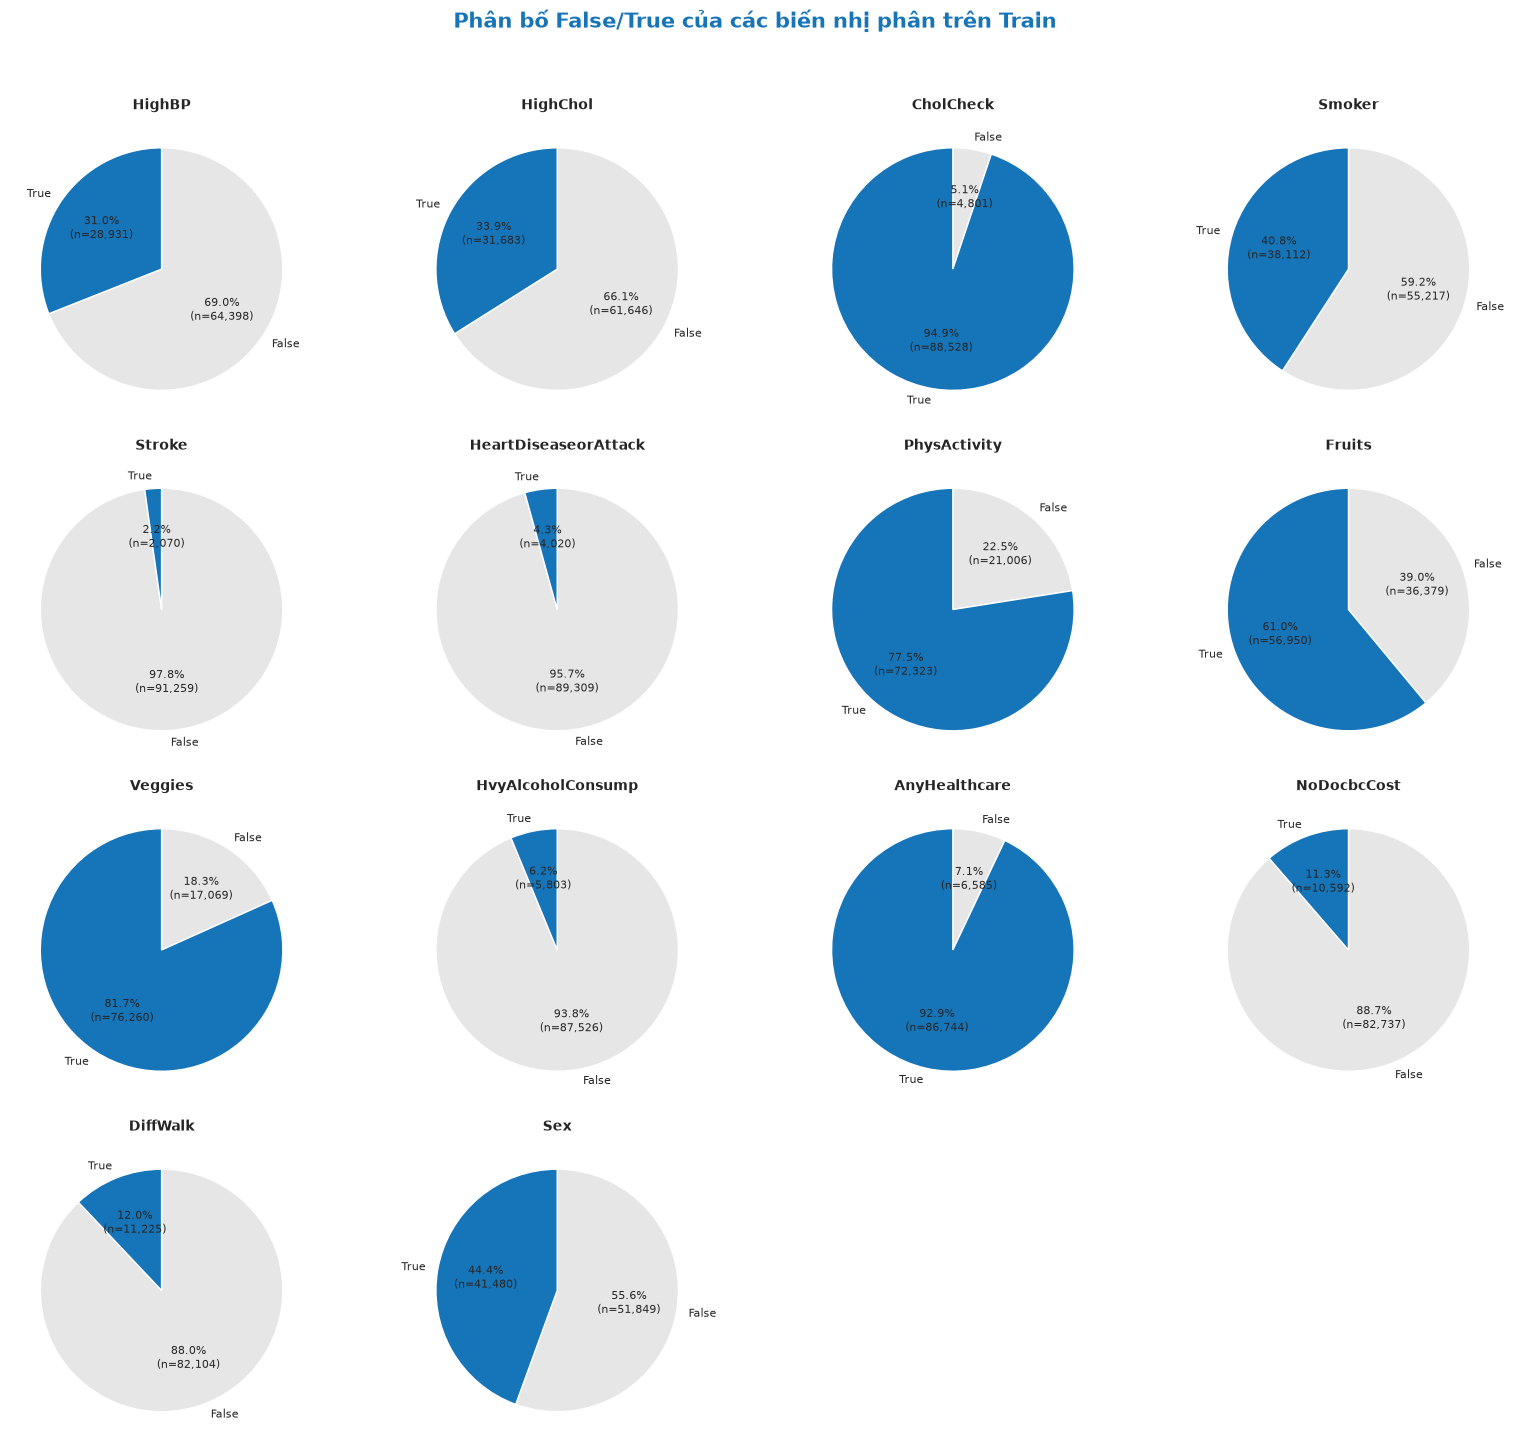

**Quan sát:** Các biến nhị phân có mức độ cân bằng rất khác nhau. `CholCheck` và `AnyHealthcare` gần như luôn mang giá trị `True`, trong khi `Stroke`, `HeartDiseaseorAttack` và `HvyAlcoholConsump` có tỷ lệ `True` thấp. `HighBP` và `HighChol` xuất hiện ở khoảng một phần ba mẫu; các hành vi `PhysActivity`, `Fruits` và `Veggies` tương đối phổ biến. Đây mới là phân bố chung trên Train, chưa chứng minh biến nào liên quan mạnh đến nhãn; mối quan hệ với lớp 0/1 được kiểm tra riêng tại mục 1.2.

In [9]:
binary_overall_summary=pd.concat([train_data.groupby(c).size().reindex([0,1],fill_value=0).rename("sample_count").rename_axis("Value").reset_index().assign(Feature=c) for c in BINARY],ignore_index=True)
binary_overall_summary["percent"]=100*binary_overall_summary.sample_count/len(train_data)
save_frame(binary_overall_summary.sort_values(["Feature","Value"]),"eda_binary_distribution_overall")
def pie_count_label(total):
    return lambda pct: f"{pct:.1f}%\n(n={int(round(pct * total / 100)):,})"


def plot_binary_pies():
    columns = 4
    rows = math.ceil(len(BINARY) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 3.7 * rows), squeeze=False)
    for ax, feature in zip(axes.flat, BINARY):
        values=binary_overall_summary[binary_overall_summary.Feature.eq(feature)].sort_values("Value").to_dict("records")
        counts = [next((r["sample_count"] for r in values if r["Value"] == value), 0) for value in [0, 1]]
        ax.pie(
            counts,
            labels=["False", "True"],
            colors=["#E6E6E6", BLUE],
            autopct=pie_count_label(sum(counts)),
            startangle=90,
            counterclock=False,
            wedgeprops={"edgecolor": "white", "linewidth": 1},
            textprops={"fontsize": 8},
        )
        ax.set_title(feature, fontsize=10, fontweight="bold")
    for ax in list(axes.flat)[len(BINARY):]:
        ax.set_visible(False)
    fig.suptitle("Phân bố False/True của các biến nhị phân trên Train", fontsize=15, fontweight="bold", color=BLUE)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


fig = plot_binary_pies()
save_and_show_figure("eda_04_binary_pies_overall", fig)
note(
    "**Quan sát:** Các biến nhị phân có mức độ cân bằng rất khác nhau. `CholCheck` và `AnyHealthcare` gần như luôn mang giá trị `True`, trong khi `Stroke`, `HeartDiseaseorAttack` và `HvyAlcoholConsump` có tỷ lệ `True` thấp. `HighBP` và `HighChol` xuất hiện ở khoảng một phần ba mẫu; các hành vi `PhysActivity`, `Fruits` và `Veggies` tương đối phổ biến. Đây mới là phân bố chung trên Train, chưa chứng minh biến nào liên quan mạnh đến nhãn; mối quan hệ với lớp 0/1 được kiểm tra riêng tại mục 1.2."
)


## 1.2. Đặc trưng và nhãn

### a. Biến nhị phân

Mỗi biến có hai biểu đồ tròn đặt cạnh nhau: nhãn 1 bên trái và nhãn 0 bên phải. Mỗi biểu đồ thể hiện tỷ lệ và số hồ sơ False/True trong chính lớp đó; màu cam là False, màu tím là True. Nhãn 1 gộp tiền tiểu đường/tiểu đường theo quy ước dự án. Mỗi cặp dùng cùng màu và thứ tự để dễ đối chiếu. Đây là phân bố đặc trưng trong từng lớp, P(X | Y).


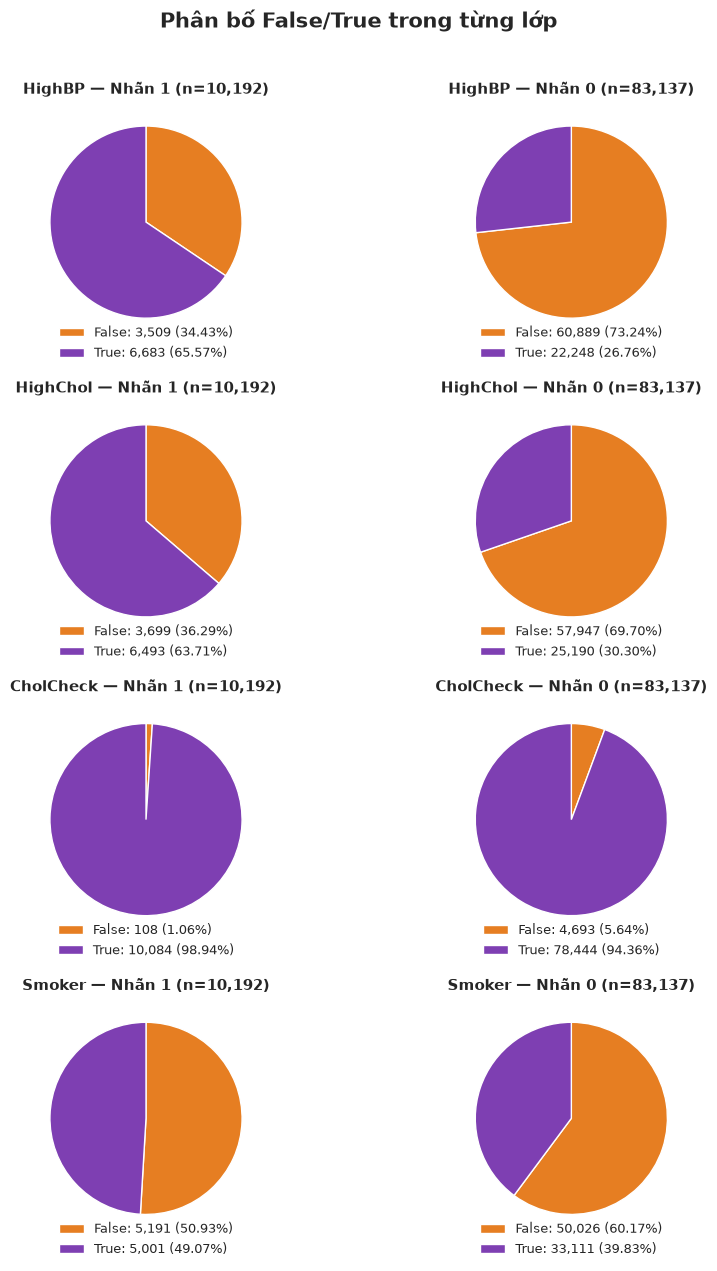

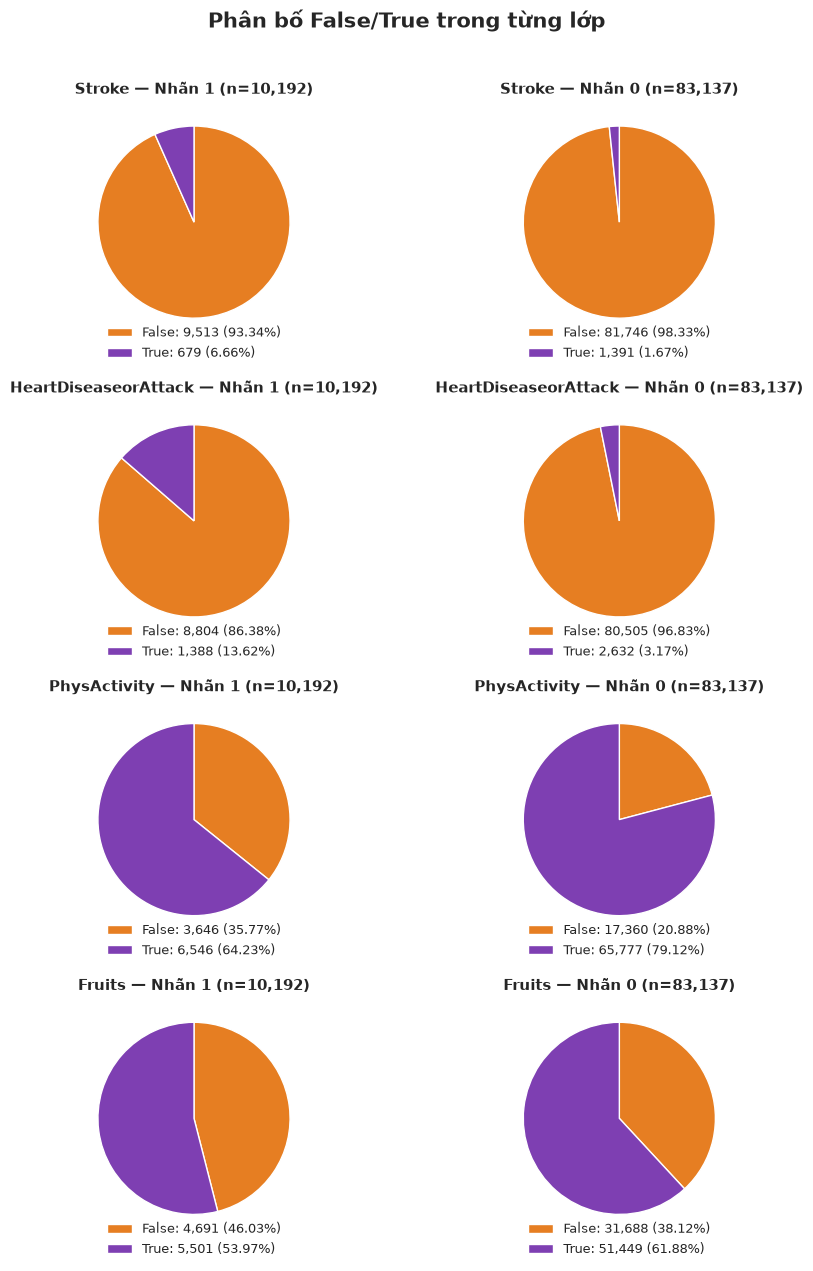

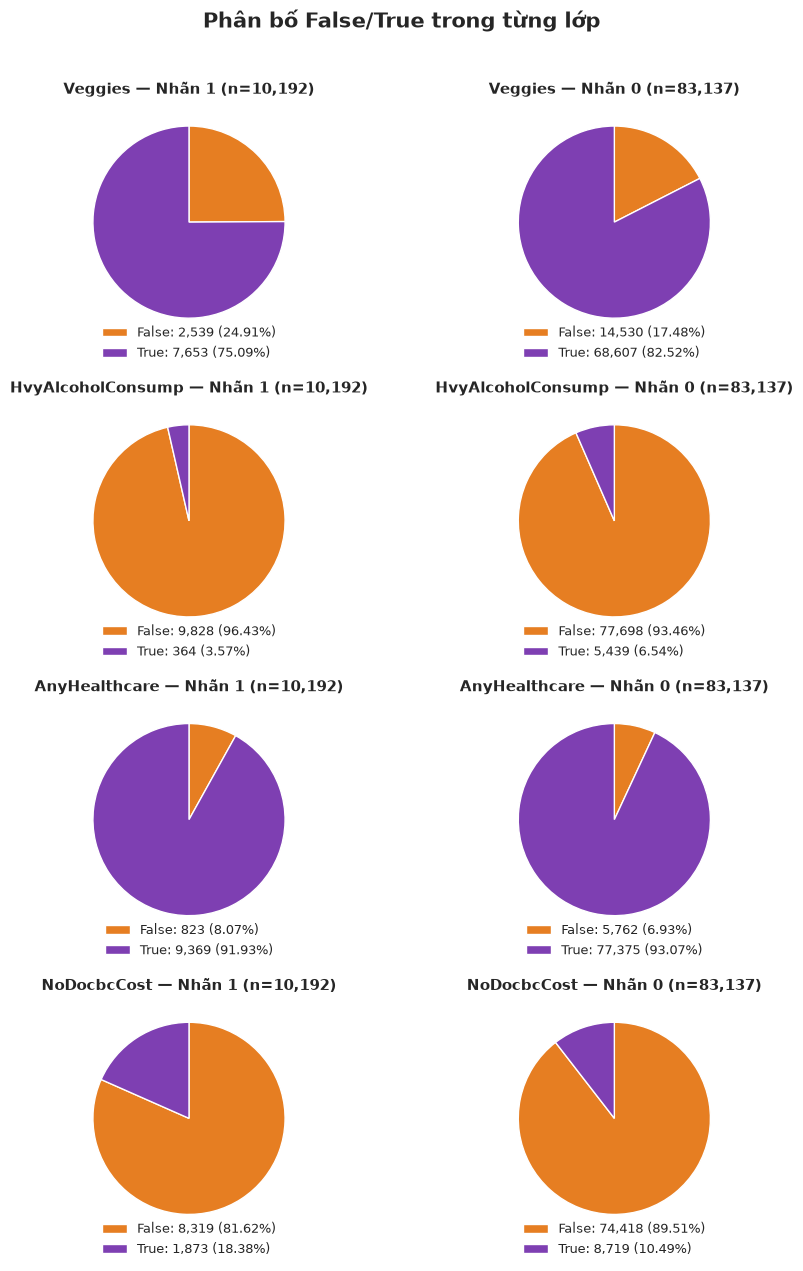

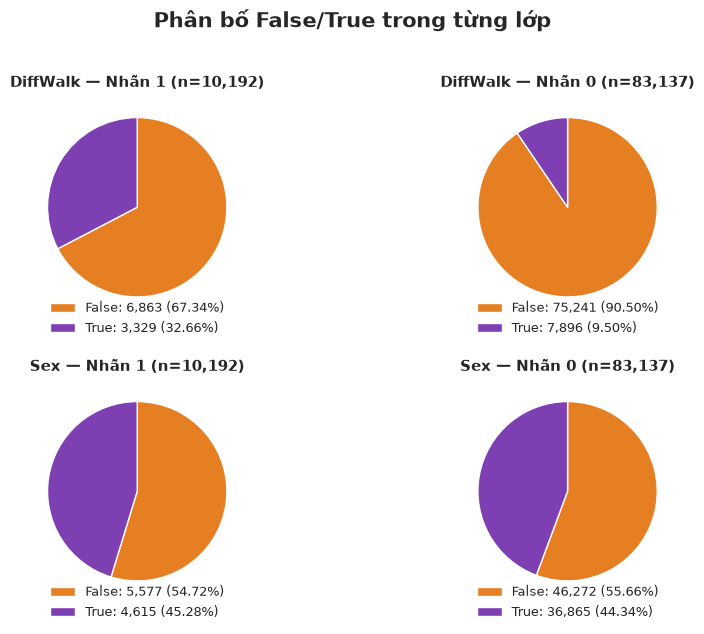

,Feature,true_label0_percent,true_label1_percent,difference_pp
0,AnyHealthcare,93.07,91.93,-1.14
1,CholCheck,94.36,98.94,4.59
2,DiffWalk,9.50,32.66,23.17
3,Fruits,61.88,53.97,-7.91
4,HeartDiseaseorAttack,3.17,13.62,10.45
5,HighBP,26.76,65.57,38.81
6,HighChol,30.30,63.71,33.41
7,HvyAlcoholConsump,6.54,3.57,-2.97
8,NoDocbcCost,10.49,18.38,7.89
9,PhysActivity,79.12,64.23,-14.89


### Ba biến có chênh lệch tỷ lệ True lớn nhất giữa hai lớp

,Biến,True trong nhãn 1 (%),True trong nhãn 0 (%),Chênh lệch 1−0 (điểm %)
5,HighBP,65.57,26.76,38.81
6,HighChol,63.71,30.30,33.41
2,DiffWalk,32.66,9.50,23.17


**HighBP:** tỷ lệ True ở nhãn 1 là **65.57%**, ở nhãn 0 là **26.76%**; chênh lệch **+38.81 điểm phần trăm**.

**HighChol:** tỷ lệ True ở nhãn 1 là **63.71%**, ở nhãn 0 là **30.30%**; chênh lệch **+33.41 điểm phần trăm**.

**DiffWalk:** tỷ lệ True ở nhãn 1 là **32.66%**, ở nhãn 0 là **9.50%**; chênh lệch **+23.17 điểm phần trăm**.

**Nhận xét:** HighBP, HighChol và DiffWalk có chênh lệch tỷ lệ True lớn nhất trong 14 biến nhị phân. Các hồ sơ nhãn 1 báo cáo huyết áp cao, cholesterol cao và khó khăn khi đi bộ/leo cầu thang thường xuyên hơn nhóm nhãn 0. Đây là dấu hiệu ba biến có khả năng cung cấp thông tin phân biệt hai lớp, cần được kiểm tra tiếp cùng các biến khác và kết quả mô hình. Chênh lệch được đo bằng điểm phần trăm, không phải phần trăm tăng tương đối; liên hệ quan sát chưa chứng minh nhân quả hoặc mức đóng góp độc lập của từng biến.

**Quan sát:** So sánh tỷ lệ True giữa hai lớp giúp nhận diện đặc điểm phổ biến hơn trong từng lớp. Các tỷ lệ trong mỗi biểu đồ có mẫu số là số hồ sơ của chính lớp đó, nên vẫn so sánh được khi hai lớp khác quy mô. Đây là phân bố P(X | Y), không phải tỷ lệ mắc nhãn 1 khi có đặc điểm P(Y | X); các chênh lệch chưa được điều chỉnh theo tuổi, BMI và các biến khác.

In [10]:
binary_by_label=pd.concat([train_data.groupby([TARGET,c]).size().reindex(pd.MultiIndex.from_product([[0,1],[0,1]],names=["Label","Value"]),fill_value=0).rename("sample_count").reset_index().assign(Feature=c) for c in BINARY],ignore_index=True)
label_totals=train_data.groupby(TARGET).size()
binary_by_label["percent"]=100*binary_by_label.sample_count/binary_by_label.Label.map(label_totals)
save_frame(binary_by_label.sort_values(["Feature","Label","Value"],ascending=[True,False,True]),"eda_binary_by_label")
# Each row compares the same feature; each figure contains four feature pairs.
for start in range(0, len(BINARY), 4):
    subset = BINARY[start:start + 4]
    fig, axes = plt.subplots(len(subset), 2, figsize=(10, 3.3 * len(subset)), squeeze=False)
    for row_index, feature in enumerate(subset):
        for column_index, label in enumerate([1, 0]):
            ax = axes[row_index, column_index]
            rows=binary_by_label[binary_by_label.Feature.eq(feature)&binary_by_label.Label.eq(label)].sort_values("Value").to_dict("records")
            counts = [row["sample_count"] for row in rows]
            total = sum(counts)
            wedges, _ = ax.pie(
                counts, colors=[ORANGE, PURPLE], startangle=90,
                counterclock=False, wedgeprops={"edgecolor": "white"},
            )
            labels = [
                f"{bool(value)}: {count:,} ({100 * count / total:.2f}%)"
                for value, count in enumerate(counts)
            ]
            ax.legend(wedges, labels, loc="lower center", bbox_to_anchor=(0.5, -0.12),
                      frameon=False, fontsize=9)
            ax.set_title(f"{feature} — Nhãn {label} (n={total:,})", fontsize=11)
    fig.suptitle("Phân bố False/True trong từng lớp", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    save_and_show_figure(f"eda_04_binary_by_label_{start // 4 + 1}", fig)

comparison=binary_by_label[binary_by_label.Value.eq(1)].pivot(index="Feature",columns="Label",values="percent").rename(columns={1:"true_label1_percent",0:"true_label0_percent"}).reset_index().rename_axis(None,axis=1)
comparison["difference_pp"] = comparison["true_label1_percent"] - comparison["true_label0_percent"]
display(comparison.round(2))
top3_binary = comparison.assign(abs_difference_pp=comparison["difference_pp"].abs()).sort_values(
    ["abs_difference_pp", "Feature"], ascending=[False, True]
).head(3)
display(Markdown("### Ba biến có chênh lệch tỷ lệ True lớn nhất giữa hai lớp"))
display(top3_binary[["Feature", "true_label1_percent", "true_label0_percent", "difference_pp"]].rename(columns={
    "Feature": "Biến", "true_label1_percent": "True trong nhãn 1 (%)",
    "true_label0_percent": "True trong nhãn 0 (%)", "difference_pp": "Chênh lệch 1−0 (điểm %)",
}).round(2))
for row in top3_binary.to_dict("records"):
    note(f"**{row['Feature']}:** tỷ lệ True ở nhãn 1 là **{row['true_label1_percent']:.2f}%**, ở nhãn 0 là **{row['true_label0_percent']:.2f}%**; chênh lệch **{row['difference_pp']:+.2f} điểm phần trăm**.")
note(
    "**Nhận xét:** HighBP, HighChol và DiffWalk có chênh lệch tỷ lệ True lớn nhất trong 14 biến nhị phân. "
    "Các hồ sơ nhãn 1 báo cáo huyết áp cao, cholesterol cao và khó khăn khi đi bộ/leo cầu thang thường xuyên hơn nhóm nhãn 0. "
    "Đây là dấu hiệu ba biến có khả năng cung cấp thông tin phân biệt hai lớp, cần được kiểm tra tiếp cùng các biến khác và kết quả mô hình. "
    "Chênh lệch được đo bằng điểm phần trăm, không phải phần trăm tăng tương đối; liên hệ quan sát chưa chứng minh nhân quả hoặc mức đóng góp độc lập của từng biến."
)
note(
    "**Quan sát:** So sánh tỷ lệ True giữa hai lớp giúp nhận diện đặc điểm phổ biến hơn trong từng lớp. "
    "Các tỷ lệ trong mỗi biểu đồ có mẫu số là số hồ sơ của chính lớp đó, nên vẫn so sánh được khi hai lớp khác quy mô. "
    "Đây là phân bố P(X | Y), không phải tỷ lệ mắc nhãn 1 khi có đặc điểm P(Y | X); các chênh lệch chưa được điều chỉnh theo tuổi, BMI và các biến khác."
)


### b. Biến thứ bậc và số ngày sức khỏe kém

Khung 2×2 gom Age, Education, Income và GenHlth; khung 1×2 gom MentHlth và PhysHlth.
Income tính bằng nghìn USD/hộ/năm. GenHlth đi từ Excellent đến Poor.
Các biểu đồ trong cùng khung dùng chung thang đo, bắt đầu từ 0%; mức không có hồ sơ không có cột tỷ lệ.

Nhóm chỉ vẽ tỷ lệ số ngày ở mức có n ≥ 30; bảng dưới hình liệt kê các mức ít hồ sơ. Nhóm giữ nguyên các hồ sơ và giá trị trong dữ liệu huấn luyện.


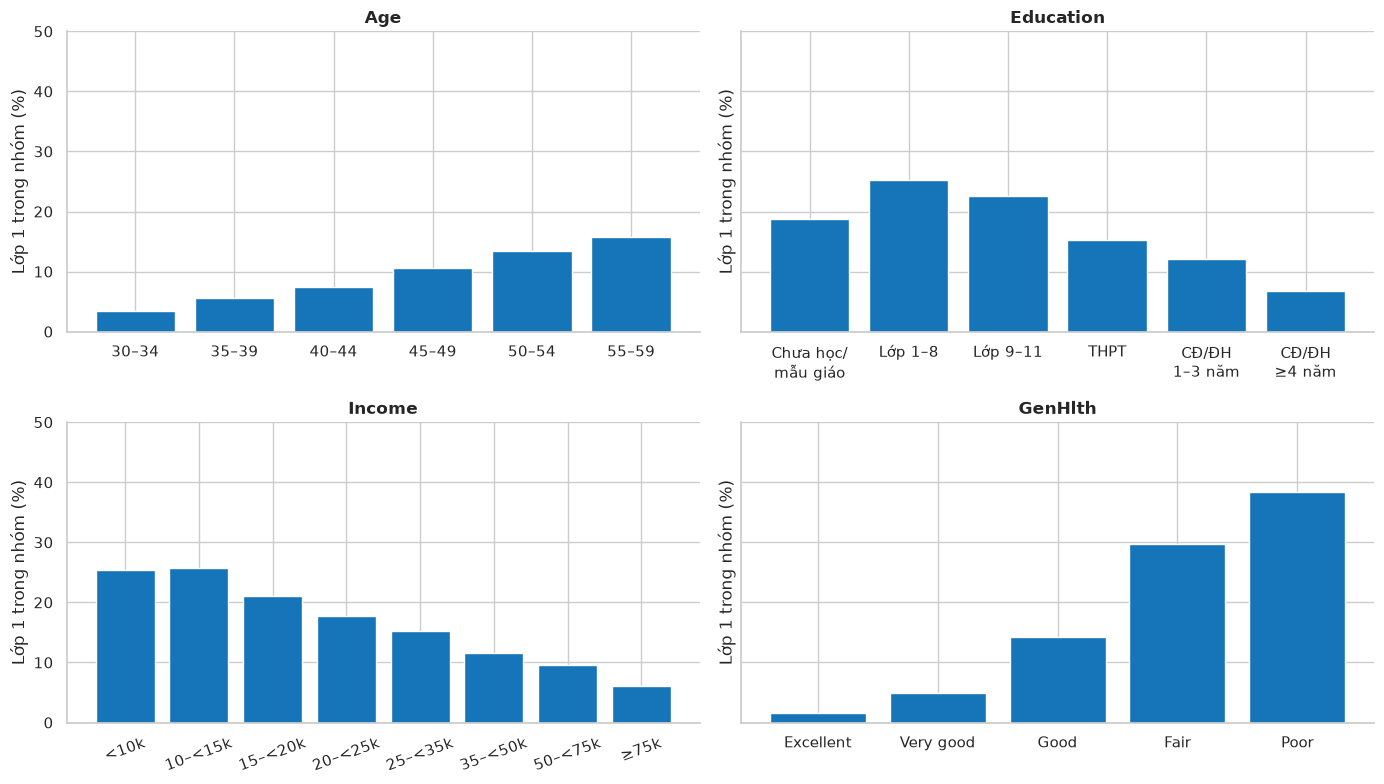

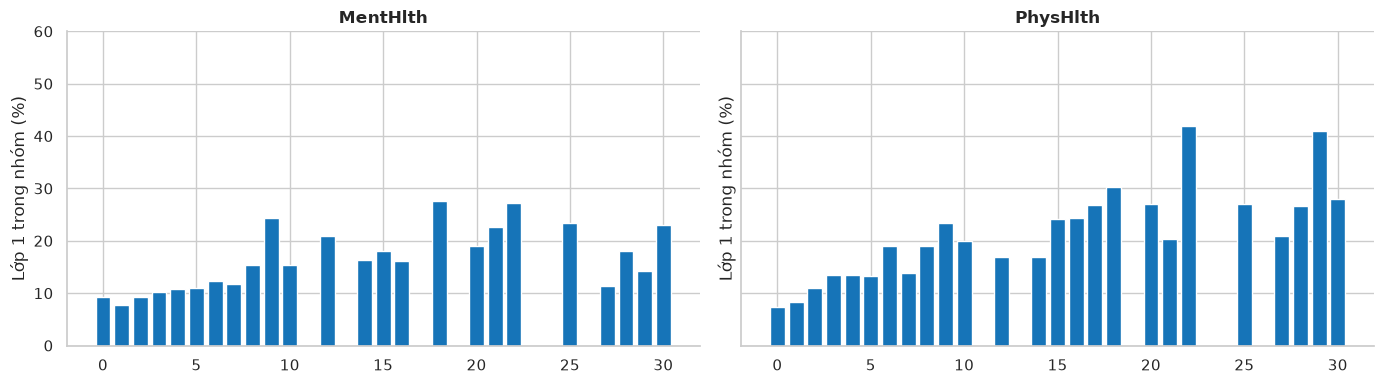

Tỷ lệ nhãn 1 thấp nhất ở 30–34 (3.49%), cao nhất ở 55–59 (15.77%). Đây là so sánh nhóm, không theo dõi một người qua thời gian.

,Feature,Days,sample_count,positive_count,positive_rate,position
64,MentHlth,11,15,2,13.33,11
66,MentHlth,13,21,5,23.81,13
70,MentHlth,17,22,4,18.18,17
72,MentHlth,19,4,0,0.00,19
76,MentHlth,23,17,3,17.65,23
77,MentHlth,24,14,4,28.57,24
79,MentHlth,26,18,4,22.22,26
95,PhysHlth,11,24,4,16.67,11
97,PhysHlth,13,24,11,45.83,13
103,PhysHlth,19,5,3,60.00,19


GenHlth=Excellent: lớp 1 1.59%, n=18,916.

GenHlth=Poor: lớp 1 38.43%, n=3,854.

Income=<10k: lớp 1 25.37%, n=3,957.

Income=≥75k: lớp 1 6.12%, n=42,597.

Tỷ lệ mô tả mẫu trên Train; các nhóm ít mẫu có thể kém ổn định. Liên hệ riêng lẻ chưa điều chỉnh ảnh hưởng các biến khác và không chứng minh nhân quả.

In [11]:
fig=plot_rate_grid(list(ORDINAL_DOMAINS),LABEL_MAPS);save_and_show_figure("eda_05_ordinal_rates",fig)
fig=plot_rate_grid(["MentHlth","PhysHlth"],LABEL_MAPS,min_count=30);save_and_show_figure("eda_06_health_day_rates",fig)
age_rates=feature_summary[feature_summary.Feature.eq("Age")].dropna(subset=["positive_rate"]).sort_values(["positive_rate","level"])
low_age=age_rates.iloc[0];high_age=age_rates.iloc[-1]
note(f"Tỷ lệ nhãn 1 thấp nhất ở {LABEL_MAPS['Age'][low_age.level]} ({low_age.positive_rate:.2f}%), cao nhất ở {LABEL_MAPS['Age'][high_age.level]} ({high_age.positive_rate:.2f}%). Đây là so sánh nhóm, không theo dõi một người qua thời gian.")
display(feature_summary[feature_summary.Feature.isin(["MentHlth","PhysHlth"])&feature_summary.sample_count.between(1,29)].rename(columns={"level":"Days"}).round(2))
for feature in ["GenHlth","Income"]:
    values=feature_summary[feature_summary.Feature.eq(feature)].sort_values("level")
    for row in values.iloc[[0,-1]].itertuples():note(f"{feature}={LABEL_MAPS[feature][row.level]}: lớp 1 {row.positive_rate:.2f}%, n={row.sample_count:,}.")
note("Tỷ lệ mô tả mẫu trên Train; các nhóm ít mẫu có thể kém ổn định. Liên hệ riêng lẻ chưa điều chỉnh ảnh hưởng các biến khác và không chứng minh nhân quả.")


### c. BMI theo nhãn

Hai lớp dùng chung ranh giới bin và mỗi lớp có tổng tỷ trọng 100%.
Nhờ đó, người đọc so sánh hình dạng phân bố dù hai lớp có số hồ sơ khác nhau.
Tỷ trọng trong hình này không phải tỷ lệ mắc nhãn 1 tại một mức BMI.


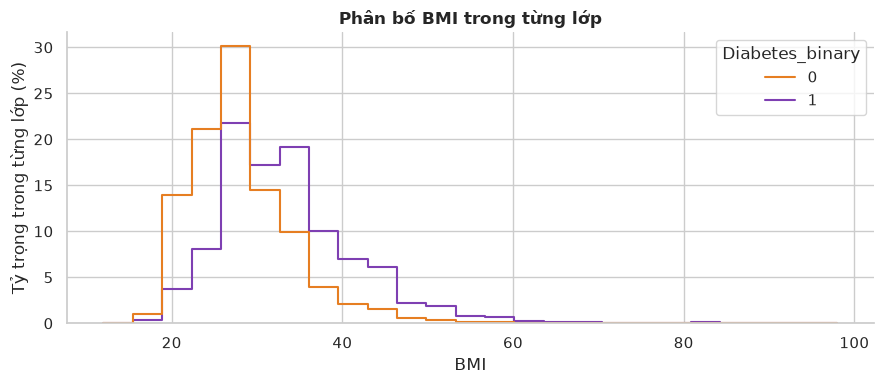

,Diabetes_binary,count,mean,median
0,0,83137,28.28,27.0
1,1,10192,33.60,32.0


**Nhận xét:** Phân bố BMI của nhóm nhãn 1 dịch sang phía giá trị cao hơn nhóm nhãn 0, với trung vị lần lượt là 32 và 27. Tuy nhiên, hai phân bố vẫn chồng lấp đáng kể, cho thấy BMI có liên hệ với nhãn nhưng chưa đủ để phân loại riêng lẻ. Cần xem xét BMI cùng tuổi, tình trạng sức khỏe và các đặc trưng khác; kết quả này chưa chứng minh quan hệ nhân quả.

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=df_eda,
    x="BMI",
    hue=TARGET,
    hue_order=[0, 1],
    bins=25,
    stat="percent",
    common_norm=False,
    common_bins=True,
    element="step",
    fill=False,
    palette=PALETTE,
    ax=ax,
)
ax.set(
    title="Phân bố BMI trong từng lớp",
    xlabel="BMI",
    ylabel="Tỷ trọng trong từng lớp (%)",
)
fig.tight_layout()
save_and_show_figure("eda_07_bmi_by_target", fig)

bmi_stats=train_data.groupby(TARGET).BMI.agg(count='count',mean='mean',median='median').reset_index()
display(bmi_stats.round(2));save_frame(bmi_stats,'eda_bmi_by_target')
note(
    "**Nhận xét:** Phân bố BMI của nhóm nhãn 1 dịch sang phía giá trị cao hơn nhóm nhãn 0, với trung vị lần lượt là 32 và 27. Tuy nhiên, hai phân bố vẫn chồng lấp đáng kể, cho thấy BMI có liên hệ với nhãn nhưng chưa đủ để phân loại riêng lẻ. Cần xem xét BMI cùng tuổi, tình trạng sức khỏe và các đặc trưng khác; kết quả này chưa chứng minh quan hệ nhân quả."
)


## 1.3. Quan hệ kết hợp và tương quan

### a. Các cặp biến theo giả thuyết từ mục 1.2

Mỗi ô ghi **tỷ lệ lớp 1 và số hồ sơ n**. Ô trống có n=0; nhóm không gán tỷ lệ 0% cho ô thiếu dữ liệu.
Nhóm BMI chỉ phục vụ EDA, không thay thế đặc trưng BMI đưa vào mô hình.

Nhóm đặt trần màu theo tỷ lệ lớn nhất trong bảng, làm tròn lên bội số 5 điểm phần trăm. Thang màu thể hiện khoảng tỷ lệ quan sát, không chạy đến 100%.


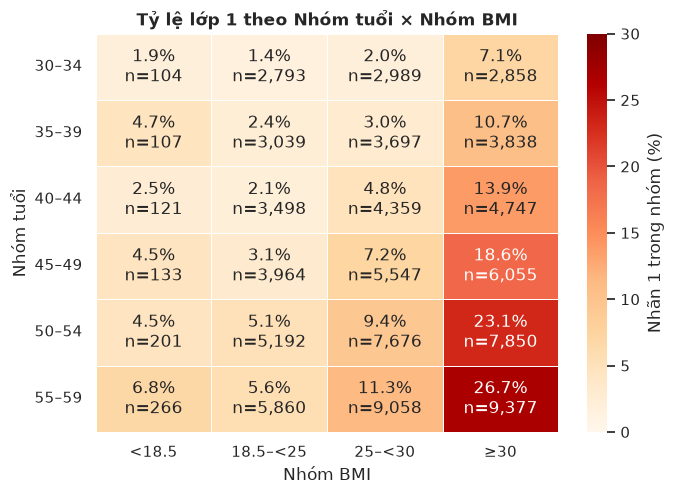

Tỷ lệ cao nhất ở tuổi 55–59, BMI ≥30: 26.72%, n=9,377. Chưa kiểm định tương tác thống kê.

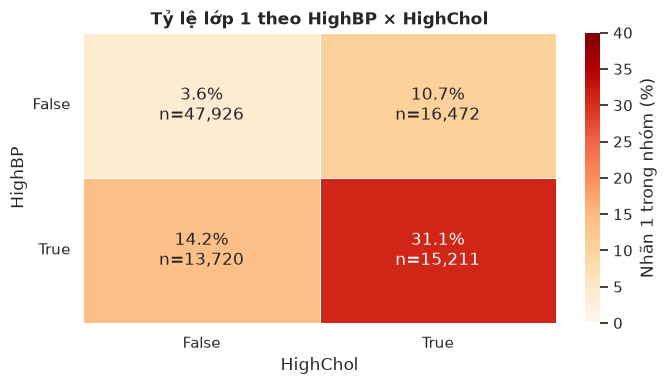

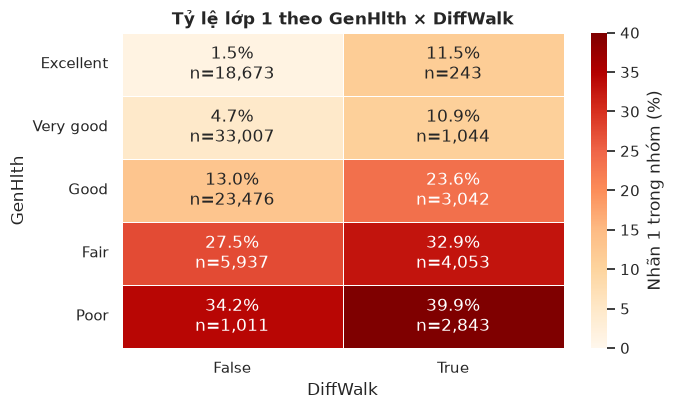

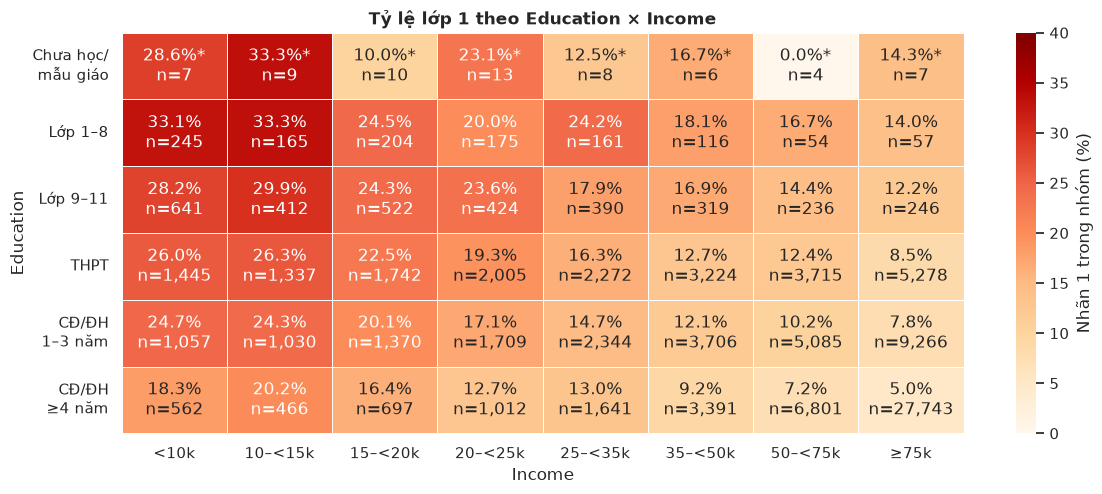

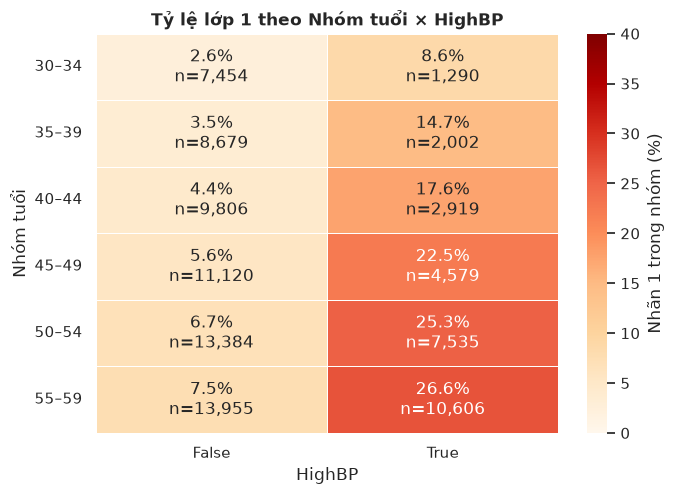

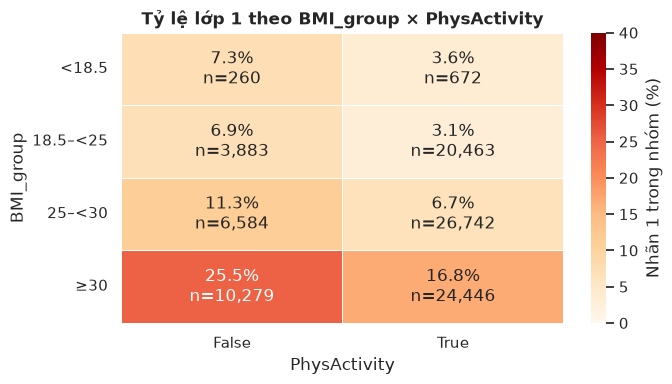

Mỗi ô có tỷ lệ lớp 1 và số hồ sơ; ô trống có n=0, dấu * là n<30. Các cặp bổ sung dùng chung thang màu. Kết quả chưa chứng minh nhân quả hoặc đóng góp riêng trong mô hình.

In [13]:
bmi_labels=["<18.5","18.5–<25","25–<30","≥30"]
pair_data=train_data.copy()
pair_data["BMI_group"]=np.select([pair_data.BMI.lt(18.5),pair_data.BMI.lt(25),pair_data.BMI.lt(30)],[0,1,2],default=3)
def grouped_pair(a,b):
    return pair_data.groupby([a,b])[TARGET].agg(sample_count="size",positive_count="sum",positive_rate=lambda x:100*x.mean()).reset_index()
age_bmi_summary=grouped_pair("Age","BMI_group").rename(columns={"BMI_group":"bmi_position"})
full_index=pd.MultiIndex.from_product([ORDINAL_DOMAINS["Age"],range(4)],names=["Age","bmi_position"])
age_bmi_summary=age_bmi_summary.set_index(["Age","bmi_position"]).reindex(full_index).reset_index()
age_bmi_summary["sample_count"]=age_bmi_summary.sample_count.fillna(0).astype(int)
age_bmi_summary["BMI_group"]=age_bmi_summary.bmi_position.map(dict(enumerate(bmi_labels)))
save_frame(age_bmi_summary[["Age","bmi_position","BMI_group","sample_count","positive_rate"]],"age_bmi_summary")
for value,name in [("positive_rate","age_bmi_positive_rates"),("sample_count","age_bmi_counts")]:
    wide=age_bmi_summary.pivot(index="Age",columns="bmi_position",values=value).rename(columns=dict(enumerate(bmi_labels)))
    if value=="positive_rate":wide=wide/100
    save_frame(wide.reset_index(),name)
def pair_plot(result,a,b,row_levels,col_levels,row_labels,col_labels,name,vmax=None):
    idx=pd.MultiIndex.from_product([row_levels,col_levels],names=[a,b])
    matrix=result.set_index([a,b]).reindex(idx)
    sizes=matrix.sample_count.fillna(0).to_numpy().reshape(len(row_levels),len(col_levels)).astype(int)
    rates=matrix.positive_rate.to_numpy().reshape(sizes.shape)
    annotations=np.full(sizes.shape,"",dtype=object)
    for i,j in np.ndindex(sizes.shape):
        if sizes[i,j]:annotations[i,j]=f"{rates[i,j]:.1f}%{'*' if sizes[i,j]<30 else ''}\nn={sizes[i,j]:,}"
    maximum=vmax if vmax is not None else max(5,np.ceil(np.nanmax(rates)/5)*5)
    fig,ax=plt.subplots(figsize=(max(7,len(col_levels)*1.5),max(4,len(row_levels)*.85)))
    sns.heatmap(rates,mask=sizes==0,annot=annotations,fmt="",cmap="OrRd",vmin=0,vmax=maximum,linewidths=.5,xticklabels=col_labels,yticklabels=row_labels,cbar_kws={"label":"Nhãn 1 trong nhóm (%)"},ax=ax)
    axis_a="Nhóm tuổi" if a=="Age" else a
    axis_b="Nhóm BMI" if b=="bmi_level" else b
    ax.set(title=f"Tỷ lệ lớp 1 theo {axis_a} × {axis_b}",xlabel=axis_b,ylabel=axis_a);ax.tick_params(axis="y",rotation=0)
    fig.tight_layout();save_and_show_figure(name,fig)
pair_plot(age_bmi_summary.rename(columns={"bmi_position":"bmi_level"}),"Age","bmi_level",ORDINAL_DOMAINS["Age"],list(range(4)),AGE_LABELS,bmi_labels,"eda_08_age_bmi")
peak=age_bmi_summary[age_bmi_summary.sample_count.gt(0)].sort_values(["positive_rate","Age","bmi_position"],ascending=[False,True,True]).iloc[0]
note(f"Tỷ lệ cao nhất ở tuổi {LABEL_MAPS['Age'][peak.Age]}, BMI {peak.BMI_group}: {peak.positive_rate:.2f}%, n={peak.sample_count:,}. Chưa kiểm định tương tác thống kê.")
pair_specs=[("HighBP","HighChol",[0,1],[0,1],["False","True"],["False","True"]),("GenHlth","DiffWalk",ORDINAL_DOMAINS["GenHlth"],[0,1],GEN_LABELS,["False","True"]),("Education","Income",ORDINAL_DOMAINS["Education"],ORDINAL_DOMAINS["Income"],EDU_LABELS,INCOME_LABELS),("Age","HighBP",ORDINAL_DOMAINS["Age"],[0,1],AGE_LABELS,["False","True"]),("BMI_group","PhysActivity",list(range(4)),[0,1],bmi_labels,["False","True"])]
pair_results=[(spec,grouped_pair(spec[0],spec[1])) for spec in pair_specs]
pair_vmax=max(5,np.ceil(max(frame.positive_rate.max() for _,frame in pair_results)/5)*5)
for (a,b,rows,cols,rl,cl),frame in pair_results:
    save_frame(frame.rename(columns={a:"row_level",b:"col_level"}),f"eda_pair_{a}_{b}")
    pair_plot(frame,a,b,rows,cols,rl,cl,f"eda_pair_{a}_{b}",vmax=pair_vmax)
note("Mỗi ô có tỷ lệ lớp 1 và số hồ sơ; ô trống có n=0, dấu * là n<30. Các cặp bổ sung dùng chung thang màu. Kết quả chưa chứng minh nhân quả hoặc đóng góp riêng trong mô hình.")


### b. Tương quan

Heatmap chỉ hiển thị tam giác dưới để tránh lặp các cặp biến. Pearson trên mã thứ bậc
phụ thuộc cách biểu diễn; các bảng hệ số được xuất ra CSV trong tables/ và feature_selection/.
Nhóm không dùng tương quan nhỏ làm lý do duy nhất để loại đặc trưng.


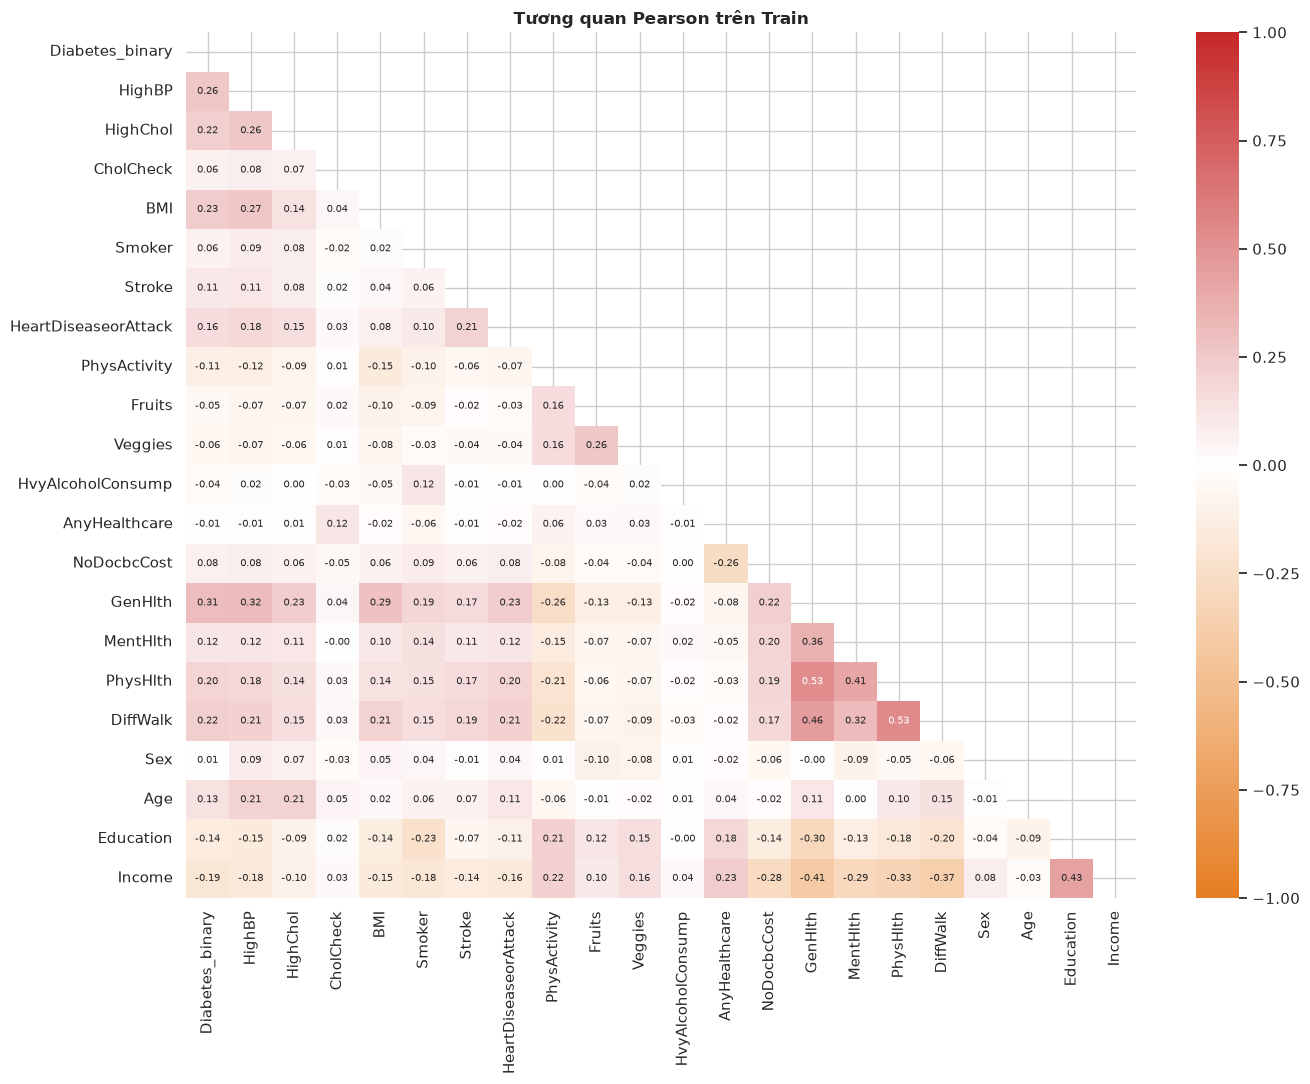

**Quan sát:** **GenHlth** có |Pearson| với nhãn lớn nhất (**r=0.312**). Có **0** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình.

In [14]:
from scipy import stats

correlation_columns = [TARGET] + FEATURES
values=train_data[correlation_columns].to_numpy(dtype=float)
pearson = np.corrcoef(values, rowvar=False)
spearman = stats.spearmanr(values, axis=0).statistic
correlation_target=pd.DataFrame({"Feature":FEATURES,"Pearson":pearson[1:,0],"Spearman":spearman[1:,0]})
correlation_pairs=pd.DataFrame([{"Feature A":a,"Feature B":b,"Pearson":pearson[i+1,j+1]} for i,a in enumerate(FEATURES) for j,b in enumerate(FEATURES) if i<j])
mask = np.triu(np.ones(pearson.shape, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    pearson,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=CORRELATION_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7},
    xticklabels=correlation_columns,
    yticklabels=correlation_columns,
    ax=ax,
)
ax.set_title("Tương quan Pearson trên Train")
fig.tight_layout()
save_and_show_figure("eda_09_correlation", fig)
save_frame(correlation_target,"correlation_target")
strongest=correlation_target.iloc[correlation_target.Pearson.abs().to_numpy().argmax()].to_dict()
strong_pairs=int(correlation_pairs.Pearson.abs().gt(.8).sum())
note(
    f"**Quan sát:** **{strongest['Feature']}** có |Pearson| với nhãn lớn nhất (**r={strongest['Pearson']:.3f}**). Có **{strong_pairs}** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình."
)


# V. Chuẩn bị và lựa chọn đặc trưng

## 2.1. CATEGORICAL ENCODING & FEATURE SCALING

| Nhánh mô hình | Biến số | Mã thứ bậc | Nhị phân | Số cột sau tiền xử lý bộ 21 |
|---|---|---|---|---|
| Logistic Regression | StandardScaler: BMI, MentHlth, PhysHlth | One-Hot drop-first: Age, Education, Income, GenHlth | bool; có thể chuyển 0/1 khi ghép ma trận | 38 |
| Decision Tree, Random Forest, XGBoost | Giữ giá trị gốc | Giữ mã số | bool; có thể chuyển 0/1 khi ghép ma trận | 21 |

Mục này minh họa tiền xử lý cho 21 biến gốc. StandardScaler đổi thang đo, không biến phân bố thành phân bố chuẩn và không loại ngoại lệ. Tên hiển thị trong EDA không thay thế dữ liệu số. Ở Phần 3, scaler/encoder chỉ fit trên Train, sau đó transform Test. Các cây không cần chuẩn hóa cùng thang đo vì phân nhánh theo ngưỡng của từng feature. Bảng demo bên dưới dùng hai phần bên trong Train để kiểm tra fit/transform của preprocessing, chưa huấn luyện mô hình.


In [15]:
def make_preprocessor(feature_set="full_21", family="linear"):
    cols = FEATURE_SETS[feature_set]
    numeric = [c for c in NUMERIC_FEATURES if c in cols]
    ordinal = [c for c in ORDINAL_DOMAINS if c in cols]
    binary = [c for c in cols if c not in numeric + ordinal]

    if family == "linear":
        transforms = [
            ("numeric", StandardScaler(), numeric),
            (
                "ordinal",
                OneHotEncoder(
                    categories=[ORDINAL_DOMAINS[c] for c in ordinal],
                    drop="first",
                    handle_unknown="error",
                    sparse_output=False,
                ),
                ordinal,
            ),
            ("binary", "passthrough", binary),
        ]
    elif family == "tree":
        transforms = [("features", "passthrough", cols)]
    else:
        raise ValueError(f"Family không hợp lệ: {family}")

    return ColumnTransformer(transforms, remainder="drop")


def make_pipeline(model, feature_set="full_21", family="linear"):
    return Pipeline(
        [
            ("preprocess", make_preprocessor(feature_set, family)),
            ("model", clone(model)),
        ]
    )


print("Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!")


Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!


In [16]:
demo_rows=[]
fit_data=joined.loc[joined.split.eq("train")&joined.cv_fold.ne(0),FEATURES].astype("int16")
val_data=joined.loc[joined.split.eq("train")&joined.cv_fold.eq(0),FEATURES].astype("int16")
fit_data[BINARY]=fit_data[BINARY].astype(bool);val_data[BINARY]=val_data[BINARY].astype(bool)
for family in ["linear","tree"]:
    demo=make_preprocessor("full_21",family)
    fit_values=demo.fit_transform(fit_data);val_values=demo.transform(val_data)
    expected=38 if family=="linear" else 21
    assert fit_values.shape[1]==val_values.shape[1]==expected
    demo_rows.append({"FeatureSet":"full_21","Family":family,"Fit rows":len(fit_data),"Validation rows":len(val_data),"Columns":expected})
preprocessor_demo=pd.DataFrame(demo_rows);display(preprocessor_demo);save_frame(preprocessor_demo,"preprocessor_demo")


,FeatureSet,Family,Fit rows,Validation rows,Columns
0,full_21,linear,74662,18667,38
1,full_21,tree,74662,18667,21


### c. VIF: kiểm tra phụ thuộc tuyến tính giữa các feature

Tính VIF cho **21 biến X, không đưa nhãn y vào**. Với dữ liệu được định tâm và chuẩn hóa, VIF là đường chéo của nghịch đảo ma trận tương quan giữa X, tương đương hồi quy từng feature theo các feature còn lại có hệ số chặn. Mã thứ bậc vẫn được xem tuyến tính trong phép kiểm tra này, nên VIF chỉ là chỉ báo bổ sung cho phiên bản X số gốc.

,Feature,VIF
13,GenHlth,1.826
15,PhysHlth,1.741
16,DiffWalk,1.612
20,Income,1.595
19,Education,1.339
14,MentHlth,1.307
0,HighBP,1.260
12,NoDocbcCost,1.174
3,BMI,1.164
1,HighChol,1.151


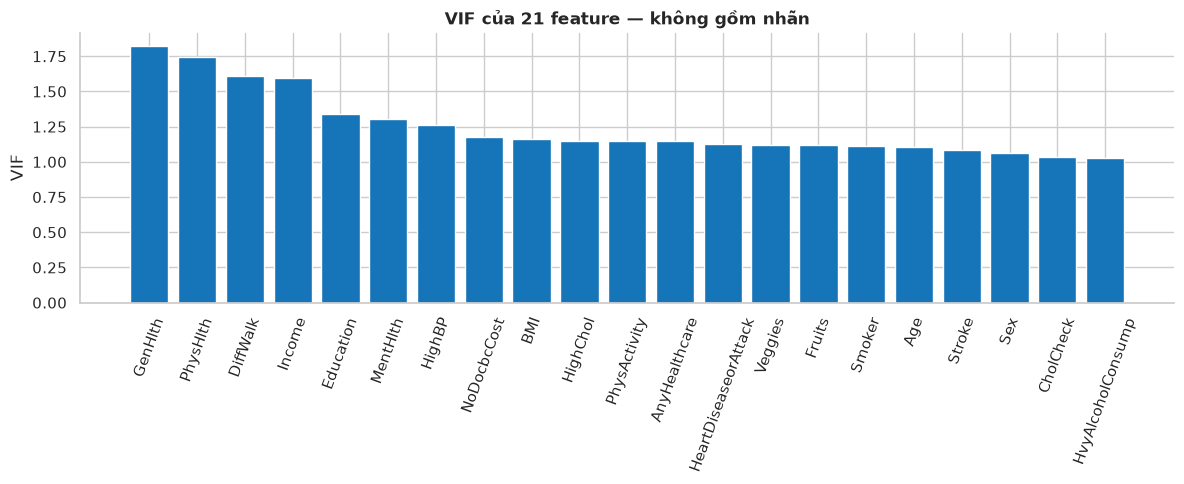

**Nhận xét:** VIF cao nhất là **GenHlth = 1.826**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này.

In [17]:
vif_values = X_train.to_numpy(dtype=float)
standardized = (vif_values - vif_values.mean(axis=0)) / vif_values.std(axis=0, ddof=0)
vif_correlation = np.corrcoef(standardized, rowvar=False)
assert np.linalg.matrix_rank(vif_correlation) == len(FEATURES)
vif = np.diag(np.linalg.inv(vif_correlation))
assert np.all(vif >= 1 - 1e-8)
vif_results=pd.DataFrame({"Feature":FEATURES,"VIF":vif}).sort_values(["VIF","Feature"],ascending=[False,True])
display(vif_results.round(3));save_frame(vif_results,"ref_vif");values=vif_results.to_dict("records")
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([r["Feature"] for r in values], [r["VIF"] for r in values], color=BLUE)
ax.set(title="VIF của 21 feature — không gồm nhãn", ylabel="VIF")
ax.tick_params(axis="x", rotation=70)
fig.tight_layout()
save_and_show_figure("ref_12_vif", fig)
note(
    f"**Nhận xét:** VIF cao nhất là **{values[0]['Feature']} = {values[0]['VIF']:.3f}**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này."
)


### d. ANOVA F-score và Chi-square: xếp hạng đơn biến

Tham khảo `SelectKBest`/`f_classif` và `chi2` của notebook nguồn, nhưng giữ tên feature và xuất đầy đủ điểm/rank. ANOVA F-score so sánh trung bình feature giữa hai lớp; với biến rời rạc/nhị phân đây chỉ là xếp hạng khám phá, chưa xác nhận các giả định kiểm định. `chi2` yêu cầu đầu vào không âm; các điểm trên biến số phụ thuộc thang đo nên không được diễn giải như độ quan trọng độc lập. Hai phép tính dùng **X số gốc trước StandardScaler**, chỉ trên Train. P-value chưa tính trọng số/thiết kế khảo sát BRFSS.

,Feature,Pearson,ANOVA_F,ANOVA_p,Chi2_score,Chi2_p,ANOVA_p_BH,Chi2_p_BH,ANOVA_rank,Chi2_rank
13,GenHlth,0.31228,10084.82980,0.00000,4178.37856,0.00000,0.00000,0.00000,1,5
0,HighBP,0.26173,6863.41202,0.00000,4411.50005,0.00000,0.00000,0.00000,2,4
3,BMI,0.23479,5445.15329,0.00000,8932.31082,0.00000,0.00000,0.00000,3,3
16,DiffWalk,0.22212,4843.50617,0.00000,4050.82184,0.00000,0.00000,0.00000,4,6
1,HighChol,0.22004,4748.65097,0.00000,2984.79118,0.00000,0.00000,0.00000,5,7
15,PhysHlth,0.19772,3796.85896,0.00000,64767.01188,0.00000,0.00000,0.00000,6,1
20,Income,-0.19368,3637.22799,0.00000,2316.65237,0.00000,0.00000,0.00000,7,8
6,HeartDiseaseorAttack,0.16058,2470.24258,0.00000,2302.93575,0.00000,0.00000,0.00000,8,9
19,Education,-0.14063,1882.90750,0.00000,333.70360,0.00000,0.00000,0.00000,9,13
18,Age,0.13452,1720.02924,0.00000,747.96251,0.00000,0.00000,0.00000,10,11


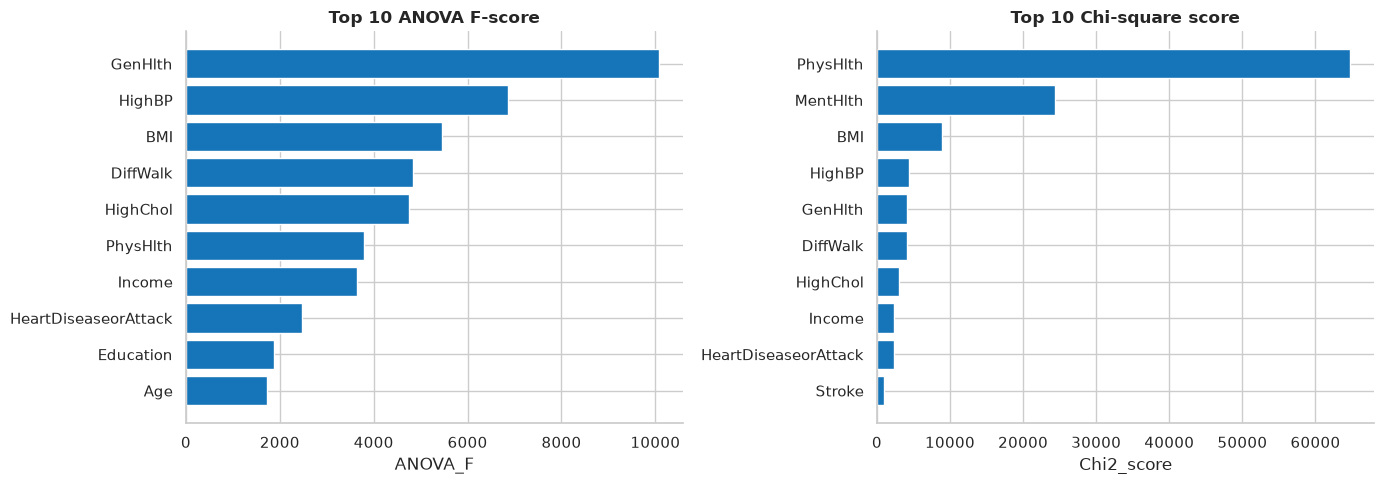

Kiểm định bằng sklearn/SciPy, tổng hợp và xếp hạng bằng pandas. Không tự động loại biến chỉ vì p-value hoặc điểm đơn biến; p nhỏ không đồng nghĩa hiệu ứng lớn.

In [18]:
from sklearn.feature_selection import f_classif,chi2
assert X_train.to_numpy().min()>=0
f_scores,f_p=f_classif(X_train.to_numpy(),y_train);chi_scores,chi_p=chi2(X_train.to_numpy(),y_train)
f_bh=stats.false_discovery_control(f_p,method="bh");chi_bh=stats.false_discovery_control(chi_p,method="bh")
feature_ranking=pd.DataFrame({"Feature":FEATURES,"Pearson":correlation_target.Pearson,"ANOVA_F":f_scores,"ANOVA_p":f_p,"Chi2_score":chi_scores,"Chi2_p":chi_p,"ANOVA_p_BH":f_bh,"Chi2_p_BH":chi_bh})
feature_ranking["ANOVA_rank"]=feature_ranking.ANOVA_F.rank(method="min",ascending=False).astype(int)
feature_ranking["Chi2_rank"]=feature_ranking.Chi2_score.rank(method="min",ascending=False).astype(int)
display(feature_ranking.sort_values("ANOVA_rank",kind="stable").round(5));save_frame(feature_ranking,"ref_feature_ranking")
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metric,title in [(axes[0],"ANOVA_F","Top 10 ANOVA F-score"),(axes[1],"Chi2_score","Top 10 Chi-square score")]:
    values=feature_ranking.nlargest(10,metric,keep="first").sort_values(metric,kind="stable")
    ax.barh(values.Feature,values[metric],color=BLUE);ax.set(title=title,xlabel=metric)
fig.tight_layout();save_and_show_figure("ref_13_feature_ranking",fig)
note("Kiểm định bằng sklearn/SciPy, tổng hợp và xếp hạng bằng pandas. Không tự động loại biến chỉ vì p-value hoặc điểm đơn biến; p nhỏ không đồng nghĩa hiệu ứng lớn.")


## Các bộ đặc trưng và phương án lấy mẫu
Giữ các bộ 21, 18, 16, 13 và 10. Bộ 10 thay một số biến thành phần bằng bốn biến kết hợp: `AgeBMI=(Age*5+17)*BMI`, `BPCholState=2*HighBP+HighChol`, `LowEducationLowIncome=(Education<=3)&(Income<=3)`, `PoorHealthDiffWalk=(GenHlth>=4)&DiffWalk`.

Bộ 10 giữ thêm Stroke, HeartDiseaseorAttack, PhysActivity, GenHlth, MentHlth, PhysHlth. Việc nén thông tin có thể làm mất chi tiết; bộ 10 là giả thuyết rút gọn từ EDA trên Train, không phải bộ tối ưu đã xác nhận. BPCholState là biến danh nghĩa, Age dùng trung điểm nhóm xấp xỉ.

Weighted dùng trọng số lớp trên Train. NearMiss-1/k3 giữ toàn bộ ca dương và chọn ca âm qua khoảng cách chuẩn hóa/mã hóa. SMOTENC/k5 tạo mẫu lớp thiểu số trên Train; bộ 10 mã hóa chung GenHlth và PoorHealthDiffWalk để giữ tổ hợp hợp lệ. Các biến ngày tổng hợp có thể có phần thập phân. Test giữ nguyên. Khi đã cân bằng 1:1, trọng số lớp tính lại bằng 1; chênh lệch so với weighted phản ánh đồng thời lấy mẫu và thay đổi trọng số.


In [19]:
selection_sets = {"full_21": FEATURES.copy(),
"compact_13": ["HighBP","HighChol","BMI","Stroke","HeartDiseaseorAttack","PhysActivity","GenHlth","MentHlth","PhysHlth","DiffWalk","Age","Education","Income"],
"replacement_10": ["Stroke","HeartDiseaseorAttack","PhysActivity","GenHlth","MentHlth","PhysHlth","AgeBMI","BPCholState","LowEducationLowIncome","PoorHealthDiffWalk"]}
display(pd.DataFrame([{"Bộ":k,"Số biến":len(v),"Các biến":", ".join(v)} for k,v in selection_sets.items()]))


,Bộ,Số biến,Các biến
0,full_21,21,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro..."
1,compact_13,13,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorA..."
2,replacement_10,10,"Stroke, HeartDiseaseorAttack, PhysActivity, Ge..."


## Hàm tiền xử lý và các mô hình
Các hàm được định nghĩa trực tiếp trong notebook; không tạo hoặc nạp script Python riêng.


In [20]:
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits
import sklearn
import xgboost

def study_preprocessor(cols, linear):
    numeric = [c for c in ["BMI", "MentHlth", "PhysHlth", "AgeBMI"] if c in cols]
    domains = {"Age":list(range(3,9)), "Education":list(range(1,7)), "Income":list(range(1,9)), "GenHlth":list(range(1,6))}
    ordinal = [c for c in domains if c in cols]
    nominal = ["BPCholState"] if "BPCholState" in cols else []
    transforms = []
    if numeric:
        transforms.append(("numeric", StandardScaler() if linear else "passthrough", numeric))
    if ordinal:
        encoder = OneHotEncoder(categories=[domains[c] for c in ordinal], drop="first", sparse_output=False, handle_unknown="error")
        transforms.append(("ordinal", encoder if linear else "passthrough", ordinal))
    if nominal:
        transforms.append(("nominal", OneHotEncoder(categories=[[0,1,2,3]], drop="first", sparse_output=False, handle_unknown="error"), nominal))
    binary = [c for c in cols if c not in numeric+ordinal+nominal]
    if binary:
        transforms.append(("binary", "passthrough", binary))
    return ColumnTransformer(transforms, remainder="drop")

def study_models(seed, ratio):
    return [
        ("LogisticRegression", True, LogisticRegression(C=1.0, solver="lbfgs", max_iter=1500, random_state=seed, class_weight="balanced")),
        ("DecisionTree", False, DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=seed, class_weight="balanced")),
        ("RandomForest", False, RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_leaf=20, n_jobs=4, random_state=seed, class_weight="balanced")),
        ("XGBoost", False, XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, n_jobs=4, random_state=seed, eval_metric="logloss", scale_pos_weight=ratio)),
    ]


## Hàm thực hiện 120 cấu hình
Đầu vào là dữ liệu và manifest trong bộ nhớ. Hàm chuẩn bị lấy mẫu, huấn luyện, lưu dự đoán và kiểm tra chỉ số. Model/cache là đầu ra để tái sử dụng.


In [21]:
from pathlib import Path
import sys
import json
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

def run_comparison(context,base,original,seed=42):
    base=Path(base)
    from imblearn.under_sampling import NearMiss
    from imblearn.over_sampling import SMOTENC
    out=base/"comparison_10_13_16_18_21"
    out.mkdir(exist_ok=True);(out/"models").mkdir(exist_ok=True)
    saved_sets=selection_sets
    sets={"replacement_10":saved_sets["replacement_10"],"compact_13":saved_sets["compact_13"],
          "reduced_16":[c for c in original if c not in ["Fruits","Veggies","Sex","CholCheck","AnyHealthcare"]],
          "reduced_18":[c for c in original if c not in ["Stroke","Sex","PhysHlth"]],"full_21":original.copy()}
    assert [len(v) for v in sets.values()]==[10,13,16,18,21]
    protocol=dict(feature_sets=sets,seed=seed,expected_configurations=120,reused=0,new_fits=120,
                  methods=["weighted","NearMiss","SMOTENC"],threshold=0.5,
                  sampling="Train only; separate keep/no duplicates; full original22-column dedup key",
                  nearmiss="version1,k3,ratio1.0,scaled numeric and one-hot categorical distance",
                  smotenc="k5,ratio1.0,scaled numeric; original ordinals/binary treated as categorical",
                  weighting="weighted: original Train counts; resampled methods: sampled counts balanced=1",
                  limitations="Previously viewed Test; exploratory; no Test-based tuning/promotion; sampling changes weights too",
                  reused10_smotenc="GenHlth+PoorHealthDiffWalk encoded jointly to preserve logical combinations")
    frozen=out/"frozen_design.json"
    if frozen.exists():assert json.loads(frozen.read_text(encoding="utf-8"))==protocol
    else:frozen.write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding="utf-8")
    # pandas performs feature creation, joins, filtering, and source-order checks.
    model_data=context["clean_data"].copy()
    model_data["BPCholState"]=2*model_data.HighBP+model_data.HighChol
    model_data["AgeBMI"]=(model_data.Age*5+17)*model_data.BMI
    model_data["LowEducationLowIncome"]=((model_data.Education<=3)&(model_data.Income<=3)).astype(int)
    model_data["PoorHealthDiffWalk"]=((model_data.GenHlth>=4)&(model_data.DiffWalk==1)).astype(int)
    merged=model_data.merge(context["manifest"],on="row_id",how="inner",validate="one_to_one",sort=False)
    feature_columns=list(dict.fromkeys(c for values in sets.values() for c in values))
    columns=["row_id","Diabetes_binary"]+feature_columns
    test=merged.loc[merged.split.eq("test"),columns].sort_values("row_id").reset_index(drop=True)
    common=test.row_id.isin(context["dedup_ids"]).to_numpy()
    assert len(test)==23333 and common.sum()==20568
    assert context["manifest"].groupby("group_id").split.nunique().max()==1
    test_hash=hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()
    frames={}
    for dataset in ["keep_duplicates","no_duplicates"]:
        mask=merged.split.eq("train")
        if dataset=="no_duplicates":mask &= merged.row_id.isin(context["dedup_ids"])
        frames[dataset]=merged.loc[mask,columns].sort_values("row_id").reset_index(drop=True)
    for frame in frames.values():assert not set(frame.row_id)&set(test.row_id)
    reused=pd.DataFrame()
    new_file=out/"new_metrics.csv"
    new_metrics=pd.read_csv(new_file).to_dict("records") if new_file.exists() else []
    audit_file=out/"fit_audit.json"
    audit=json.loads(audit_file.read_text()) if audit_file.exists() else []
    counts=[]
    numeric_all=["BMI","MentHlth","PhysHlth","AgeBMI"]
    categorical_all=[c for c in list(dict.fromkeys(c for values in sets.values() for c in values)) if c not in numeric_all]
    for fs,cols in sets.items():
        for method in ["weighted","NearMiss","SMOTENC"]:
            for dataset,frame in frames.items():
                x=frame[cols].copy();y=frame.Diabetes_binary.to_numpy(dtype=int)
                bool_cols=[c for c in cols if c not in numeric_all+["Age","Education","Income","GenHlth","BPCholState"]]
                x[bool_cols]=x[bool_cols].astype(bool)
                if method=="weighted":sample_x=x;sample_y=y
                elif method=="NearMiss":
                    distance=study_preprocessor(cols,True)
                    with threadpool_limits(limits=4):
                        encoded=distance.fit_transform(x)
                        sampler=NearMiss(version=1,n_neighbors=3,sampling_strategy=1.0,n_jobs=4)
                        _,sample_y=sampler.fit_resample(encoded,y)
                    ids=sampler.sample_indices_
                    assert set(np.flatnonzero(y==1))==set(ids[y[ids]==1])
                    sample_x=x.iloc[ids].reset_index(drop=True)
                    frame.iloc[ids][["row_id","Diabetes_binary"]].to_csv(out/f"{fs}__{dataset}__NearMiss_selected_ids.csv",index=False)
                    joblib.dump(distance,out/f"{fs}__{dataset}__NearMiss_distance.joblib")
                else:
                    numeric=[c for c in cols if c in numeric_all]
                    categorical=[c for c in cols if c in categorical_all]
                    joint_health = fs == "replacement_10"
                    if joint_health:
                        numeric=["AgeBMI","MentHlth","PhysHlth"]
                        categorical=["Stroke","HeartDiseaseorAttack","PhysActivity","BPCholState","LowEducationLowIncome"]
                    scaler=StandardScaler()
                    encoded=pd.DataFrame(scaler.fit_transform(x[numeric]),columns=numeric)
                    for c in categorical:encoded[c]=x[c].astype(int).to_numpy()
                    if joint_health: encoded["HealthWalkJoint"]=(2*x.GenHlth+x.PoorHealthDiffWalk.astype(int)).to_numpy()
                    sampler=SMOTENC(categorical_features=list(range(len(numeric),len(encoded.columns))),k_neighbors=5,sampling_strategy=1.0,random_state=seed)
                    with threadpool_limits(limits=4):resampled,sample_y=sampler.fit_resample(encoded,y)
                    resampled=pd.DataFrame(resampled,columns=encoded.columns)
                    sample_x=pd.DataFrame(scaler.inverse_transform(resampled[numeric]),columns=numeric)
                    for c in categorical:
                        sample_x[c]=resampled[c].astype(int)
                        assert set(sample_x[c]).issubset(set(x[c].astype(int)))
                    if joint_health:
                        joint=resampled["HealthWalkJoint"].astype(int)
                        sample_x["GenHlth"]=joint//2
                        sample_x["PoorHealthDiffWalk"]=joint%2
                        assert not ((sample_x.PoorHealthDiffWalk==1)&(sample_x.GenHlth<4)).any()
                    sample_x=sample_x[cols]
                    assert np.allclose(sample_x.iloc[:len(x)].astype(float),x.astype(float))
                    assert np.array_equal(sample_y[:len(y)],y)
                    for c in numeric:assert sample_x[c].between(x[c].min()-1e-8,x[c].max()+1e-8).all()
                    np.savez_compressed(out/f"{fs}__{dataset}__SMOTENC_train.npz",X=sample_x.to_numpy(dtype=float),y=sample_y,columns=np.array(cols),original_row_ids=frame.row_id.to_numpy())
                    joblib.dump(scaler,out/f"{fs}__{dataset}__SMOTENC_scaler.joblib")
                sample_x[bool_cols]=sample_x[bool_cols].astype(bool)
                n0=int((sample_y==0).sum());n1=int((sample_y==1).sum())
                if method!="weighted":assert n0==n1
                counts.append(dict(FeatureSet=fs,Dataset=dataset,Method=method,OriginalRows=len(x),OriginalClass0=int((y==0).sum()),OriginalClass1=int((y==1).sum()),SampledRows=len(sample_x),SampledClass0=n0,SampledClass1=n1))
                pd.DataFrame(counts).to_csv(out/"train_counts_new_arms.csv",index=False)
                print(f"Prepared {fs}/{method}/{dataset}: {len(x)} -> {len(sample_x)}",flush=True)
                for name,linear,model in study_models(seed,n0/n1):
                    key=f"{fs}__{dataset}__{name}__{method}"
                    if any(r["Config"]==key for r in new_metrics):continue
                    model_path=out/"models"/(key+".joblib")
                    if model_path.exists():raise RuntimeError(f"Partial model already exists: {key}")
                    start=time.monotonic()
                    pipeline=Pipeline([("preprocess",study_preprocessor(cols,linear)),("model",model)])
                    xt=test[cols].copy();xt[bool_cols]=xt[bool_cols].astype(bool)
                    with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=4):
                        warnings.simplefilter("always",ConvergenceWarning)
                        pipeline.fit(sample_x,sample_y)
                        predicted=pipeline.predict(xt).astype(int)
                        probability=pipeline.predict_proba(xt)[:,1]
                    assert np.array_equal(predicted,(probability>0.5).astype(int))
                    joblib.dump(pipeline,model_path)
                    np.savez_compressed(out/(key+"_predictions.npz"),row_id=test.row_id.to_numpy(),actual=test.Diabetes_binary.to_numpy(),common=common,predicted=predicted,probability=probability)
                    for view in ["native","common"]:
                        mask=common if view=="common" or dataset=="no_duplicates" else np.ones(len(test),dtype=bool)
                        a=test.Diabetes_binary.to_numpy()[mask];p=predicted[mask]
                        tn,fp,fn,tp=map(int,confusion_matrix(a,p,labels=[0,1]).ravel())
                        vals=[(tn+tp)/len(a),tp/(tp+fp) if tp+fp else 0,tp/(tp+fn),2*tp/(2*tp+fp+fn)]
                        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]
                        assert np.allclose(vals,checks,atol=1e-14)
                        new_metrics.append(dict(Config=key,FeatureSet=fs,Features=len(cols),Dataset=dataset,Method=method,Model=name,TestView=view,TestRows=len(a),TN=tn,FP=fp,FN=fn,TP=tp,Accuracy=vals[0],Precision=vals[1],Recall=vals[2],F1=vals[3],Source="comparison_10_13_16_18_21/new_metrics.csv"))
                    audit.append(dict(Config=key,seconds=time.monotonic()-start,TrainRows=len(sample_x),Class0=n0,Class1=n1,parameters=model.get_params(),warnings=[str(w.message) for w in caught]))
                    pd.DataFrame(new_metrics).to_csv(new_file,index=False)
                    audit_file.write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding="utf-8")
                    (out/"status.json").write_text(json.dumps(dict(status="running",new_fits=len(audit),expected=120,last=key),indent=2),encoding="utf-8")
                    print(f"[{len(audit)}/120] {key}",flush=True)
    assert len(audit)==120 and len(new_metrics)==240
    assert test_hash==hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()
    combined=pd.concat([reused,pd.DataFrame(new_metrics)],ignore_index=True)
    assert combined.Config.nunique()==120 and len(combined)==240
    assert combined.groupby(["FeatureSet","Dataset","Method","Model"]).size().eq(2).all()
    combined.to_csv(out/"all_metrics.csv",index=False)
    for view in ["native","common"]:
        subset=combined[combined.TestView==view]
        subset.to_csv(out/(view+"_metrics.csv"),index=False)
        wide=subset.pivot(index=["Features","FeatureSet","Dataset","Model"],columns="Method",values=["Accuracy","Precision","Recall","F1"])
        wide.columns=[f"{metric}_{method}" for metric,method in wide.columns]
        wide=wide.reset_index()
        for method in ["NearMiss","SMOTENC"]:
            wide[f"Delta_F1_{method}"]=wide[f"F1_{method}"]-wide.F1_weighted
        wide.to_csv(out/(view+"_comparison_wide.csv"),index=False)
    # Verify all 80 new models from saved predictions; reused studies already have verification reports.
    for r in new_metrics:
        z=np.load(out/(r["Config"]+"_predictions.npz"))
        mask=z["common"] if r["TestView"]=="common" or r["Dataset"]=="no_duplicates" else np.ones(len(z["actual"]),dtype=bool)
        a,p=z["actual"][mask],z["predicted"][mask]
        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]
        assert np.allclose([r[c] for c in ["Accuracy","Precision","Recall","F1"]],checks,atol=1e-14)
    report=dict(status="passed",configurations=120,metric_rows=240,new_fits=120,reused=0,
                common_test_rows=20568,test_rows=23333,test_unchanged=True,new_saved_predictions_checked=True,
                sampling_train_only=True,source_metrics_unrounded=True)
    (out/"verification.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
    (out/"status.json").write_text(json.dumps(dict(status="complete",new_fits=120,reused=0),indent=2),encoding="utf-8")
    return combined,out


# VI. Đối chiếu weighted / NearMiss / SMOTENC — bộ 10, 13, 16, 18, 21

Tổng hợp **120 cấu hình** = 5 bộ × 3 phương án × 2 bản Train × 4 mô hình; mỗi cấu hình có metrics trên Test tương ứng và Test chung. Bản final tự huấn luyện đủ 120 cấu hình từ dữ liệu Train, không phụ thuộc lượt huấn luyện cũ. Không dùng các điểm lịch sử làm tròn để thay thế baseline trong bảng này.

| Bộ | Định nghĩa |
|---|---|
| 10 | replacement_10: 6 biến gốc + 4 biến mới theo lựa chọn nhóm |
| 13 | compact_13 đã thống nhất, gồm MentHlth |
| 16 | reduced_16 cũ: bỏ Fruits, Veggies, Sex, CholCheck, AnyHealthcare khỏi 21 |
| 18 | reduced_18 cũ: bỏ Stroke, Sex, PhysHlth khỏi 21; không phải bộ thay thế trung gian 18 |
| 21 | Toàn bộ biến gốc |

Giữ tham số mô hình, seed42 và ngưỡng0.5 như các lượt trước. Weighted tính trọng số từ đúng Train gốc. NearMiss-1/k3 và SMOTENC/k5 chỉ xử lý Train, cân bằng1:1 nên trọng số tính lại bằng1. Khoảng cách dùng biến số chuẩn hóa và biến phân loại mã hóa trên riêng Train. GenHlth và các mã thứ bậc được xử lý phân loại trong SMOTENC; bộ10 dùng joint GenHlth/PoorHealthDiffWalk để giữ tổ hợp phân loại hợp lệ. Ngày sức khỏe tổng hợp có thể thập phân.

Các bảng chính đều dùng **cùng Test không duplicate n=20.568**; bản Train giữ/bỏ duplicate hiển thị riêng. File native_comparison_wide.csv lưu đối chiếu trên Test tương ứng. Accuracy/Precision/Recall/F1 đầy đủ trong all_metrics.csv và hai bảng wide. Delta tính phương án resampling trừ weighted ở đúng bộ feature/model/bản Train.

Test đã xem; các bảng mô tả kết quả nghiên cứu phát triển, chưa có CI hay xác nhận độc lập. Resampling và trọng số sau resampling cùng thay đổi nên không diễn giải delta là tác động lấy mẫu đơn thuần. Không dùng các cực đại quan sát để tự chọn lại feature/ngưỡng.


Prepared replacement_10/weighted/keep_duplicates: 93329 -> 93329
[1/120] replacement_10__keep_duplicates__LogisticRegression__weighted
[2/120] replacement_10__keep_duplicates__DecisionTree__weighted
[3/120] replacement_10__keep_duplicates__RandomForest__weighted
[4/120] replacement_10__keep_duplicates__XGBoost__weighted
Prepared replacement_10/weighted/no_duplicates: 82258 -> 82258
[5/120] replacement_10__no_duplicates__LogisticRegression__weighted
[6/120] replacement_10__no_duplicates__DecisionTree__weighted
[7/120] replacement_10__no_duplicates__RandomForest__weighted
[8/120] replacement_10__no_duplicates__XGBoost__weighted
Prepared replacement_10/NearMiss/keep_duplicates: 93329 -> 20384
[9/120] replacement_10__keep_duplicates__LogisticRegression__NearMiss
[10/120] replacement_10__keep_duplicates__DecisionTree__NearMiss
[11/120] replacement_10__keep_duplicates__RandomForest__NearMiss
[12/120] replacement_10__keep_duplicates__XGBoost__NearMiss
Prepared replacement_10/NearMiss/no_dupli

### Bộ 10 — F1 và chênh lệch trên Test chung

,Dataset,Model,F1_weighted,F1_NearMiss,F1_SMOTENC,Delta_F1_NearMiss,Delta_F1_SMOTENC
0,keep_duplicates,DecisionTree,0.412716,0.235334,0.405747,-0.177382,-0.006969
1,keep_duplicates,LogisticRegression,0.414160,0.275250,0.411746,-0.138910,-0.002414
2,keep_duplicates,RandomForest,0.410913,0.235506,0.421370,-0.175407,0.010458
3,keep_duplicates,XGBoost,0.408009,0.227190,0.423596,-0.180819,0.015587
4,no_duplicates,DecisionTree,0.414922,0.237461,0.404232,-0.177462,-0.010690
5,no_duplicates,LogisticRegression,0.421252,0.283902,0.420248,-0.137349,-0.001003
6,no_duplicates,RandomForest,0.420809,0.248170,0.430830,-0.172639,0.010021
7,no_duplicates,XGBoost,0.416412,0.234889,0.426318,-0.181523,0.009906


**Precision / Recall / F1 — 10 biến, keep_duplicates**

,Model,Precision_weighted,Recall_weighted,F1_weighted,Precision_NearMiss,Recall_NearMiss,F1_NearMiss,Precision_SMOTENC,Recall_SMOTENC,F1_SMOTENC
0,DecisionTree,0.284082,0.754234,0.412716,0.137358,0.820796,0.235334,0.279547,0.739661,0.405747
1,LogisticRegression,0.283634,0.767231,0.414160,0.167046,0.781410,0.275250,0.281694,0.764868,0.411746
2,RandomForest,0.280074,0.771170,0.410913,0.137388,0.823946,0.235506,0.298798,0.714455,0.421370
3,XGBoost,0.278000,0.766443,0.408009,0.131492,0.834581,0.227190,0.322243,0.617960,0.423596


**Precision / Recall / F1 — 10 biến, no_duplicates**

... (23 outputs left out)

**Precision / Recall / F1 — 21 biến, no_duplicates**

,Model,Precision_weighted,Recall_weighted,F1_weighted,Precision_NearMiss,Recall_NearMiss,F1_NearMiss,Precision_SMOTENC,Recall_SMOTENC,F1_SMOTENC
36,DecisionTree,0.279850,0.765262,0.409829,0.168670,0.795983,0.278355,0.278536,0.683340,0.395757
37,LogisticRegression,0.294308,0.753446,0.423277,0.167968,0.838913,0.279895,0.288987,0.720362,0.412494
38,RandomForest,0.299907,0.758566,0.429863,0.167490,0.841276,0.279362,0.327639,0.627019,0.430387
39,XGBoost,0.298484,0.752265,0.427389,0.160498,0.842064,0.269609,0.434765,0.430484,0.432614


### F1 cao nhất quan sát mỗi bộ/phương án — mô hình và bản Train có thể khác nhau

,Features,Method,Dataset,Model,Precision,Recall,F1
25,10,NearMiss,no_duplicates,LogisticRegression,0.174651,0.758173,0.283902
45,10,SMOTENC,no_duplicates,RandomForest,0.313838,0.686885,0.430830
9,10,weighted,no_duplicates,LogisticRegression,0.293434,0.746357,0.421252
73,13,NearMiss,no_duplicates,LogisticRegression,0.166983,0.830642,0.278067
85,13,SMOTENC,keep_duplicates,RandomForest,0.328653,0.654588,0.437599
63,13,weighted,no_duplicates,XGBoost,0.295044,0.745569,0.422781
121,16,NearMiss,no_duplicates,LogisticRegression,0.165183,0.833005,0.275696
135,16,SMOTENC,keep_duplicates,XGBoost,0.417916,0.461205,0.438495
111,16,weighted,no_duplicates,XGBoost,0.297799,0.751477,0.426559
173,18,NearMiss,no_duplicates,RandomForest,0.167420,0.845609,0.279503


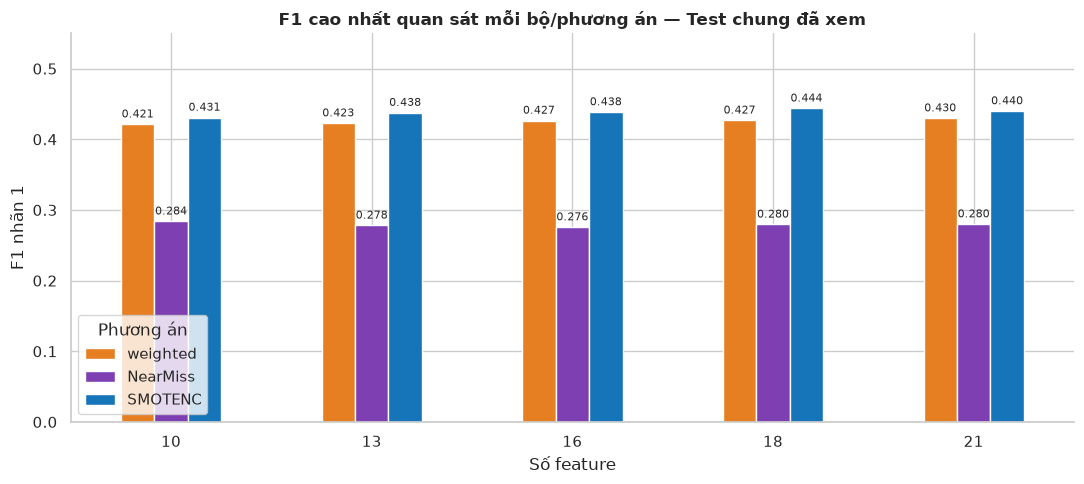

**Kết quả chạy hiện tại:** F1 cao nhất quan sát=0.443787; XGBoost/reduced_18/SMOTENC/keep_duplicates; Precision=0.397568, Recall=0.502166. Kết quả đối chiếu trên Test đã xem, chưa xác nhận tối ưu.

{'status': 'passed', 'configurations': 120, 'metric_rows': 240, 'new_fits': 120, 'reused': 0, 'common_test_rows': 20568, 'test_rows': 23333, 'test_unchanged': True, 'new_saved_predictions_checked': True, 'sampling_train_only': True, 'source_metrics_unrounded': True}

In [22]:
comparison5_out = BASE / "comparison_10_13_16_18_21"
if not (comparison5_out / "verification.json").is_file():
    run_comparison(pandas_context,BASE,FEATURES,SEED)
comparison5_all = pd.read_csv(comparison5_out / "all_metrics.csv")
comparison5_wide = pd.read_csv(comparison5_out / "common_comparison_wide.csv")
assert comparison5_all.Config.nunique() == 120 and len(comparison5_wide) == 40
for feature_count in [10, 13, 16, 18, 21]:
    display(Markdown(f"### Bộ {feature_count} — F1 và chênh lệch trên Test chung"))
    display(comparison5_wide[comparison5_wide.Features == feature_count][
        ["Dataset", "Model", "F1_weighted", "F1_NearMiss", "F1_SMOTENC", "Delta_F1_NearMiss", "Delta_F1_SMOTENC"]
    ].round(6))
    for dataset in ["keep_duplicates", "no_duplicates"]:
        display(Markdown(f"**Precision / Recall / F1 — {feature_count} biến, {dataset}**"))
        with pd.option_context("display.max_columns", None):
            display(comparison5_wide[
                (comparison5_wide.Features == feature_count) & (comparison5_wide.Dataset == dataset)
            ][["Model"] + [f"{metric}_{method}" for method in ["weighted", "NearMiss", "SMOTENC"]
                          for metric in ["Precision", "Recall", "F1"]]].round(6))
comparison5_best = (
    comparison5_all[comparison5_all.TestView == "common"]
    .sort_values(["F1", "Config"], ascending=[False, True])
    .groupby(["Features", "Method"], sort=False).head(1)
    .sort_values(["Features", "Method"])
)
comparison5_best.to_csv(comparison5_out / "best_observed_by_feature_method.csv", index=False)
display(Markdown("### F1 cao nhất quan sát mỗi bộ/phương án — mô hình và bản Train có thể khác nhau"))
display(comparison5_best[["Features", "Method", "Dataset", "Model", "Precision", "Recall", "F1"]].round(6))
plot5 = comparison5_best.pivot(index="Features", columns="Method", values="F1")[["weighted", "NearMiss", "SMOTENC"]]
ax = plot5.plot.bar(figsize=(11, 5), color=[ORANGE, PURPLE, BLUE], rot=0)
ax.set(title="F1 cao nhất quan sát mỗi bộ/phương án — Test chung đã xem",
       xlabel="Số feature", ylabel="F1 nhãn 1", ylim=(0, 0.55))
ax.legend(title="Phương án")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
fig = ax.figure
fig.tight_layout()
save_and_show_figure("comparison5_best_observed_f1", fig)
common_results=comparison5_all[comparison5_all.TestView=="common"]
leader=common_results.sort_values("F1",ascending=False).iloc[0]
note(f"**Kết quả chạy hiện tại:** F1 cao nhất quan sát={leader.F1:.6f}; {leader.Model}/{leader.FeatureSet}/{leader.Method}/{leader.Dataset}; Precision={leader.Precision:.6f}, Recall={leader.Recall:.6f}. Kết quả đối chiếu trên Test đã xem, chưa xác nhận tối ưu.")
display(json.loads((comparison5_out / "verification.json").read_text(encoding="utf-8")))


## Đối chứng đa số và chi tiết lấy mẫu bộ 10
Mốc luôn dự đoán 0 cho thấy vì sao Accuracy riêng lẻ không đủ. Bảng chi tiết giữ so sánh weighted/NearMiss/SMOTENC ở bộ 10 trên cùng Test và số hồ sơ lấy mẫu trên Train; các kết quả này nằm trong 120 cấu hình, không huấn luyện thêm.


In [23]:
test_y=joined.loc[joined.split.eq("test")&joined.row_id.isin(dedup_ids),TARGET].to_numpy()
display(pd.DataFrame([{"Mô hình":"Luôn dự đoán 0","TestRows":len(test_y),"Accuracy":float((test_y==0).mean()),"Precision":0.,"Recall":0.,"F1":0.}]))
display(pd.read_csv(comparison5_out/"train_counts_new_arms.csv").query("FeatureSet == 'replacement_10'"))
display(comparison5_all.query("Features == 10 and TestView == 'common'")[["Dataset","Method","Model","Accuracy","Precision","Recall","F1"]].round(6))


,Mô hình,TestRows,Accuracy,Precision,Recall,F1
0,Luôn dự đoán 0,20568,0.876556,0.0,0.0,0.0


,FeatureSet,Dataset,Method,OriginalRows,OriginalClass0,OriginalClass1,SampledRows,SampledClass0,SampledClass1
0,replacement_10,keep_duplicates,weighted,93329,83137,10192,93329,83137,10192
1,replacement_10,no_duplicates,weighted,82258,72104,10154,82258,72104,10154
2,replacement_10,keep_duplicates,NearMiss,93329,83137,10192,20384,10192,10192
3,replacement_10,no_duplicates,NearMiss,82258,72104,10154,20308,10154,10154
4,replacement_10,keep_duplicates,SMOTENC,93329,83137,10192,166274,83137,83137
5,replacement_10,no_duplicates,SMOTENC,82258,72104,10154,144208,72104,72104


,Dataset,Method,Model,Accuracy,Precision,Recall,F1
1,keep_duplicates,weighted,LogisticRegression,0.732060,0.283634,0.767231,0.414160
3,keep_duplicates,weighted,DecisionTree,0.735025,0.284082,0.754234,0.412716
5,keep_duplicates,weighted,RandomForest,0.727052,0.280074,0.771170,0.410913
7,keep_duplicates,weighted,XGBoost,0.725447,0.278000,0.766443,0.408009
9,no_duplicates,weighted,LogisticRegression,0.746840,0.293434,0.746357,0.421252
11,no_duplicates,weighted,DecisionTree,0.737699,0.286292,0.753446,0.414922
13,no_duplicates,weighted,RandomForest,0.744506,0.292164,0.751871,0.420809
15,no_duplicates,weighted,XGBoost,0.739984,0.288000,0.751477,0.416412
17,keep_duplicates,NearMiss,LogisticRegression,0.492026,0.167046,0.781410,0.275250
19,keep_duplicates,NearMiss,DecisionTree,0.341550,0.137358,0.820796,0.235334


## Kiểm tra đa cộng tuyến của bộ 10
Mã hóa BPCholState bằng dummy, rồi tính VIF trên Train của bộ 10. Đây là kiểm tra cấu trúc đầu vào, không phải thước đo hiệu quả dự đoán. Bảng VIF cho 21 biến gốc đã trình bày ở phần chuẩn bị đặc trưng.


In [24]:
cols=selection_sets["replacement_10"]
x10=train_data.copy()
x10["BPCholState"]=2*x10.HighBP+x10.HighChol
x10["AgeBMI"]=(x10.Age*5+17)*x10.BMI
x10["LowEducationLowIncome"]=((x10.Education<=3)&(x10.Income<=3)).astype(int)
x10["PoorHealthDiffWalk"]=((x10.GenHlth>=4)&x10.DiffWalk.eq(1)).astype(int)
x10=x10[cols]
e10=pd.get_dummies(x10,columns=["BPCholState"],drop_first=True,dtype=float).astype(float)
z10=(e10.to_numpy()-e10.mean().to_numpy())/e10.std(ddof=0).to_numpy()
vif10=[]
for j,name in enumerate(e10.columns):
    other=np.delete(z10,j,axis=1)
    residual=z10[:,j]-other@np.linalg.lstsq(other,z10[:,j],rcond=None)[0]
    fraction=float(residual@residual/(z10[:,j]@z10[:,j]))
    vif10.append({"Biến sau mã hóa":name,"VIF":np.inf if fraction<1e-12 else 1/fraction})
display(pd.DataFrame(vif10).sort_values("VIF",ascending=False))


,Biến sau mã hóa,VIF
3,GenHlth,1.798343
5,PhysHlth,1.736727
8,PoorHealthDiffWalk,1.706802
11,BPCholState_3,1.366803
4,MentHlth,1.262303
6,AgeBMI,1.218154
10,BPCholState_2,1.201010
9,BPCholState_1,1.143168
1,HeartDiseaseorAttack,1.129713
2,PhysActivity,1.093194


## Confusion matrix và đối chiếu 24 kết quả lịch sử
Giữ đối chứng lịch sử ở độ chính xác gốc đã lưu. Ma trận của hai cấu hình dẫn đầu được dựng từ dự đoán đầy đủ, không suy từ chỉ số làm tròn. Các bản ghi lịch sử có thể trùng thiết kế với lượt final; không gọi tổng số bản ghi là số thiết kế độc lập.


### Bảng đối chứng lịch sử
24 kết quả từ lượt nghiên cứu trước được giữ thành bảng dữ liệu cố định, làm tròn theo nguồn cũ; không huấn luyện lại ở cell này.


In [25]:
historical_common_metrics=pd.DataFrame([{'Rank': 1, 'Dataset': 'keep_duplicates', 'Features': 18, 'Model': 'DecisionTree', 'Accuracy': 0.7031, 'Precision': 0.2659, 'Recall': 0.798, 'F1-score': 0.3989}, {'Rank': 2, 'Dataset': 'keep_duplicates', 'Features': 21, 'Model': 'DecisionTree', 'Accuracy': 0.7022, 'Precision': 0.265, 'Recall': 0.7968, 'F1-score': 0.3978}, {'Rank': 3, 'Dataset': 'keep_duplicates', 'Features': 16, 'Model': 'DecisionTree', 'Accuracy': 0.6974, 'Precision': 0.2615, 'Recall': 0.7956, 'F1-score': 0.3936}, {'Rank': 4, 'Dataset': 'keep_duplicates', 'Features': 18, 'Model': 'XGBoost', 'Accuracy': 0.7353, 'Precision': 0.2883, 'Recall': 0.779, 'F1-score': 0.4208}, {'Rank': 5, 'Dataset': 'keep_duplicates', 'Features': 18, 'Model': 'RandomForest', 'Accuracy': 0.7339, 'Precision': 0.2867, 'Recall': 0.7767, 'F1-score': 0.4188}, {'Rank': 6, 'Dataset': 'keep_duplicates', 'Features': 16, 'Model': 'RandomForest', 'Accuracy': 0.7315, 'Precision': 0.2846, 'Recall': 0.7763, 'F1-score': 0.4165}, {'Rank': 7, 'Dataset': 'keep_duplicates', 'Features': 21, 'Model': 'RandomForest', 'Accuracy': 0.7344, 'Precision': 0.287, 'Recall': 0.7759, 'F1-score': 0.4191}, {'Rank': 8, 'Dataset': 'keep_duplicates', 'Features': 21, 'Model': 'XGBoost', 'Accuracy': 0.7355, 'Precision': 0.2873, 'Recall': 0.772, 'F1-score': 0.4188}, {'Rank': 9, 'Dataset': 'keep_duplicates', 'Features': 21, 'Model': 'LogisticRegression', 'Accuracy': 0.7327, 'Precision': 0.2849, 'Recall': 0.7716, 'F1-score': 0.4161}, {'Rank': 10, 'Dataset': 'keep_duplicates', 'Features': 16, 'Model': 'XGBoost', 'Accuracy': 0.733, 'Precision': 0.285, 'Recall': 0.7708, 'F1-score': 0.4161}, {'Rank': 11, 'Dataset': 'no_duplicates', 'Features': 18, 'Model': 'DecisionTree', 'Accuracy': 0.7267, 'Precision': 0.2794, 'Recall': 0.7688, 'F1-score': 0.4098}, {'Rank': 12, 'Dataset': 'keep_duplicates', 'Features': 16, 'Model': 'LogisticRegression', 'Accuracy': 0.7324, 'Precision': 0.2841, 'Recall': 0.7684, 'F1-score': 0.4148}, {'Rank': 13, 'Dataset': 'keep_duplicates', 'Features': 18, 'Model': 'LogisticRegression', 'Accuracy': 0.7322, 'Precision': 0.2839, 'Recall': 0.7684, 'F1-score': 0.4147}, {'Rank': 14, 'Dataset': 'no_duplicates', 'Features': 21, 'Model': 'DecisionTree', 'Accuracy': 0.7279, 'Precision': 0.2799, 'Recall': 0.7653, 'F1-score': 0.4098}, {'Rank': 15, 'Dataset': 'no_duplicates', 'Features': 16, 'Model': 'DecisionTree', 'Accuracy': 0.7254, 'Precision': 0.2778, 'Recall': 0.7653, 'F1-score': 0.4076}, {'Rank': 16, 'Dataset': 'no_duplicates', 'Features': 21, 'Model': 'RandomForest', 'Accuracy': 0.7502, 'Precision': 0.2984, 'Recall': 0.7578, 'F1-score': 0.4282}, {'Rank': 17, 'Dataset': 'no_duplicates', 'Features': 18, 'Model': 'RandomForest', 'Accuracy': 0.7509, 'Precision': 0.2989, 'Recall': 0.7566, 'F1-score': 0.4285}, {'Rank': 18, 'Dataset': 'no_duplicates', 'Features': 21, 'Model': 'LogisticRegression', 'Accuracy': 0.7465, 'Precision': 0.2943, 'Recall': 0.7534, 'F1-score': 0.4233}, {'Rank': 19, 'Dataset': 'no_duplicates', 'Features': 16, 'Model': 'LogisticRegression', 'Accuracy': 0.7468, 'Precision': 0.2944, 'Recall': 0.7527, 'F1-score': 0.4233}, {'Rank': 20, 'Dataset': 'no_duplicates', 'Features': 21, 'Model': 'XGBoost', 'Accuracy': 0.7512, 'Precision': 0.2985, 'Recall': 0.7523, 'F1-score': 0.4274}, {'Rank': 21, 'Dataset': 'no_duplicates', 'Features': 18, 'Model': 'XGBoost', 'Accuracy': 0.7505, 'Precision': 0.2979, 'Recall': 0.7523, 'F1-score': 0.4268}, {'Rank': 22, 'Dataset': 'no_duplicates', 'Features': 18, 'Model': 'LogisticRegression', 'Accuracy': 0.747, 'Precision': 0.2946, 'Recall': 0.7523, 'F1-score': 0.4234}, {'Rank': 23, 'Dataset': 'no_duplicates', 'Features': 16, 'Model': 'XGBoost', 'Accuracy': 0.7506, 'Precision': 0.2978, 'Recall': 0.7515, 'F1-score': 0.4266}, {'Rank': 24, 'Dataset': 'no_duplicates', 'Features': 16, 'Model': 'RandomForest', 'Accuracy': 0.7485, 'Precision': 0.2957, 'Recall': 0.7507, 'F1-score': 0.4243}])
display(historical_common_metrics)


,Rank,Dataset,Features,Model,Accuracy,Precision,Recall,F1-score
0,1,keep_duplicates,18,DecisionTree,0.7031,0.2659,0.7980,0.3989
1,2,keep_duplicates,21,DecisionTree,0.7022,0.2650,0.7968,0.3978
2,3,keep_duplicates,16,DecisionTree,0.6974,0.2615,0.7956,0.3936
3,4,keep_duplicates,18,XGBoost,0.7353,0.2883,0.7790,0.4208
4,5,keep_duplicates,18,RandomForest,0.7339,0.2867,0.7767,0.4188
5,6,keep_duplicates,16,RandomForest,0.7315,0.2846,0.7763,0.4165
6,7,keep_duplicates,21,RandomForest,0.7344,0.2870,0.7759,0.4191
7,8,keep_duplicates,21,XGBoost,0.7355,0.2873,0.7720,0.4188
8,9,keep_duplicates,21,LogisticRegression,0.7327,0.2849,0.7716,0.4161
9,10,keep_duplicates,16,XGBoost,0.7330,0.2850,0.7708,0.4161


### Hàm dựng confusion matrix
Đối chiếu bảng lịch sử và dựng ma trận từ dự đoán đã lưu của cấu hình dẫn đầu.


In [26]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix,precision_score,recall_score,f1_score

def build_priority_confusion(base,historical_reference):
    base=Path(base)
    out=base/"comparison_10_13_16_18_21"/"priority_confusion_144"
    out.mkdir(exist_ok=True)
    current=pd.read_csv(base/"comparison_10_13_16_18_21/common_metrics.csv")
    historical=historical_reference.copy(deep=True)
    assert len(current)==120 and len(historical)==24
    historical=historical.rename(columns={"F1-score":"F1"})
    historical["FeatureSet"]="historical_"+historical.Features.astype(str)
    historical["Method"]="weighted_historical"
    historical["Config"]=[f"historical24__{r.Features}__{r.Dataset}__{r.Model}" for r in historical.itertuples()]
    historical["TestRows"]=20568
    historical["Source"]="historical_project_baseline/historical_common_metrics.csv"
    historical["Study"]="historical24_rounded4"
    current["Study"]="current120_full_precision"
    columns=["Study","Config","Features","FeatureSet","Dataset","Method","Model","TestRows","Accuracy","Precision","Recall","F1","Source"]
    combined=pd.concat([current[columns],historical[columns]],ignore_index=True)
    combined.to_csv(out/"considered_144_results.csv",index=False)
    leader_rows=[]; matrices=[]; ids_reference=None
    # A four-decimal historical score has at most ~0.00005 rounding error.
    for metric,priority in [("Recall","Recall cao nhất"),("F1","F1-score cao nhất")]:
        secondary="F1" if metric=="Recall" else "Recall"
        best=current.sort_values([metric,secondary,"Config"],ascending=[False,False,True]).iloc[0]
        historical_upper=float(historical[metric].max())+0.00005
        assert best[metric]>historical_upper, "Historical rounded score might lead; need exact historical predictions before drawing its matrix."
        file=base/Path(best.Source).parent/(best.Config+"_predictions.npz")
        saved=np.load(file)
        mask=saved["common"].astype(bool)
        ids=saved["row_id"][mask]
        actual=saved["actual"][mask]
        predicted=saved["predicted"][mask]
        assert len(actual)==20568 and int(actual.sum())==2539
        if ids_reference is None:ids_reference=ids
        else:assert np.array_equal(ids_reference,ids)
        matrix=confusion_matrix(actual,predicted,labels=[0,1])
        assert np.array_equal(matrix.ravel(),[best.TN,best.FP,best.FN,best.TP])
        assert np.isclose(best.Precision,precision_score(actual,predicted))
        assert np.isclose(best.Recall,recall_score(actual,predicted))
        assert np.isclose(best.F1,f1_score(actual,predicted))
        row=best.to_dict()
        row.update(Priority=priority,HistoricalMax=float(historical[metric].max()),HistoricalRoundingUpperBound=historical_upper)
        leader_rows.append(row);matrices.append(matrix)
    leaders=pd.DataFrame(leader_rows)
    leaders.to_csv(out/"selected_priorities.csv",index=False)
    np.savez_compressed(out/"confusion_matrices.npz",recall=matrices[0],f1=matrices[1],test_row_ids=ids_reference)
    fig,axes=plt.subplots(1,2,figsize=(13,6))
    maximum=max(int(m.max()) for m in matrices)
    for ax,row,matrix in zip(axes,leader_rows,matrices):
        annotations=np.array([[f"TN\n{matrix[0,0]:,}",f"FP\n{matrix[0,1]:,}"],
                              [f"FN\n{matrix[1,0]:,}",f"TP\n{matrix[1,1]:,}"]])
        sns.heatmap(matrix,annot=annotations,fmt="",cmap="Oranges",vmin=0,vmax=maximum,cbar=False,
                    xticklabels=["0","1"],yticklabels=["0","1"],annot_kws={"size":13},ax=ax)
        ax.set(xlabel="Nhãn dự đoán",ylabel="Nhãn thật",
               title=f"{row['Priority']}\n{row['Model']} | {row['Features']} feature | {row['Method']}\nTrain giữ duplicate\nP={row['Precision']:.4f} | R={row['Recall']:.4f} | F1={row['F1']:.4f}")
        ax.tick_params(axis="y",rotation=0)
    fig.suptitle("Confusion matrix — xét 120 kết quả mới và 24 kết quả cũ",fontsize=15,fontweight="bold")
    fig.text(.5,.025,"Cùng Test không duplicate: n=20.568 | Nhãn 1=2.539, nhãn 0=18.029 | Hàng: thật; cột: dự đoán",ha="center",fontsize=10)
    fig.tight_layout(rect=[0,.06,1,.92])
    image=out/"recall_and_f1_confusion_144.png"
    fig.savefig(image,dpi=140,bbox_inches="tight")
    plt.close(fig)
    report=dict(status="passed",current_records=120,historical_records=24,total_records=144,
                shared_test_rows=20568,labels=[0,1],axes="rows=true;columns=predicted",
                source="saved predictions; no fitting",historical_rounding_checked=True,
                winners_from_current_run=True,
                limitation="120 current and 24 historical records include repeated design types; retrospective Test comparison, not independent selection.")
    (out/"verification.json").write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding="utf-8")
    return leaders,image,out


,Priority,Features,Dataset,Method,Model,TN,FP,FN,TP,Precision,Recall,F1
0,Recall cao nhất,18,keep_duplicates,NearMiss,XGBoost,3769,14260,214,2325,0.140187,0.915715,0.243150
1,F1-score cao nhất,18,keep_duplicates,SMOTENC,XGBoost,16097,1932,1264,1275,0.397568,0.502166,0.443787


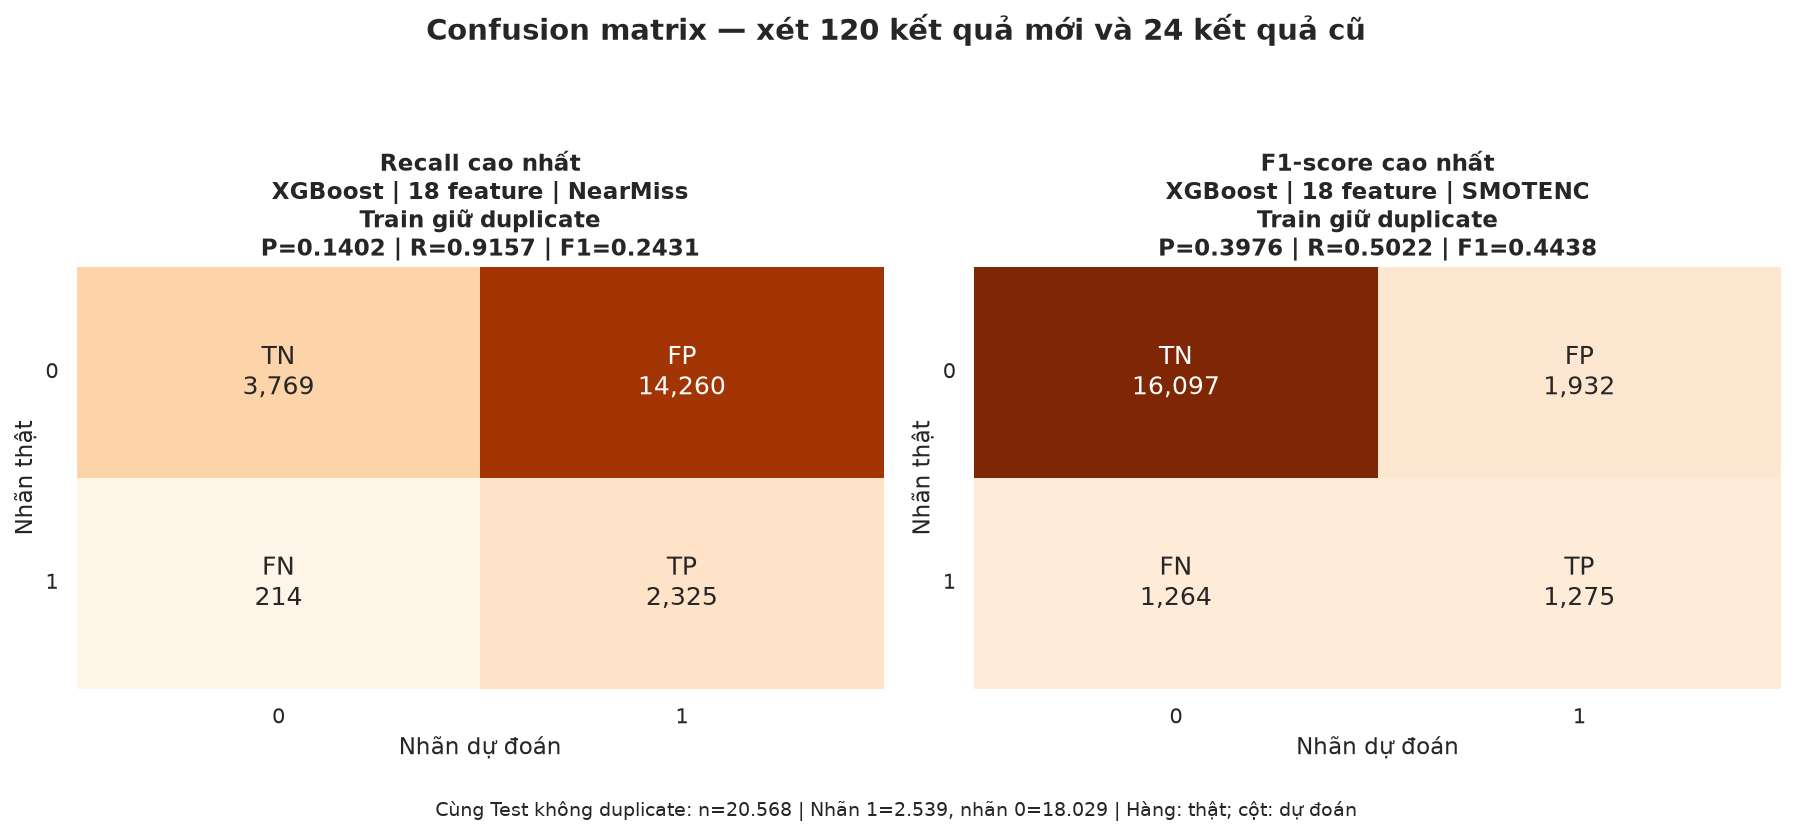

{'status': 'passed', 'current_records': 120, 'historical_records': 24, 'total_records': 144, 'shared_test_rows': 20568, 'labels': [0, 1], 'axes': 'rows=true;columns=predicted', 'source': 'saved predictions; no fitting', 'historical_rounding_checked': True, 'winners_from_current_run': True, 'limitation': '120 current and 24 historical records include repeated design types; retrospective Test comparison, not independent selection.'}

In [27]:
priority144_leaders,priority144_image,priority144_out=build_priority_confusion(BASE,historical_common_metrics)

display(priority144_leaders[
    ["Priority", "Features", "Dataset", "Method", "Model", "TN", "FP", "FN", "TP", "Precision", "Recall", "F1"]
].round(6))
from IPython.display import Image
display(Image(filename=str(priority144_image)))
display(json.loads((priority144_out / "verification.json").read_text(encoding="utf-8")))


# VII. Phân tích hồi quy Logistic
Với vector đặc trưng đã biến đổi $z$, mô hình có $\log(p/(1-p))=\beta_0+\sum_j\beta_j z_j$ và $p=1/(1+e^{-\eta})$. Ngưỡng phân loại cố định là 0,5.

Dùng mô hình weighted/full_21/Train giữ duplicate để diễn giải nhất quán, không chọn mô hình theo hệ số đẹp. Với biến số đã chuẩn hóa, exp(β) là tỷ số odds khi tăng một độ lệch chuẩn, giữ các biến khác cố định. Với biến nhị phân là thay đổi 0→1; với dummy là so với mức tham chiếu. Odds khác xác suất.

Mô hình dùng L2 và trọng số lớp, nên các odds ratio mô tả mô hình phân loại có điều chỉnh trọng số. Chúng không phải ước lượng nhân quả hoặc ước lượng dân số theo thiết kế khảo sát. Không báo p-value/CI cổ điển cho mô hình này. Trọng số lớp cũng làm xác suất chưa được hiệu chỉnh cho tần suất dân số.


Intercept: -3.361164628255202


,Biến sau mã hóa,Hệ số beta,Odds ratio
0,numeric__BMI,0.426661,1.532134
1,numeric__MentHlth,-0.035813,0.964821
2,numeric__PhysHlth,-0.016747,0.983392
3,ordinal__Age_4,0.406435,1.501456
4,ordinal__Age_5,0.555955,1.743605
5,ordinal__Age_6,0.797745,2.220528
6,ordinal__Age_7,0.976597,2.655404
7,ordinal__Age_8,1.038971,2.826308
8,ordinal__Education_2,-0.429804,0.650636
9,ordinal__Education_3,-0.569999,0.565526


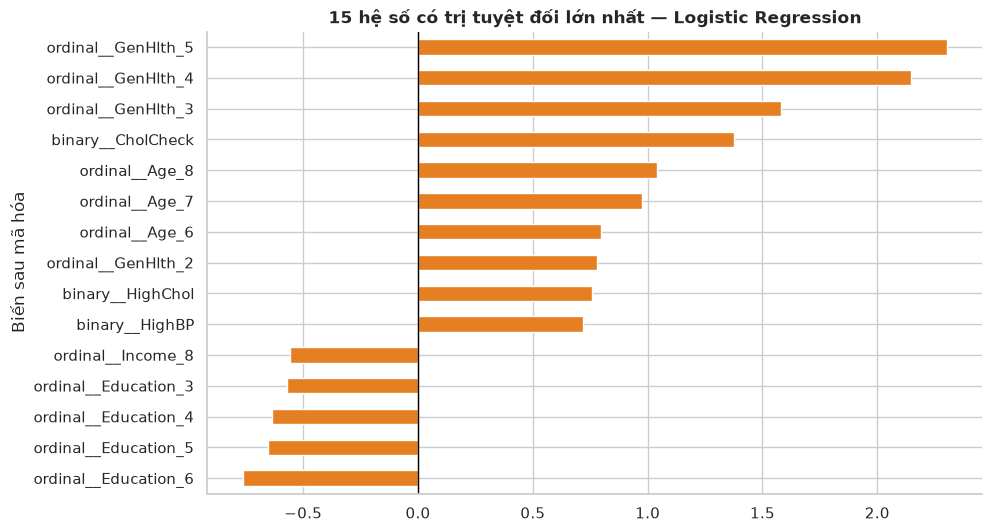

,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
193,0.732692,0.284863,0.771564,0.4161,13111,4918,580,1959


In [28]:
import joblib
reg_key="full_21__keep_duplicates__LogisticRegression__weighted"
reg=joblib.load(comparison5_out/"models"/(reg_key+".joblib"))
coef=reg.named_steps["model"].coef_[0]
terms=reg.named_steps["preprocess"].get_feature_names_out()
odds=pd.DataFrame({"Biến sau mã hóa":terms,"Hệ số beta":coef,"Odds ratio":np.exp(coef)})
display(odds)
print("Intercept:",reg.named_steps["model"].intercept_[0])
odds.to_csv(TABLES/"logistic_coefficients_odds_ratios.csv",index=False)
ax=odds.assign(magnitude=np.abs(coef)).nlargest(15,"magnitude").sort_values("Hệ số beta").plot.barh(x="Biến sau mã hóa",y="Hệ số beta",figsize=(10,6),legend=False)
ax.axvline(0,color="black",linewidth=1)
ax.set_title("15 hệ số có trị tuyệt đối lớn nhất — Logistic Regression")
save_and_show_figure("logistic_coefficients",ax.figure)
display(common_results[(common_results.Config==reg_key)][["Accuracy","Precision","Recall","F1","TN","FP","FN","TP"]])


# VIII. Kết luận và giới hạn
**Câu hỏi về dữ liệu:** khảo sát được chọn theo tuổi 30–59, loại tiểu đường chỉ khi mang thai, xử lý NaN/mã phản hồi và giữ 116.662 hồ sơ. Bản bỏ duplicate có 102.826 hồ sơ. Giữ hồ sơ trùng đặc điểm vì chưa đủ bằng chứng cùng người; chia nhóm theo 21 biến gốc để tránh giao profile gốc giữa Train/Test.

**Câu hỏi về mối liên hệ:** các bảng tổng hợp pandas/NumPy và trực quan Python mô tả mối liên hệ giữa đặc điểm sức khỏe, hành vi, nhân khẩu học và nhãn. Tỷ lệ là mô tả mẫu hoàn chỉnh, không dùng trọng số khảo sát; liên hệ không chứng minh nguyên nhân. Age là mã nhóm tuổi; các biến thứ bậc không mặc nhiên có khoảng cách bằng nhau.

**Câu hỏi về mô hình:** đánh giá đầy đủ 120 cấu hình bằng Precision, Recall, F1 và Accuracy trên cùng Test không duplicate. Không có một mô hình tốt nhất cho mọi mục tiêu: Recall ưu tiên ít bỏ sót, còn Precision/F1 phản ánh đánh đổi báo nhầm. Cell dưới kết luận bằng kết quả thực tế của phiên chạy.

**Giới hạn:** loại dòng thiếu có thể gây thiên lệch chọn mẫu; nhãn tự khai gộp hai tình trạng; dữ liệu từ năm 2015; chưa hiệu chỉnh thiết kế khảo sát; Test đã được xem trong phát triển; bộ đặc trưng được đề xuất từ toàn Train. Không trình bày thứ hạng này như xác nhận độc lập hay công cụ chẩn đoán. Các điểm ngoài IQR được giữ có giải thích, không đồng nghĩa mọi giá trị đã được xác minh về mặt sinh học.


In [29]:
for metric in ["Recall","F1"]:
    winner=common_results.sort_values([metric,"Config"],ascending=[False,True]).iloc[0]
    note(f"**Ưu tiên {metric}:** {winner.Model}, {winner.FeatureSet}, {winner.Method}, {winner.Dataset}; Precision **{winner.Precision:.4f}**, Recall **{winner.Recall:.4f}**, F1 **{winner.F1:.4f}**.")


**Ưu tiên Recall:** XGBoost, reduced_18, NearMiss, keep_duplicates; Precision **0.1402**, Recall **0.9157**, F1 **0.2431**.

**Ưu tiên F1:** XGBoost, reduced_18, SMOTENC, keep_duplicates; Precision **0.3976**, Recall **0.5022**, F1 **0.4438**.

## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ 21 feature và phần lớn quy trình xử lý. Bản này chọn tuổi 30–59, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và nguồn chuyên ngành được dẫn trực tiếp trong bảng căn cứ chọn biến. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.
